# Template 07: SHAP Analysis

**Purpose:** Generate residual + SHAP range plots for top features

**Inputs:**
- results/06_shap_train.parquet
- results/06_shap_test.parquet
- results/05c_predictions_train.parquet
- results/05c_predictions_test.parquet
- data/04c_train_encoded.parquet
- data/04c_test_encoded.parquet

**Outputs:**
- plots/{dataset}_{feature}_residual.png
- plots/{dataset}_{feature}_shap_range.png
- results/07_analysis_summary.yaml

In [1]:
config_path = "config/car_coll/v1"

In [2]:
# Parameters
config_path = "config/car_liab/v1"


In [3]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import yaml
import os
import sys
from pathlib import Path
from datetime import datetime

sys.path.insert(0, str(Path.cwd() / 'lib'))
from utils import setup_notebook_environment
from shap_utils import compute_shap_aggregate, create_residual_plot, create_shap_range_plot, create_fast_shap_summary, create_shap_beeswarm, create_shap_importance_pct
from IPython.display import Image, display

print("########################################")
print("# STAGE 07: SHAP ANALYSIS")
print("########################################")

project_root = setup_notebook_environment()

# Note: SHAP interpretation depends on target_method
# - residual: SHAP values show impact on ratio (PP/GLM correction factor)
# - direct: SHAP values show impact on PP directly

########################################
# STAGE 07: SHAP ANALYSIS
########################################


In [4]:
# Get machine config
pc_num = open("current.pc").read().strip()
pc_id = f"PC{pc_num}"

with open(f"{config_path}/config.yaml") as f:
    cfg = yaml.safe_load(f)
output_base = cfg["machines"][pc_id]["paths"]["output_path"]
shap_cfg = cfg.get("shap_analysis", {})
top_n = shap_cfg.get("top_n_features", 40)
datasets = shap_cfg.get("datasets", ["train", "test"])
resid_cfg = shap_cfg.get("residual_plot", {})
shap_range_cfg = shap_cfg.get("shap_range_plot", {})
print(f"\nConfig: top_n={top_n}")


Config: top_n=40


In [5]:
plots_dir = f"{output_base}/plots"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots: {plots_dir}")

Plots: output/car_liab/v1/plots


In [6]:
# Load ENCODED data (same data used for SHAP computation)
df_train = pd.read_parquet(f"{output_base}/data/04c_train_encoded.parquet")
df_test = pd.read_parquet(f"{output_base}/data/04c_test_encoded.parquet")

print(f"\n* Train encoded: {df_train.shape}")
print(f"* Test encoded: {df_test.shape}")


* Train encoded: (4550028, 151)
* Test encoded: (4539000, 151)


In [7]:
print("\nLoading...")
shap_train = pd.read_parquet(f"{output_base}/results/06_shap_train.parquet")
shap_test = pd.read_parquet(f"{output_base}/results/06_shap_test.parquet")
preds_train = pd.read_parquet(f"{output_base}/results/05c_predictions_train.parquet")
preds_test = pd.read_parquet(f"{output_base}/results/05c_predictions_test.parquet")

print(f"  SHAP train: {shap_train.shape}")
print(f"  SHAP test: {shap_test.shape}")
print(f"  Preds train: {preds_train.shape}")
print(f"  Preds test: {preds_test.shape}")


Loading...


  SHAP train: (10000, 152)
  SHAP test: (4539000, 152)
  Preds train: (4307292, 3)
  Preds test: (4295155, 3)


In [8]:
# Merge train data with predictions
# Use intersection of indices (SHAP is computed on sample)
common_idx = shap_train.index.intersection(preds_train.index)
data_tr = df_train.loc[common_idx].copy()
data_tr['actual'] = preds_train.loc[common_idx, 'actual']
data_tr['pred'] = preds_train.loc[common_idx, 'pred']
data_tr['weight'] = preds_train.loc[common_idx, 'exposure']

fc_tr = shap_train.loc[common_idx].copy()
fc_tr['weight'] = data_tr['weight']
out_tr = data_tr
print(f"Train: {out_tr.shape}")

Train: (9479, 154)


In [9]:
# Merge test data with predictions
# Use intersection of indices
common_idx = shap_test.index.intersection(preds_test.index)
data_te = df_test.loc[common_idx].copy()
data_te['actual'] = preds_test.loc[common_idx, 'actual']
data_te['pred'] = preds_test.loc[common_idx, 'pred']
data_te['weight'] = preds_test.loc[common_idx, 'exposure']

fc_te = shap_test.loc[common_idx].copy()
fc_te['weight'] = data_te['weight']
out_te = data_te
print(f"Test: {out_te.shape}")

Test: (4295155, 154)


In [10]:
print("\nSHAP aggregates...")
shagg, shagg_num, shagg2 = compute_shap_aggregate(fc_tr, weight_col="weight")
print(f"Features: {len(shagg2)}")
print(shagg2.head(10))


SHAP aggregates...
Features: 110
                                     field  total_shap
5                  cef_first_poten_dam_ind  766.889768
2                 cef_est_curr_mi_grp_imps  426.813893
89                            vc_msrp_impa  308.723556
7                      cef_lien_holder_ind  268.558819
55                            vc_doors_raw  237.848635
6                   cef_first_sev_prob_ind  178.321803
29   vc_auto_dimming_rearview_mirror_raw_0  170.468900
57                   vc_drive_type_fwd_ind  147.904456
110                    vc_rear_wiper_raw_0  139.828773
138                  vc_touch_screen_raw_0  128.334154


In [11]:
features = shagg2["field"].head(top_n).tolist()
print(f"\nPlotting {len(features)} features")


Plotting 40 features



SHAP BEESWARM PLOT
Note: Each dot = record. Color shows feature value (red=high, blue=low)
X-axis shows SHAP value impact on prediction


  Creating SHAP beeswarm for 9,479 samples...


  Beeswarm created with 40 features


Saved: output/car_liab/v1/plots/shap_beeswarm.png


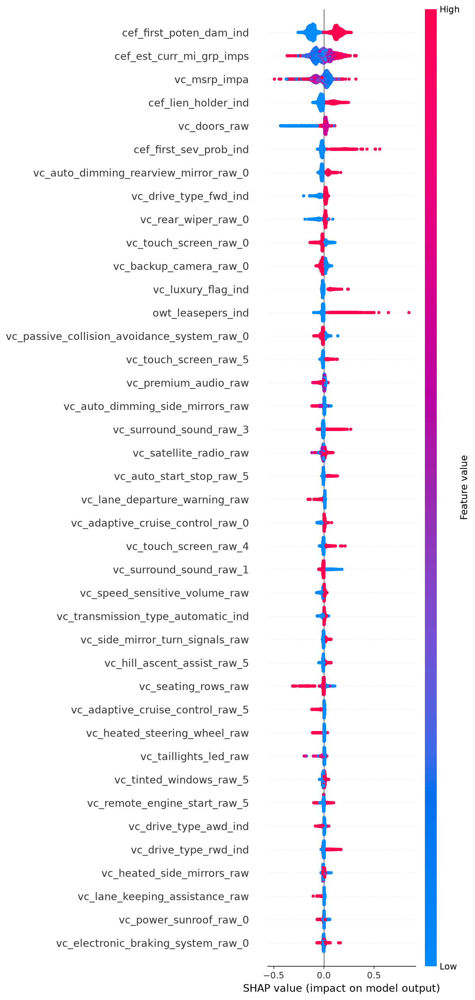

In [12]:
# SHAP Beeswarm Plot (standard - shows feature value impact)
print(f"\n{'='*60}")
print("SHAP BEESWARM PLOT")
print('='*60)
print("Note: Each dot = record. Color shows feature value (red=high, blue=low)")
print("X-axis shows SHAP value impact on prediction")
fig_beeswarm = create_shap_beeswarm(fc_tr, data_tr, top_n=top_n, weight_col='weight', max_display=top_n)
if fig_beeswarm:
    beeswarm_file = f'{plots_dir}/shap_beeswarm.png'
    fig_beeswarm.savefig(beeswarm_file, dpi=150, bbox_inches='tight')
    plt.close(fig_beeswarm)
    print(f"Saved: {beeswarm_file}")
    display(Image(beeswarm_file))
else:
    print("Warning: Could not create SHAP beeswarm plot")



SHAP FEATURE IMPORTANCE (%)
  Creating SHAP importance % chart for 9,479 rows...
  SHAP importance % chart created


Saved: output/car_liab/v1/plots/shap_importance_pct.png


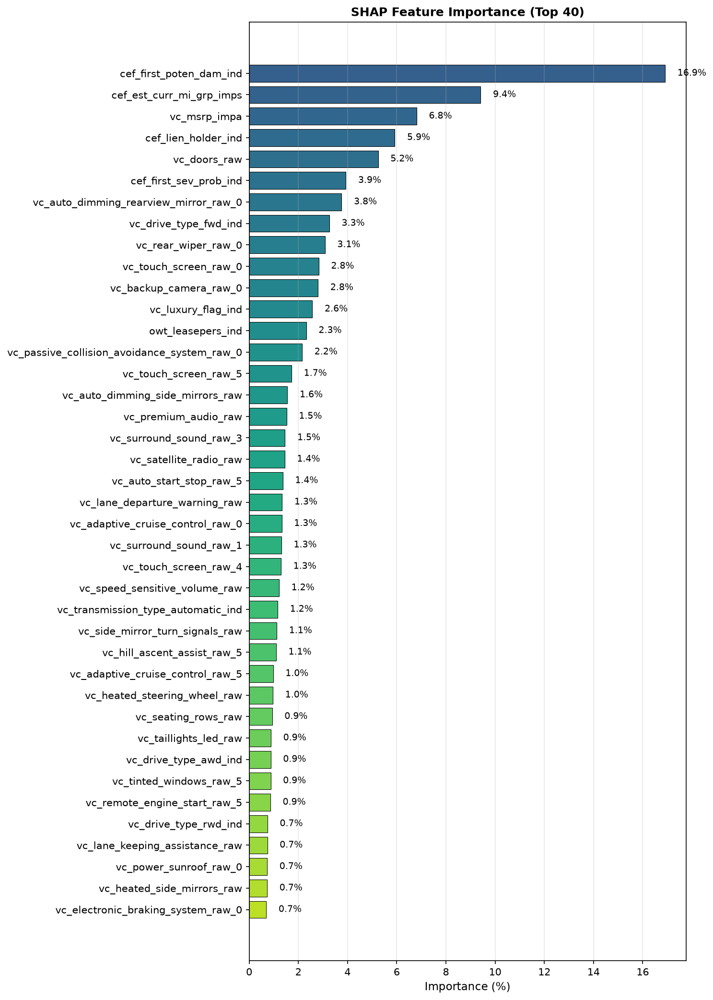

In [13]:
# SHAP Feature Importance (Percentage)
print(f"\n{'='*60}")
print("SHAP FEATURE IMPORTANCE (%)")
print('='*60)
fig_importance = create_shap_importance_pct(fc_tr, top_n=top_n, weight_col='weight')
if fig_importance:
    importance_file = f'{plots_dir}/shap_importance_pct.png'
    fig_importance.savefig(importance_file, dpi=150, bbox_inches='tight')
    plt.close(fig_importance)
    print(f"Saved: {importance_file}")
    display(Image(importance_file))
else:
    print("Warning: Could not create SHAP importance plot")


In [14]:
summary = {"timestamp": datetime.now().isoformat(), "plots": 0}
plots_by_feature = {}

In [15]:
print("="*60)
print("GENERATING PLOTS")
print("="*60)
for i, f in enumerate(features, 1):
    print(f"[{i}/{len(features)}] {f}")
    plots_by_feature[f] = []
    if f not in out_tr.columns or f not in out_te.columns:
        print(f"  WARNING: Feature {f} not found, skipping")
        continue
    if "train" in datasets:
        try:
            fig, _ = create_residual_plot(out_tr, f, "weight", dataset_label="Train", **resid_cfg)
            path = f"{plots_dir}/train_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_tr, data_tr, f, "weight", dataset_label="Train", **shap_range_cfg)
            path = f"{plots_dir}/train_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train SHAP): {e}")
    if "test" in datasets:
        try:
            fig, _ = create_residual_plot(out_te, f, "weight", dataset_label="Test", **resid_cfg)
            path = f"{plots_dir}/test_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_te, data_te, f, "weight", dataset_label="Test", **shap_range_cfg)
            path = f"{plots_dir}/test_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test SHAP): {e}")
print(f"\n[OK] Generated summary")

GENERATING PLOTS
[1/40] cef_first_poten_dam_ind

cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind      weight   act_rate  pred_rate
                     0.0 3388.413628 218.648122 165.163171
                     1.0 2518.855847  41.783006 259.644901


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind       weight   act_rate  pred_rate
                     0.0 1.540147e+06 236.805323 162.064593
                     1.0 1.136186e+06 416.663264 264.689479


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 

[2/40] cef_est_curr_mi_grp_imps

cef_est_curr_mi_grp_imps Summary:
cef_est_curr_mi_grp_imps     weight   act_rate  pred_rate
     (6401.999, 20460.8] 450.287576 855.222975 172.528527
      (20460.8, 31287.2] 315.971489   3.796025 163.078731
      (31287.2, 40196.2] 386.663714  76.954298 170.230972
      (40196.2, 48458.0] 369.964057   0.000000 132.035212
      (48458.0, 55230.0] 478.618511 609.094143 184.286030
      (55230.0, 60125.4] 470.388410  35.681629 186.136659
      (60125.4, 69234.4] 315.376194  48.296131 152.033259
      (69234.4, 84984.0] 524.657055  42.283365 220.943661
      (84984.0, 99629.6] 435.102061   5.742554 216.629826
     (99629.6, 110000.0] 553.698317   0.000000 229.640974
    (110000.0, 120121.2] 303.888194  19.962153 210.442945
    (120121.2, 132000.0] 473.941392 154.734197 178.407151
    (132000.0, 163000.0] 374.595506   0.000000 300.839605
    (163000.0, 194000.0] 231.762549  10.532426 317.560377
    (194000.0, 225000.0] 122.444877   0.000000 360.365315
    (

...

[40/40] vc_electronic_braking_system_raw_0

vc_electronic_braking_system_raw_0 Summary:
 vc_electronic_braking_system_raw_0      weight   act_rate  pred_rate
                                0.0 4349.402578 180.818256 212.150154
                                1.0 1557.866896  38.298686 186.744316


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


vc_electronic_braking_system_raw_0 Summary:
 vc_electronic_braking_system_raw_0       weight   act_rate  pred_rate
                                0.0 1.977074e+06 324.486190 211.462013
                                1.0 6.992587e+05 281.138709 189.148419


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


[OK] Generated summary



DISPLAYING ALL PLOTS

FEATURE: cef_first_poten_dam_ind


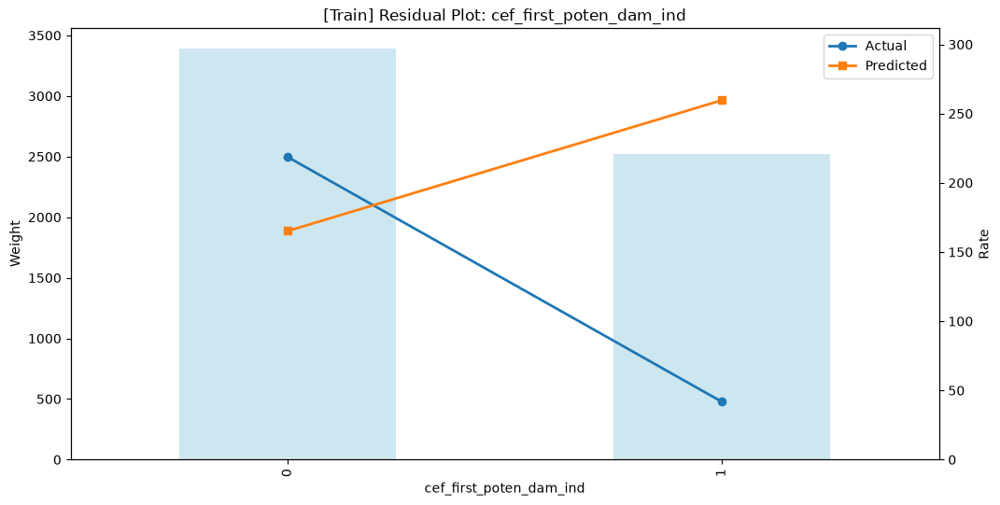

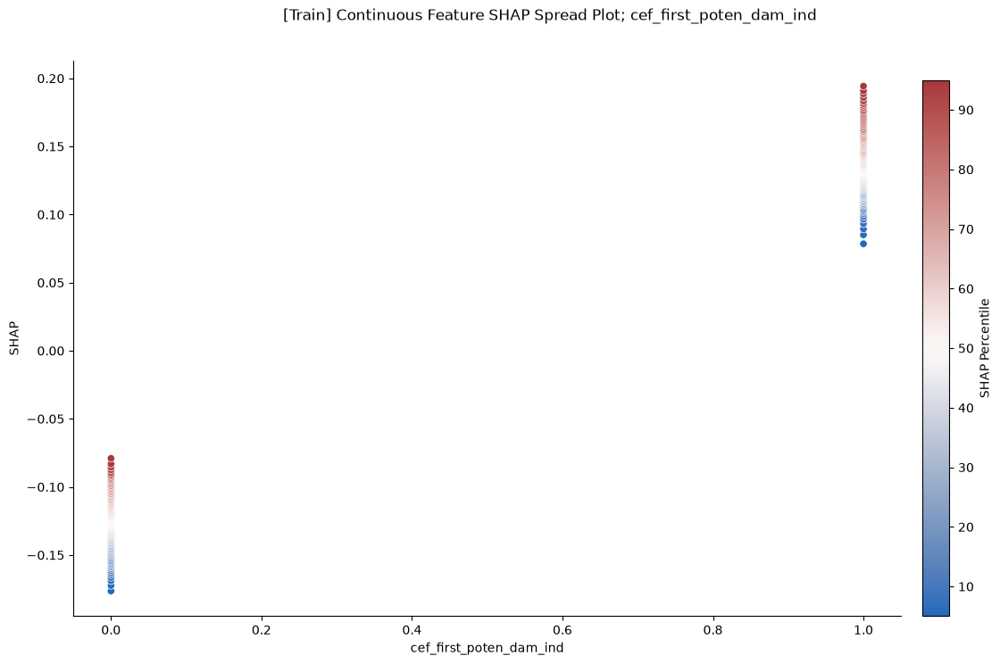

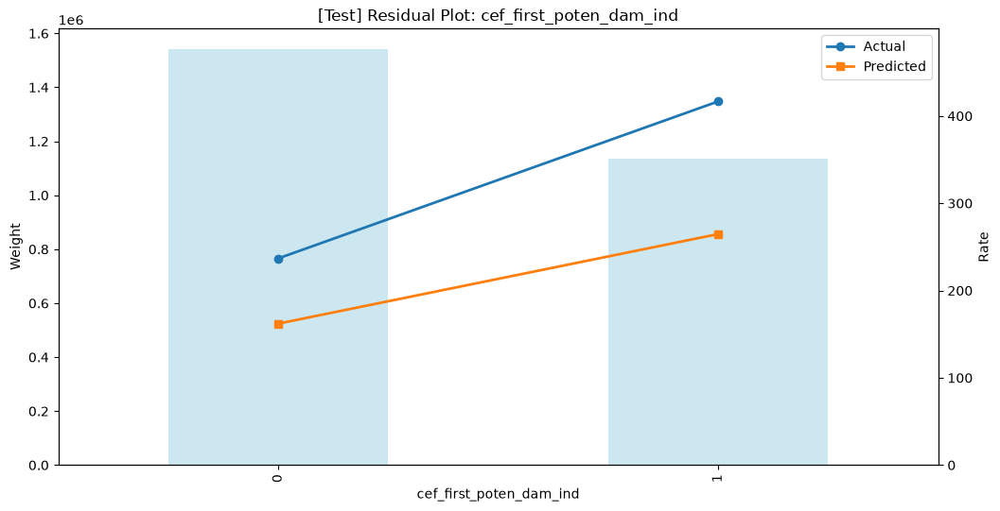

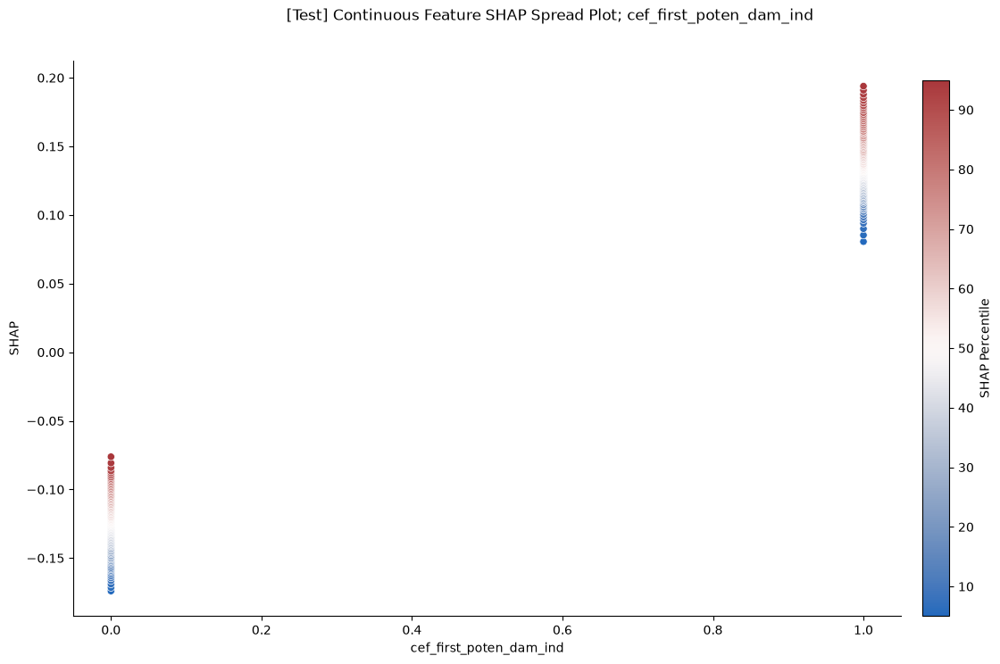


FEATURE: cef_est_curr_mi_grp_imps


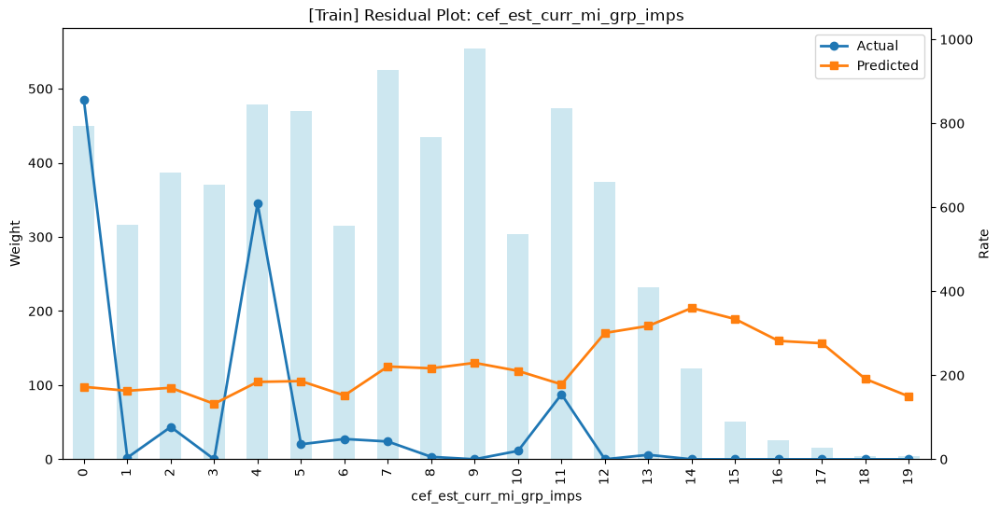

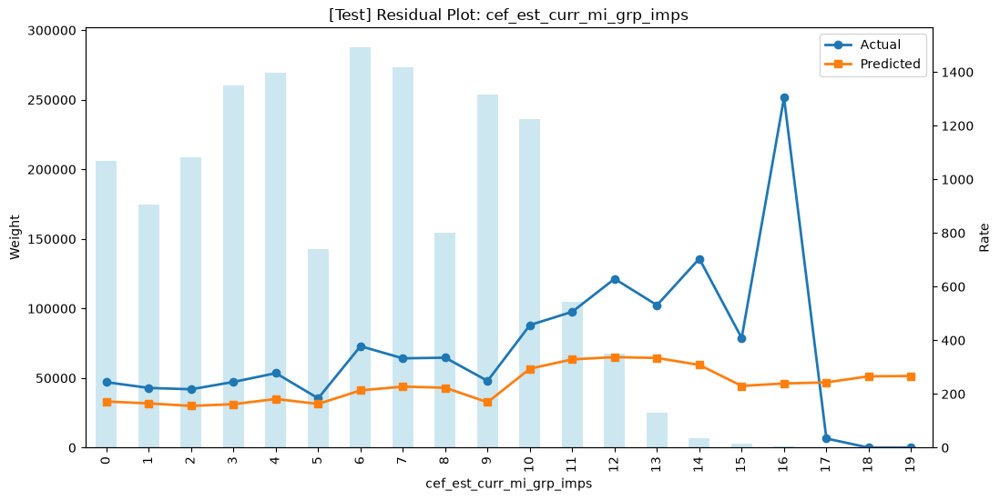


FEATURE: vc_msrp_impa


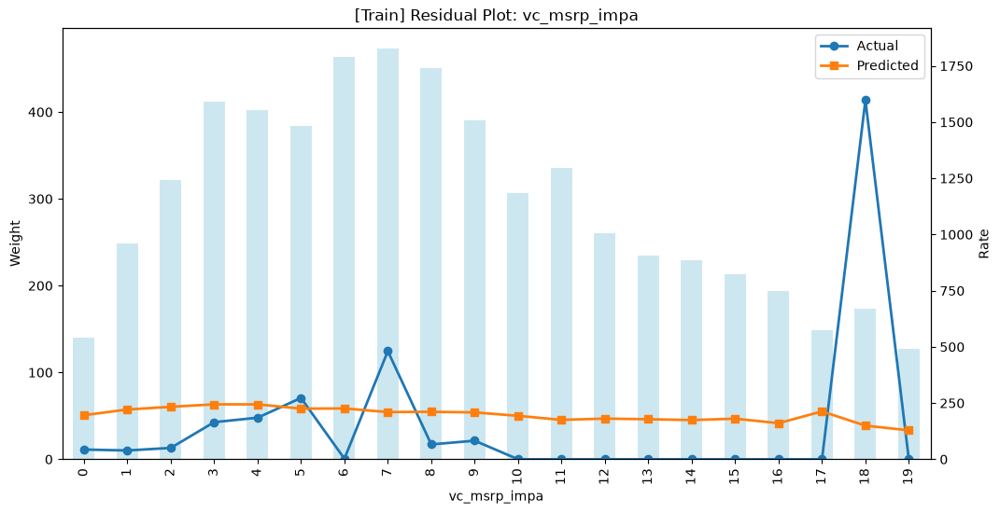

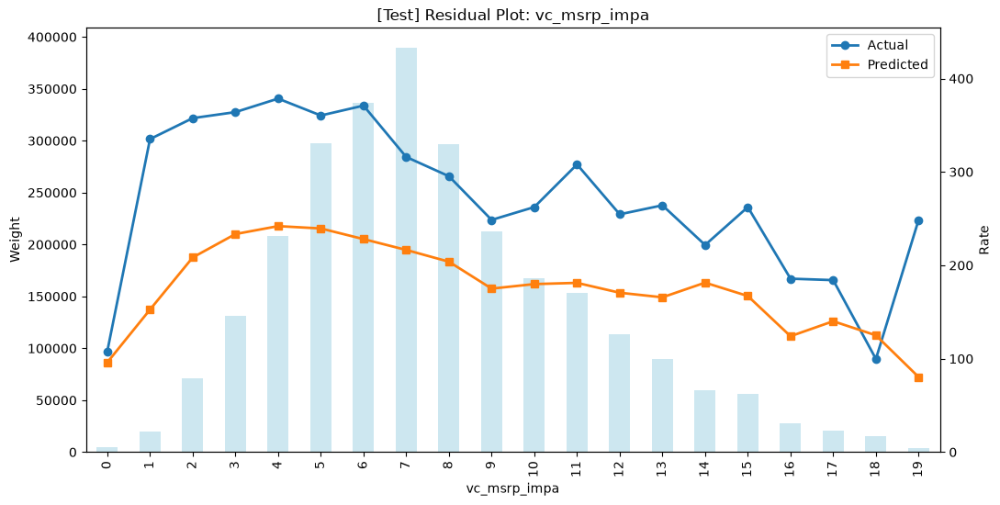


FEATURE: cef_lien_holder_ind


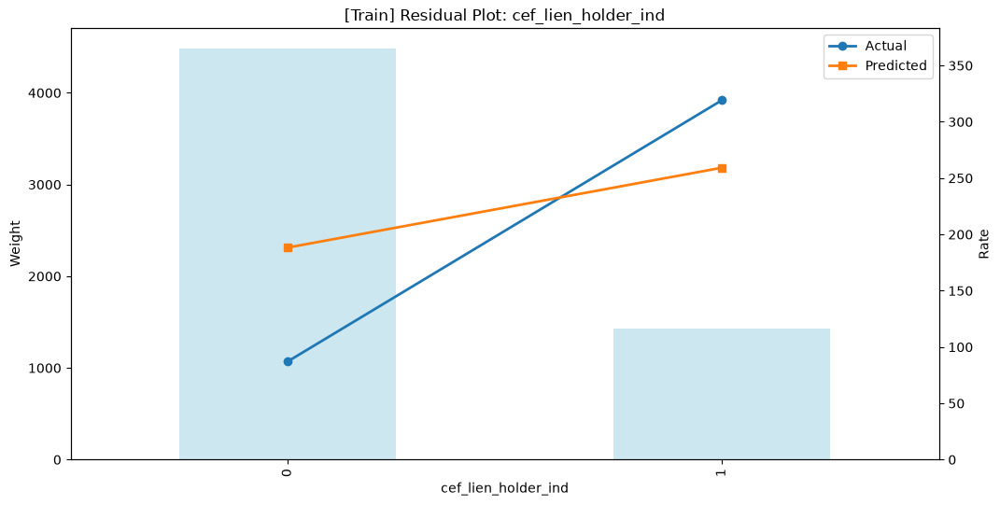

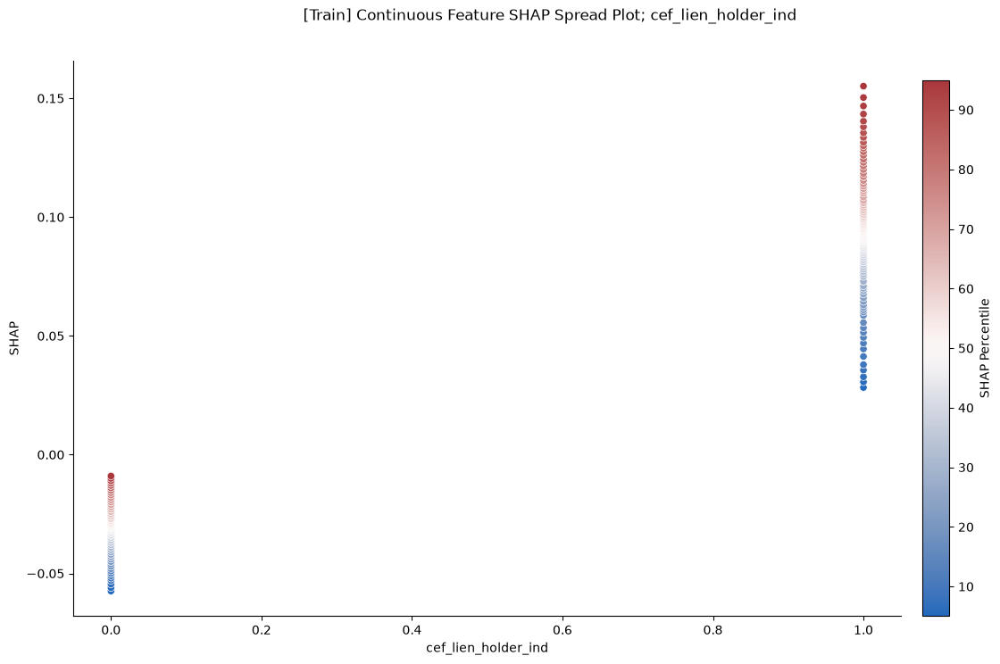

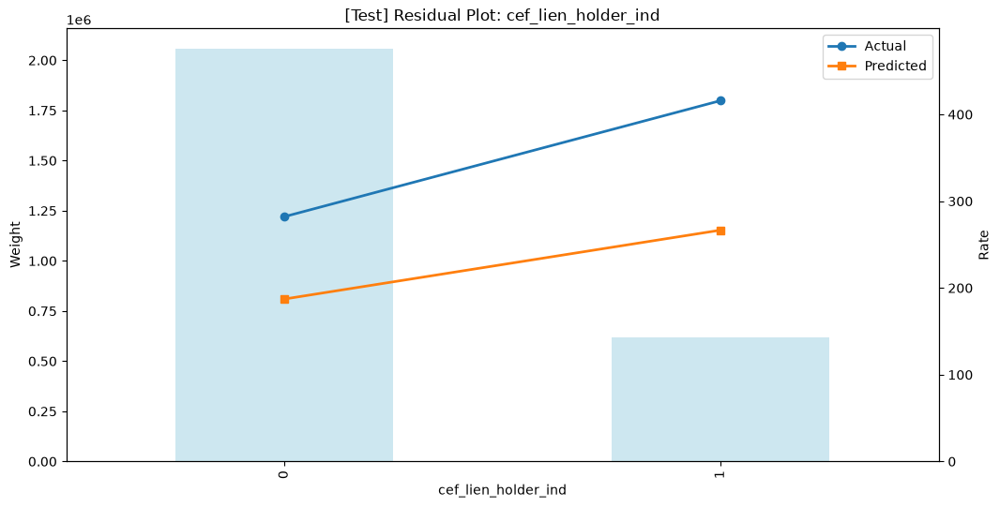

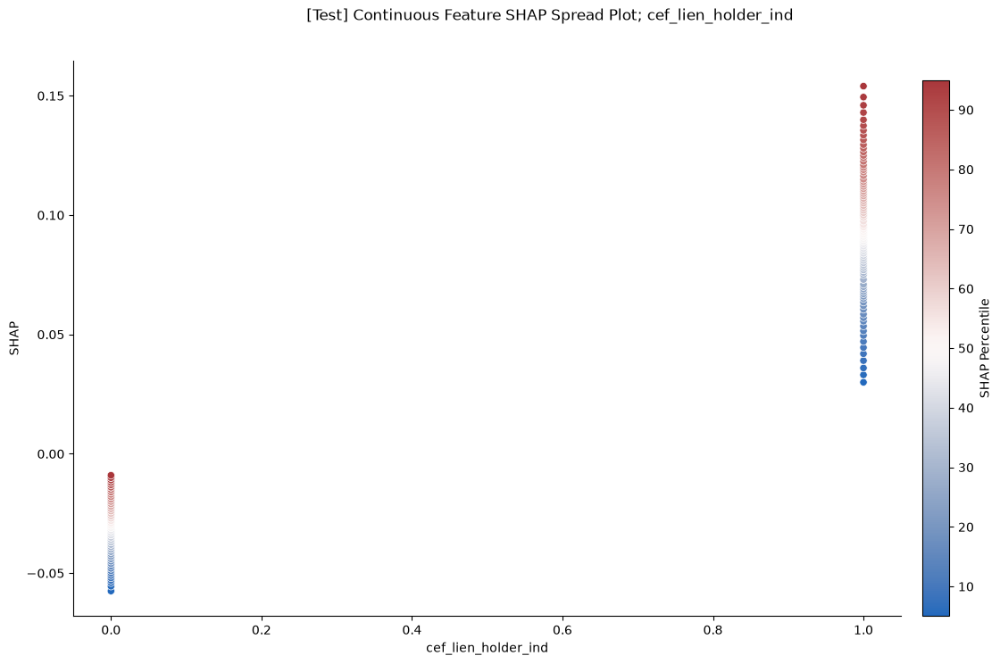


FEATURE: vc_doors_raw


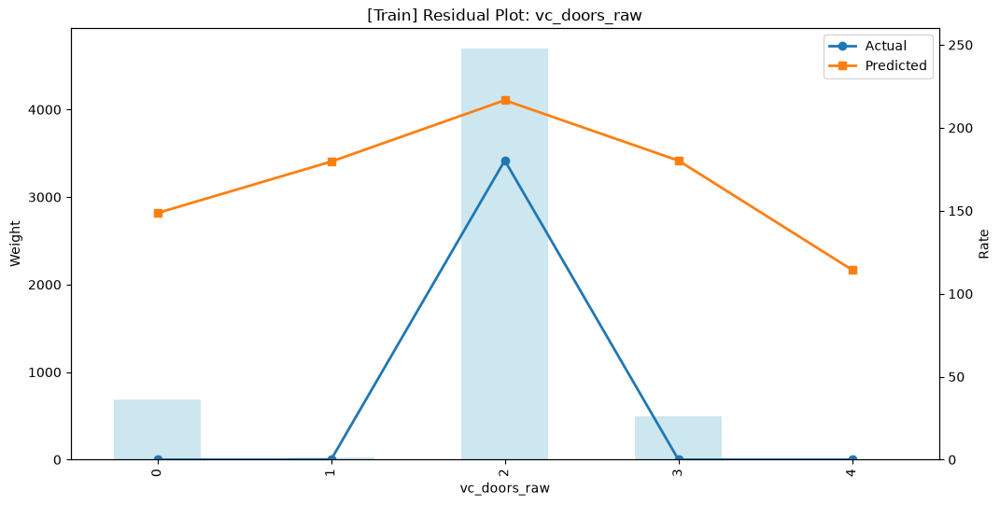

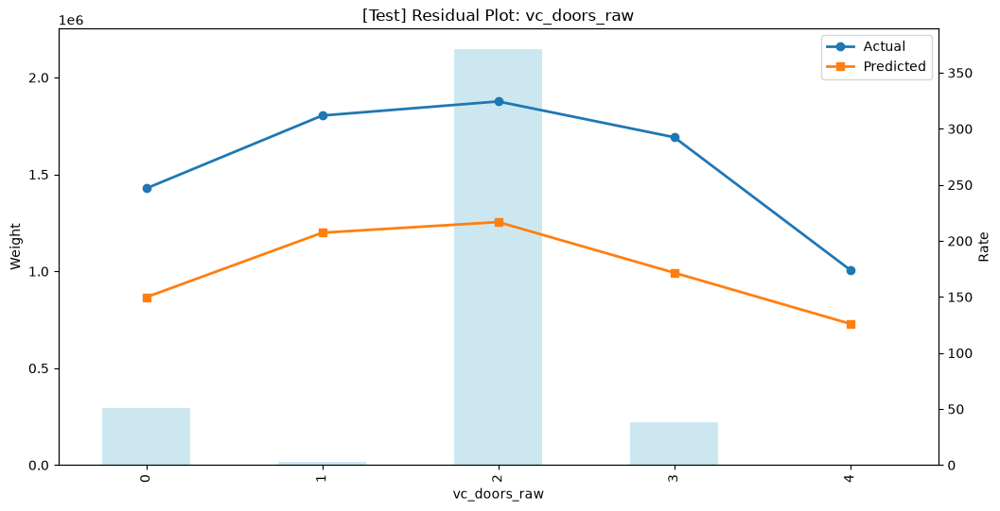

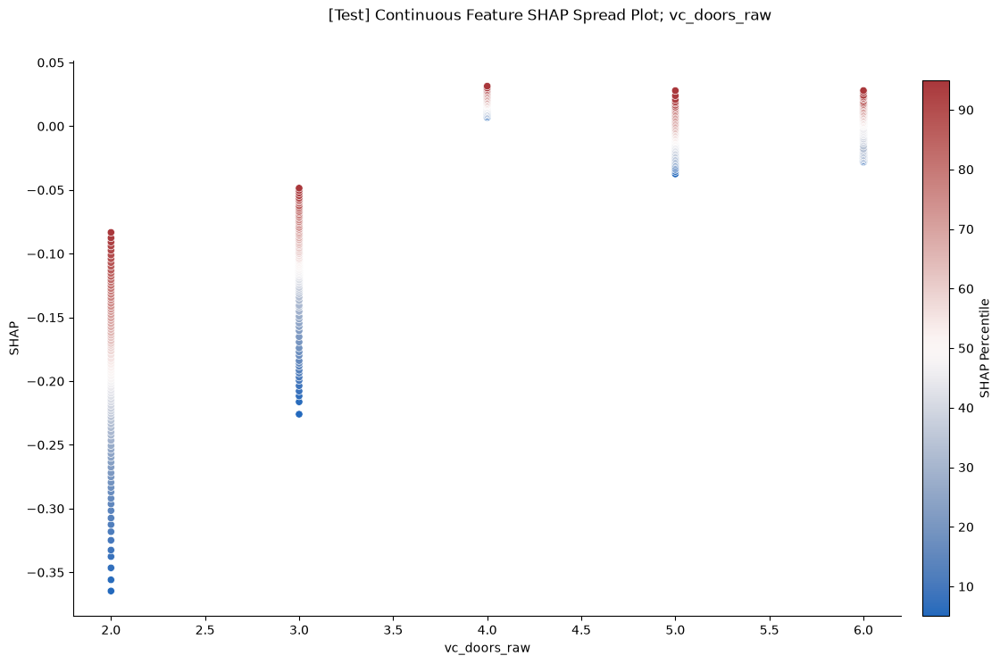


FEATURE: cef_first_sev_prob_ind


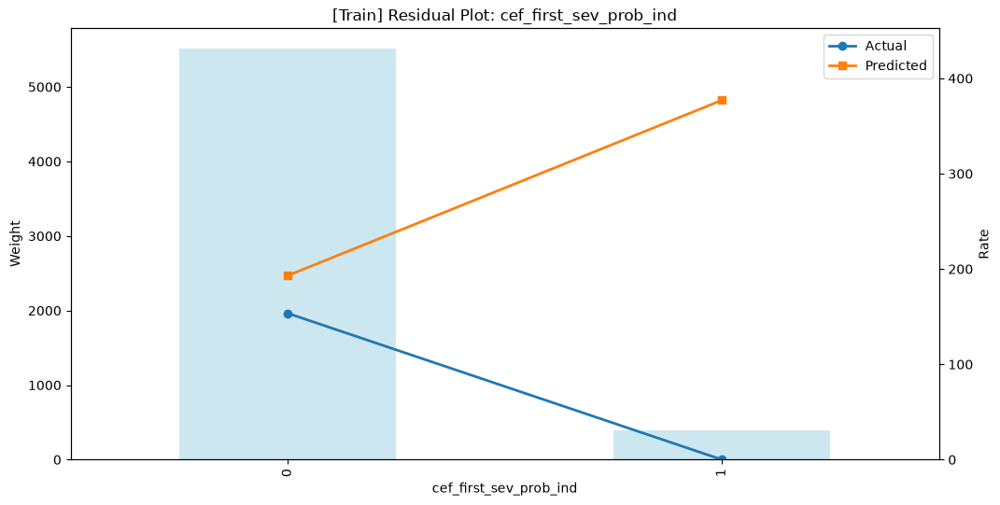

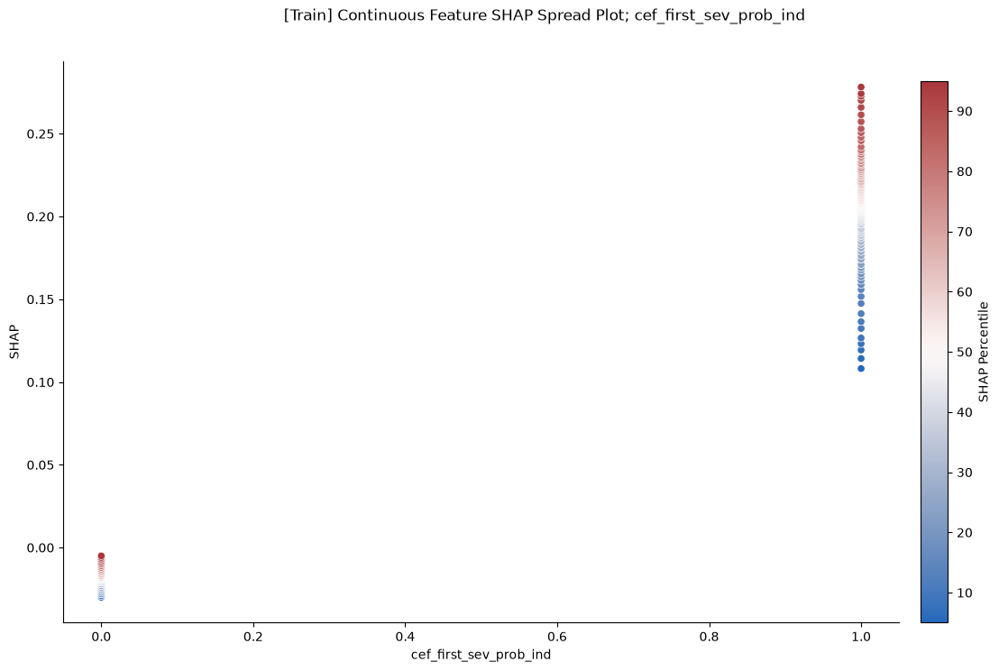

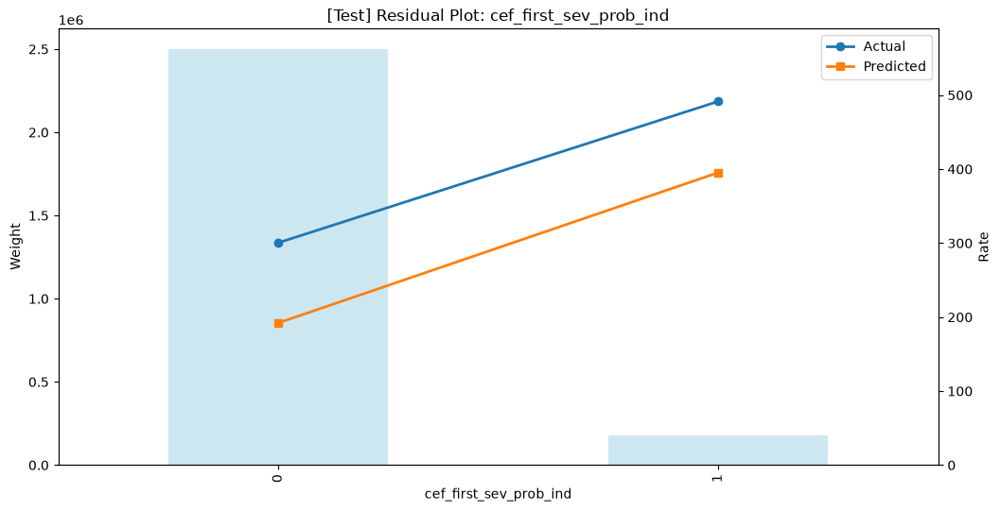

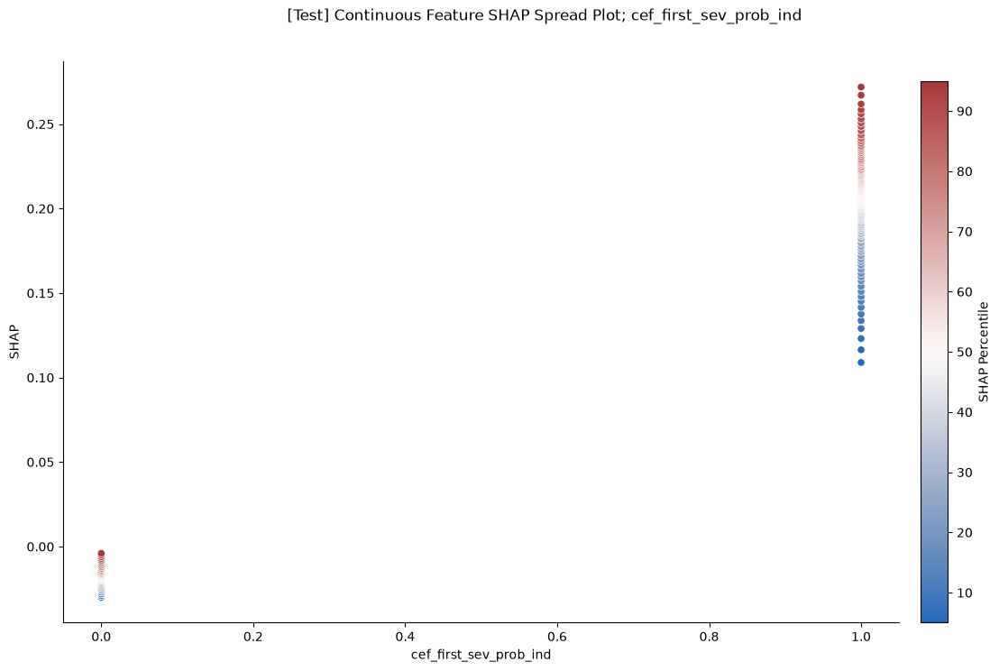


FEATURE: vc_auto_dimming_rearview_mirror_raw_0


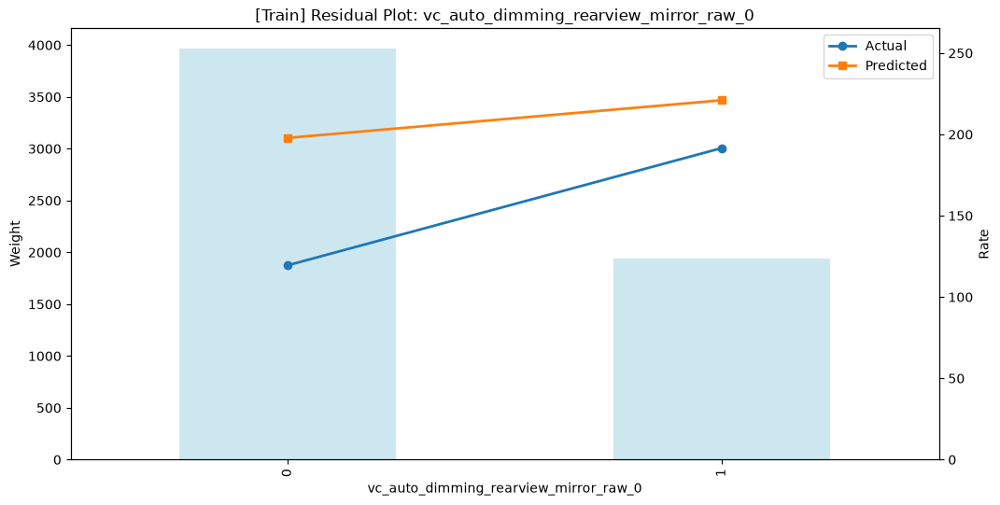

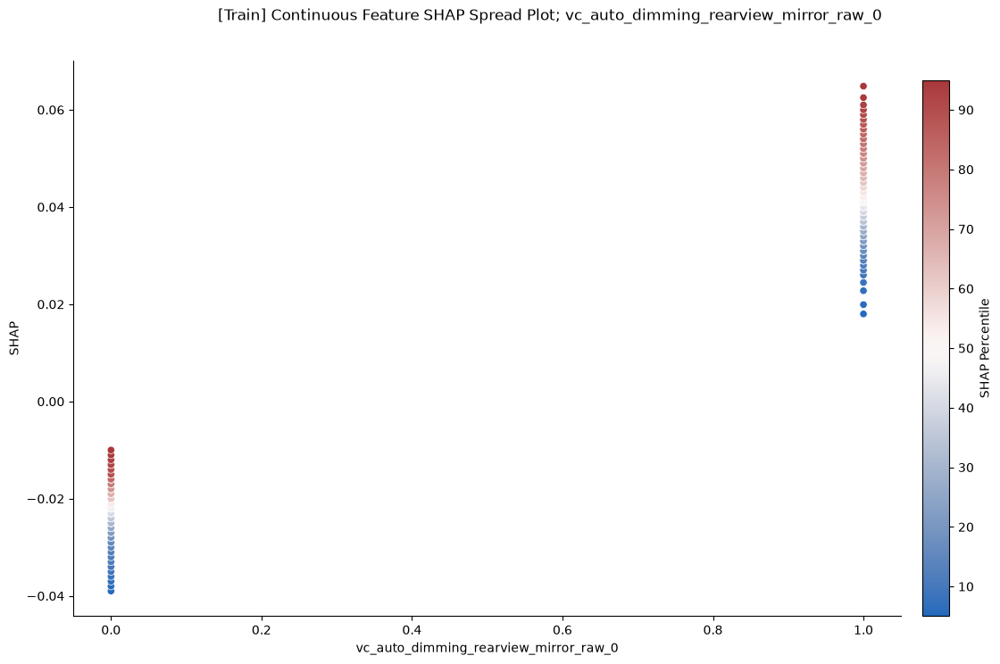

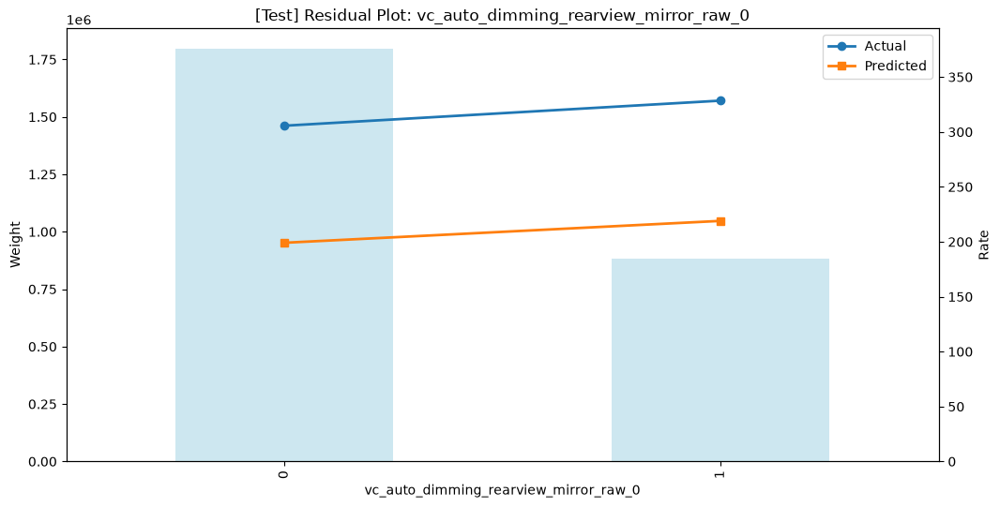

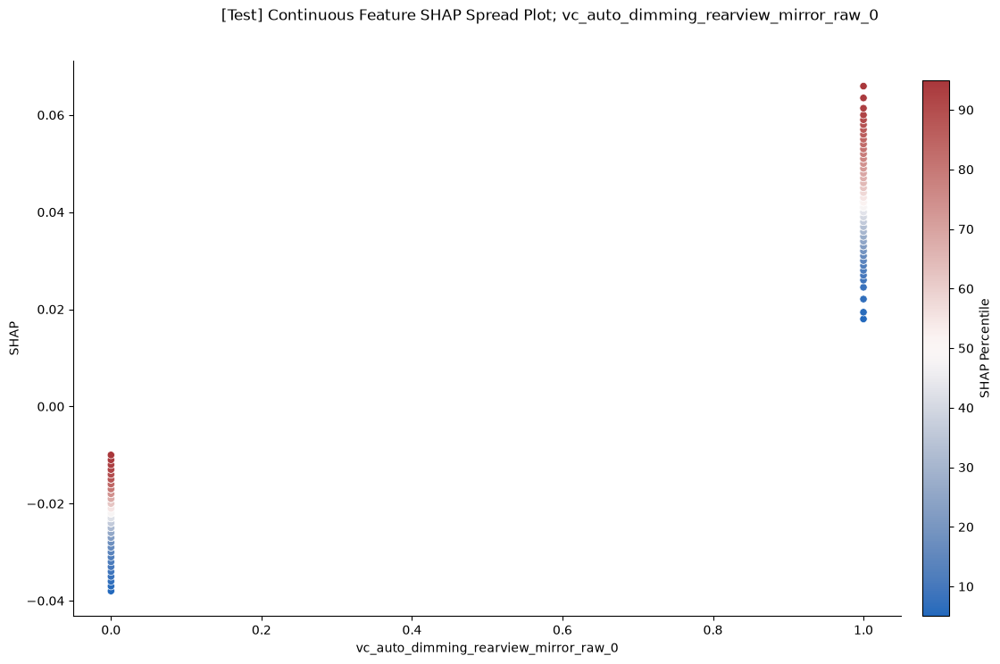


FEATURE: vc_drive_type_fwd_ind


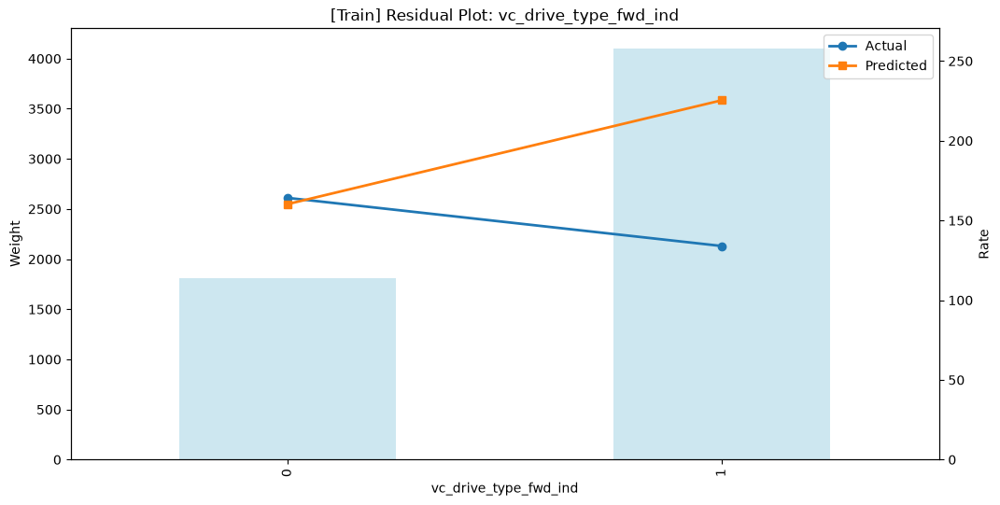

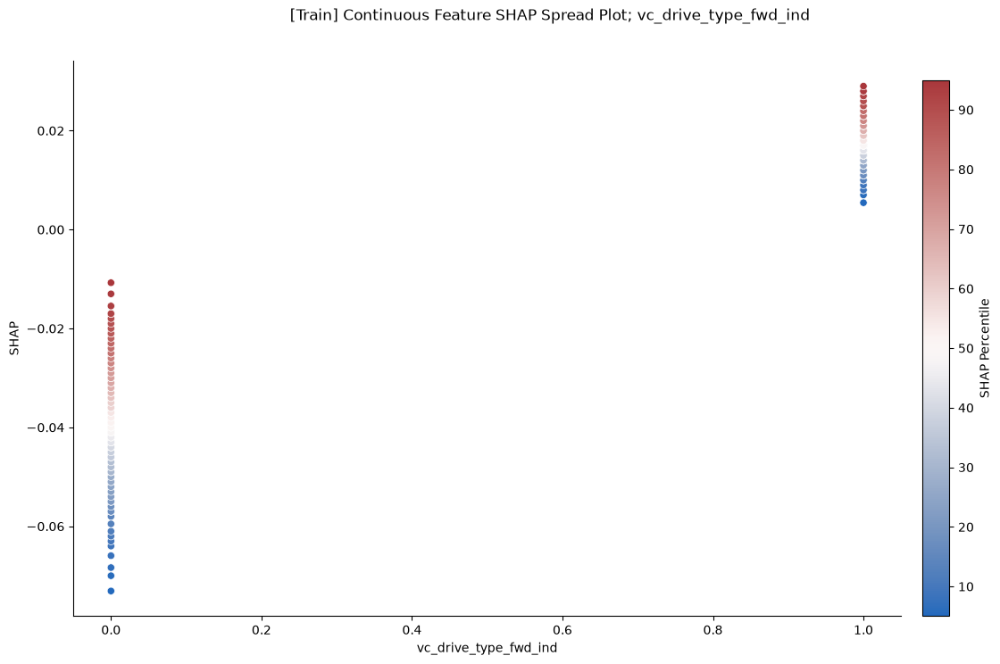

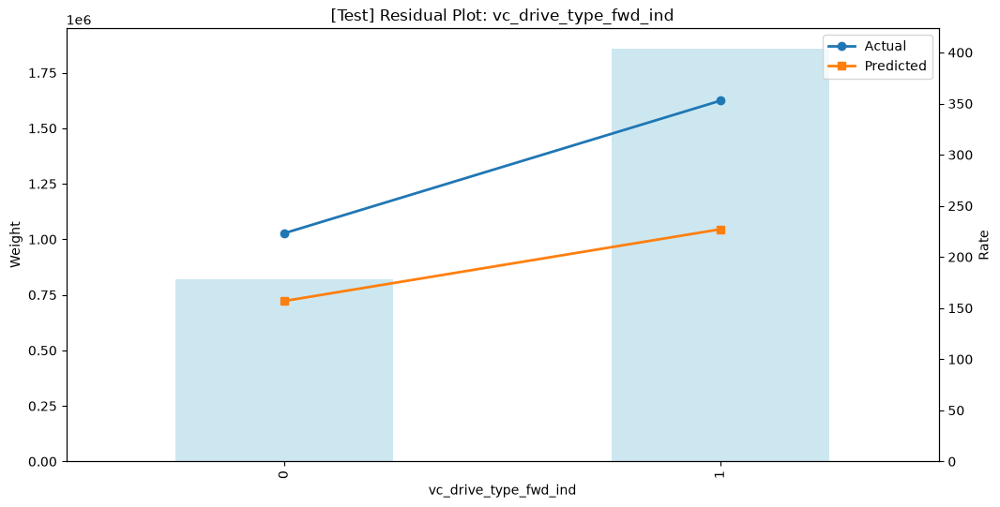

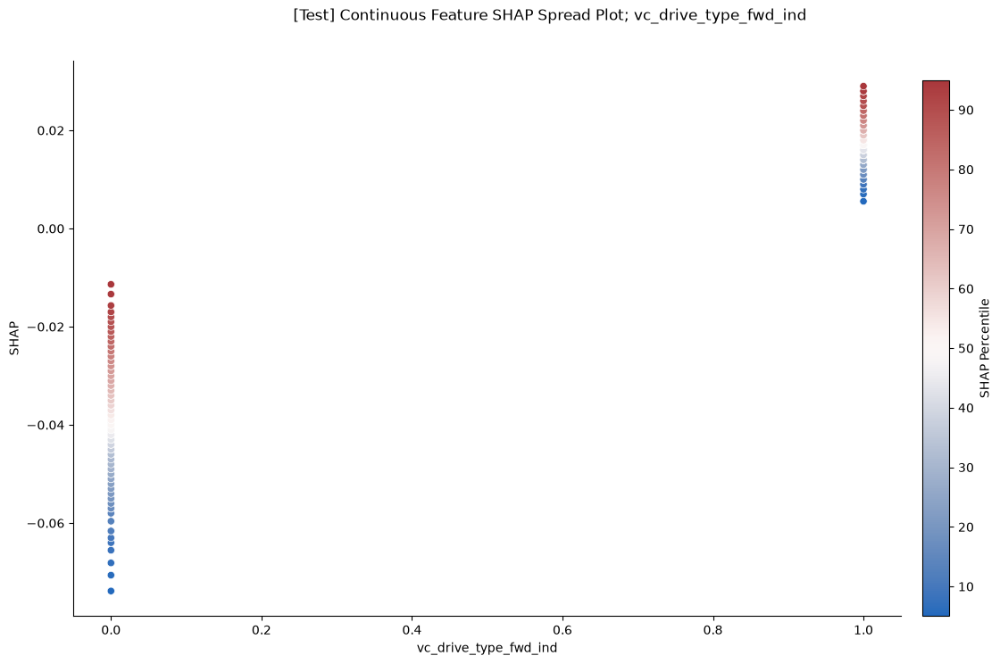


FEATURE: vc_rear_wiper_raw_0


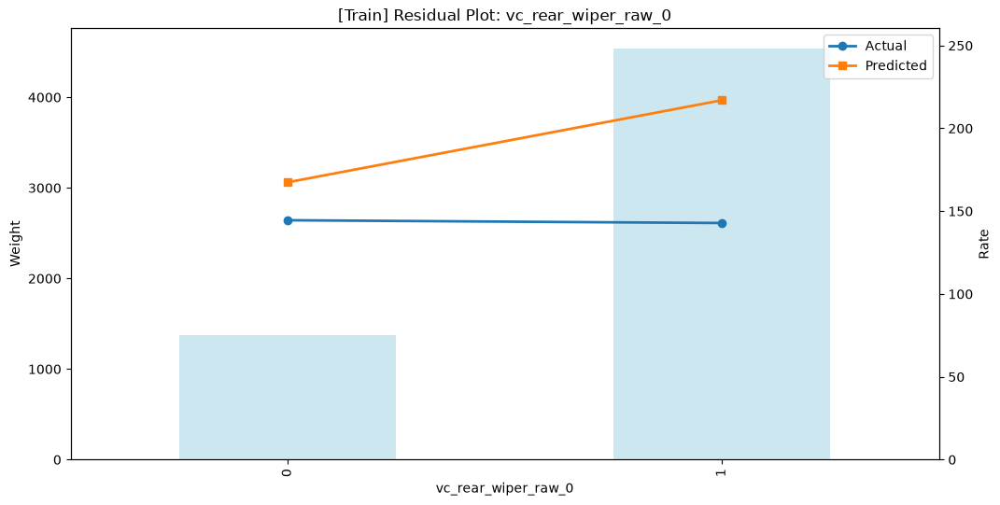

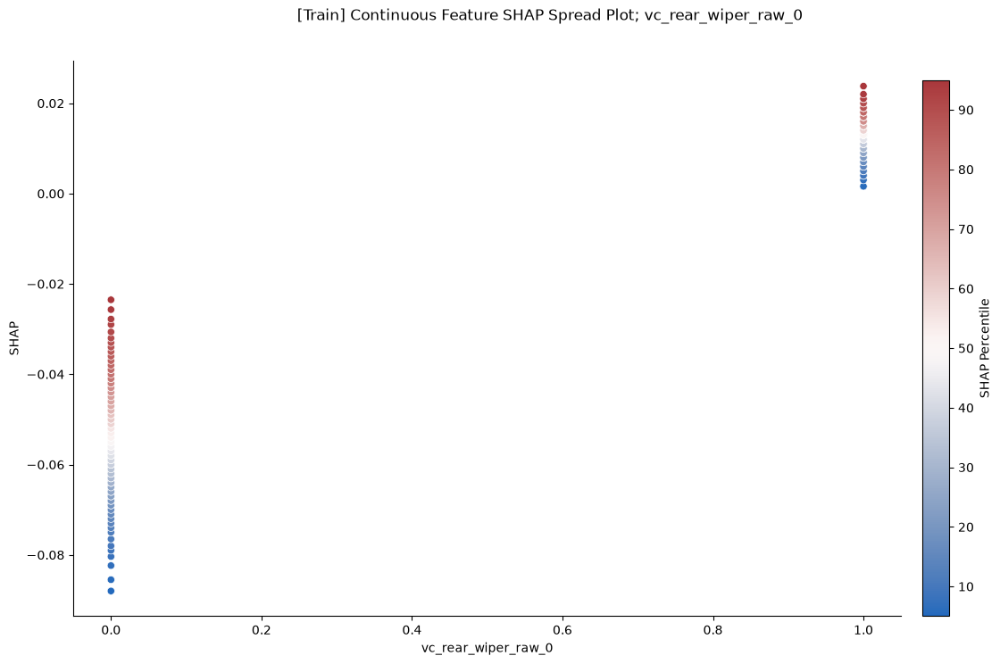

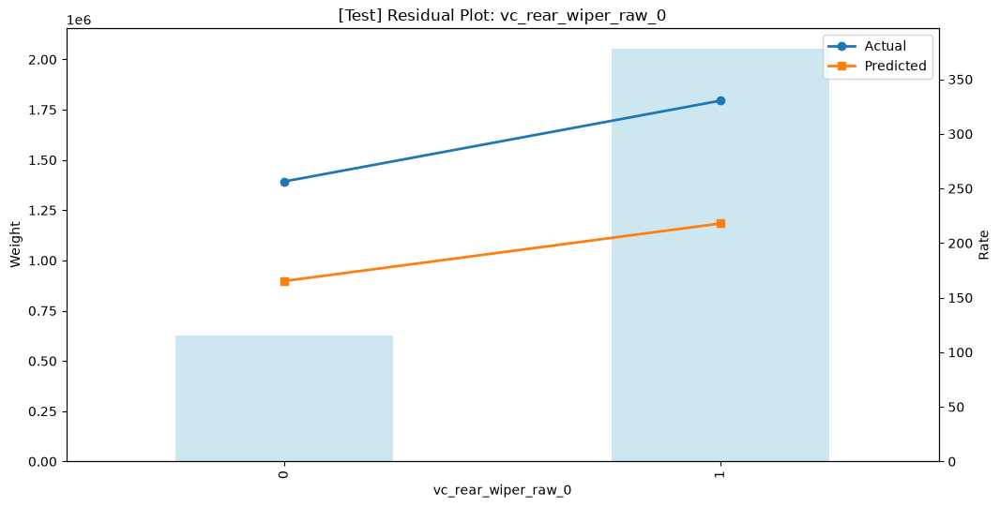

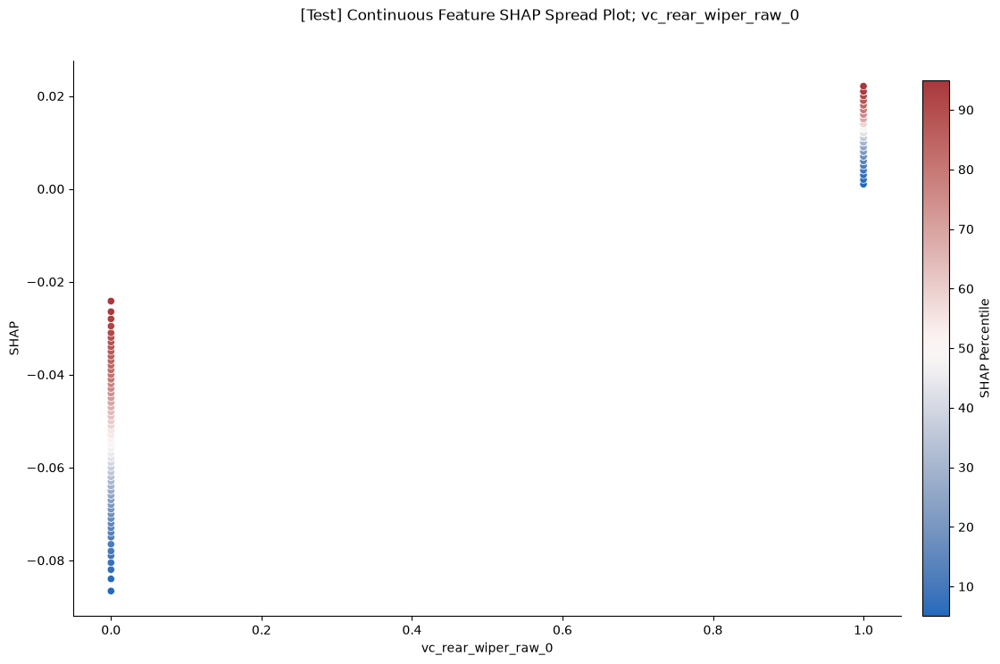


FEATURE: vc_touch_screen_raw_0


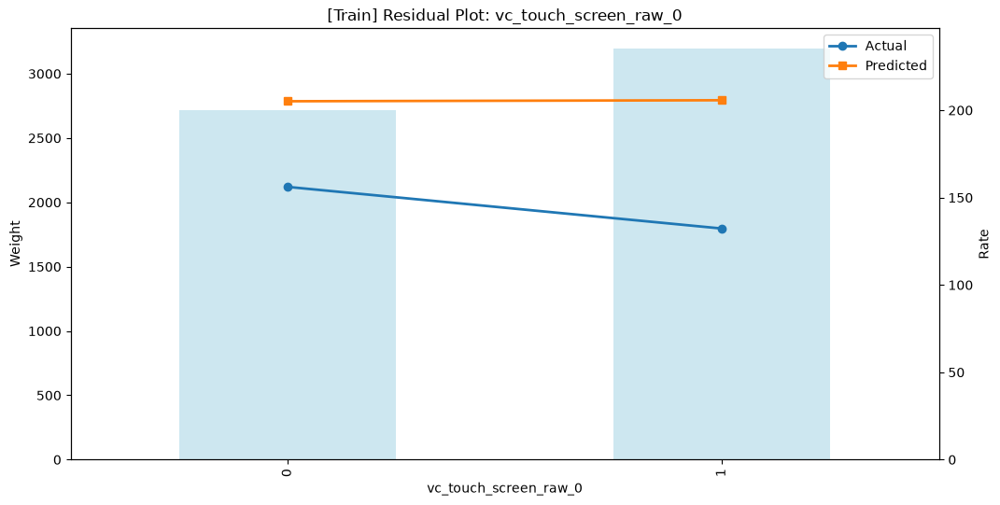

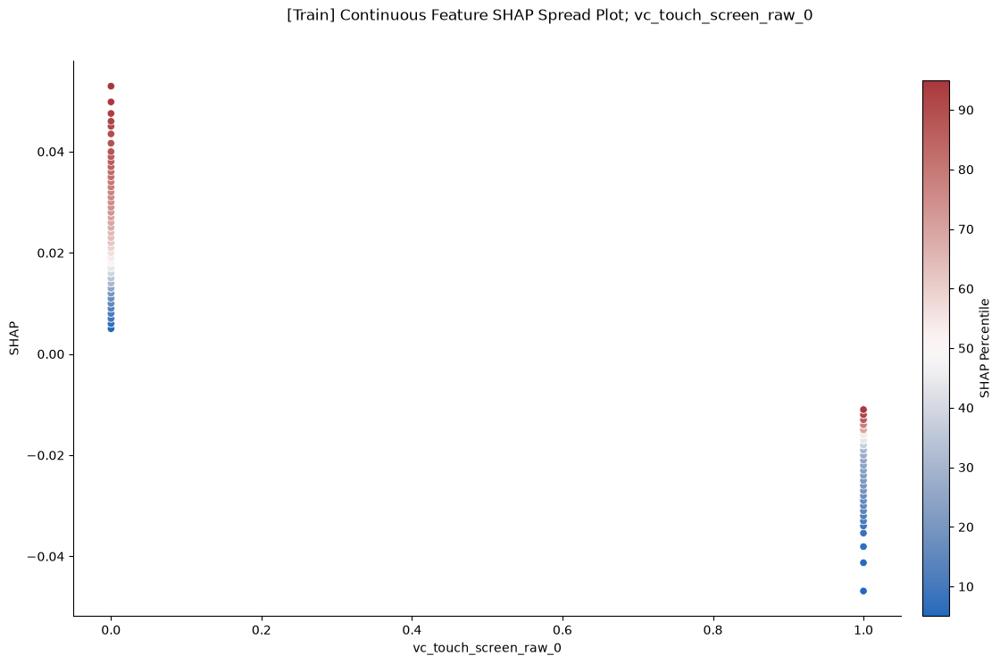

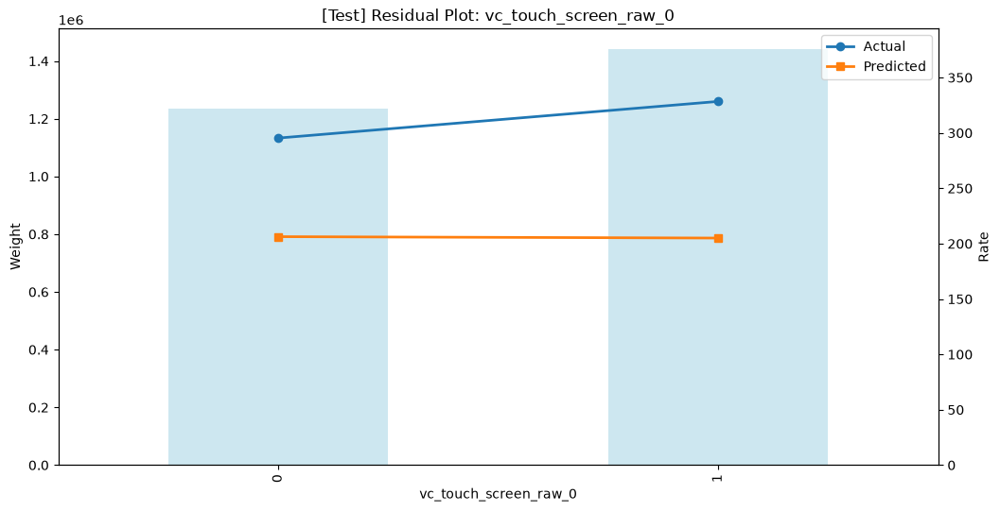

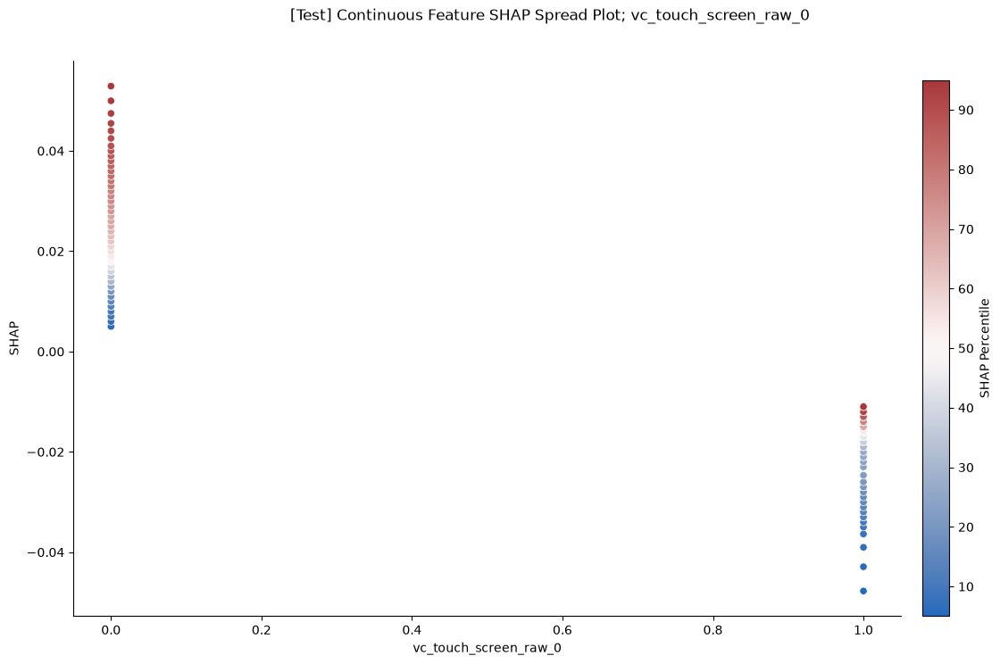


FEATURE: vc_backup_camera_raw_0


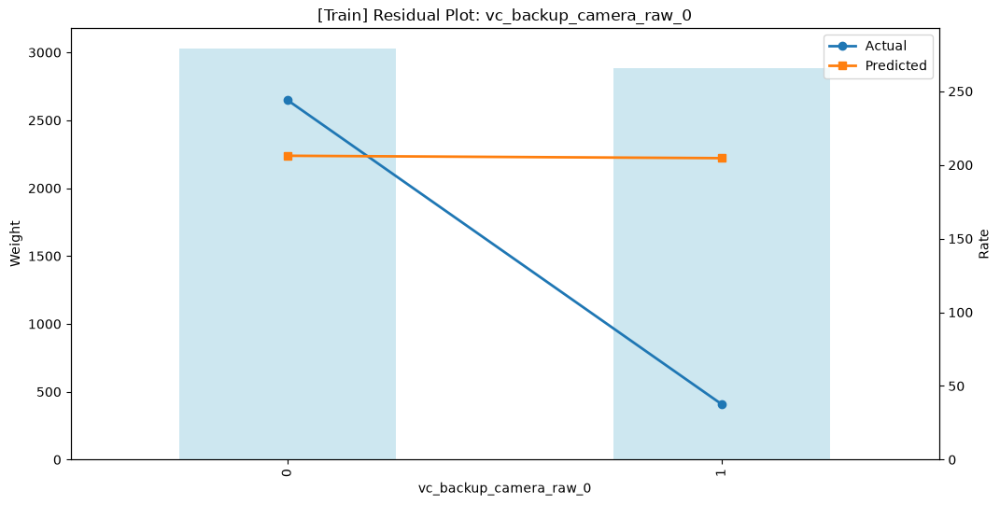

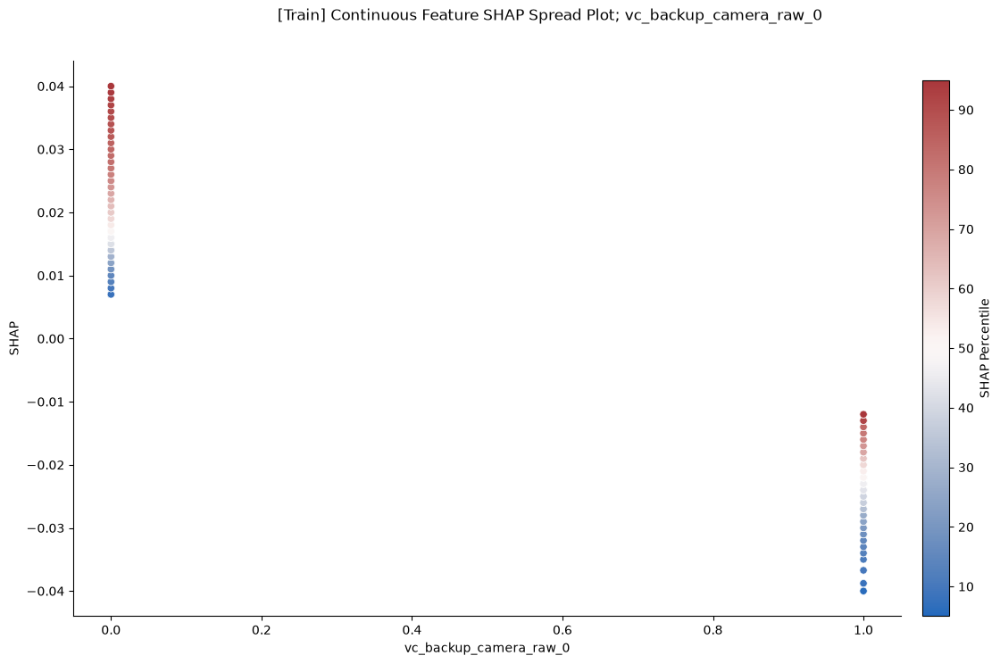

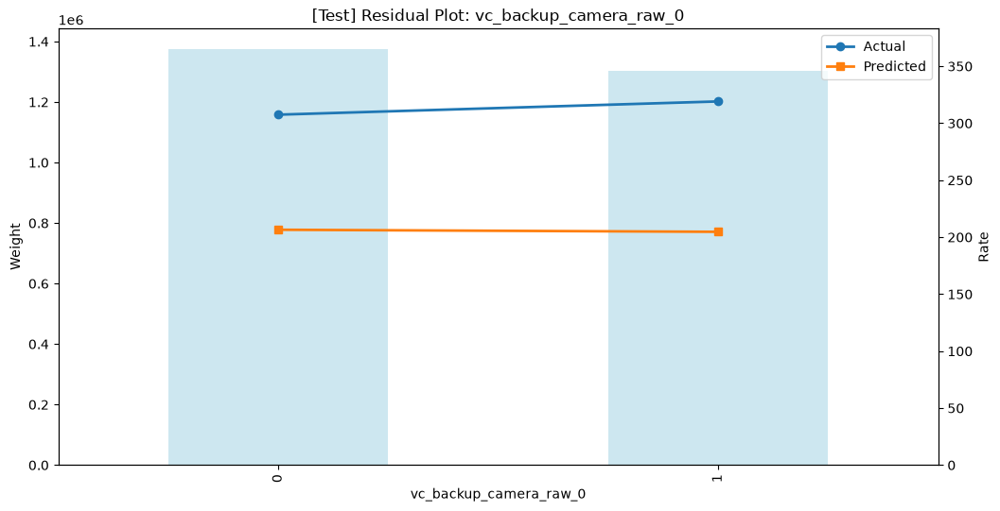

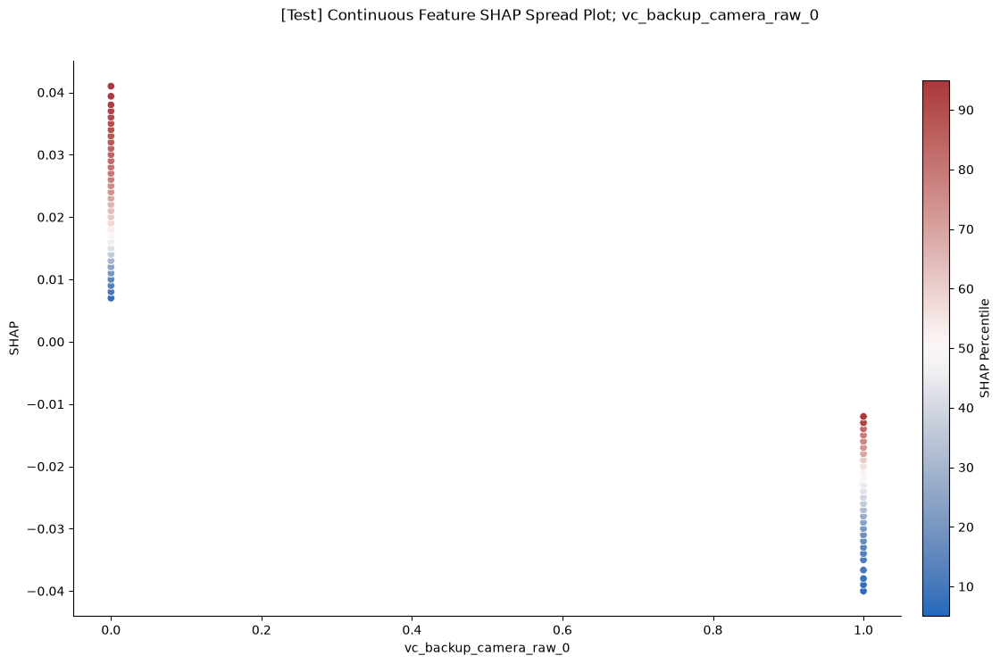


FEATURE: vc_luxury_flag_ind


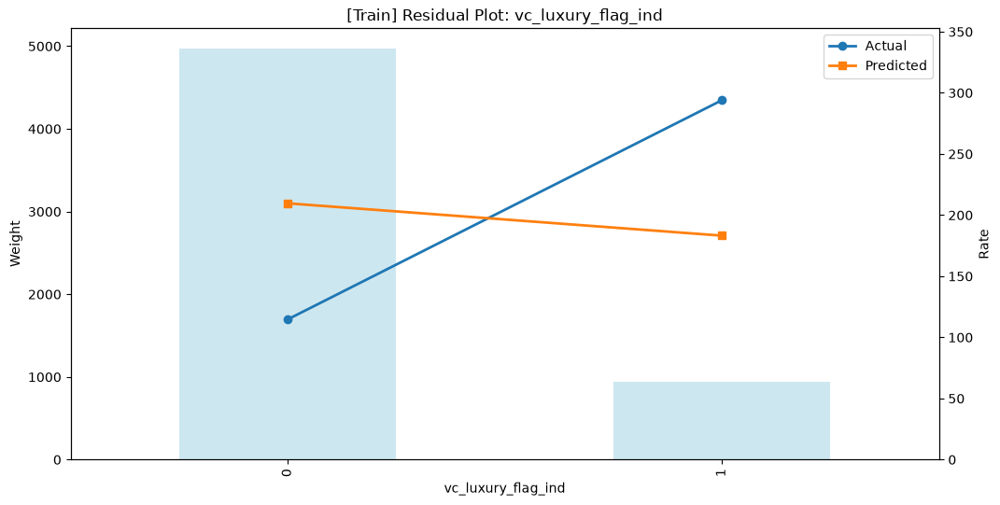

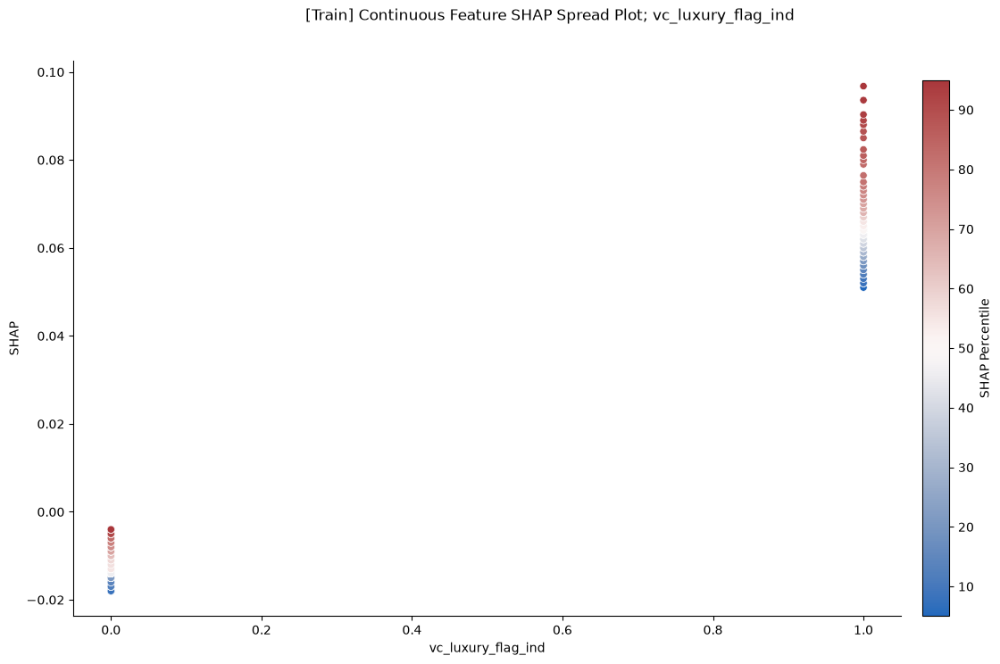

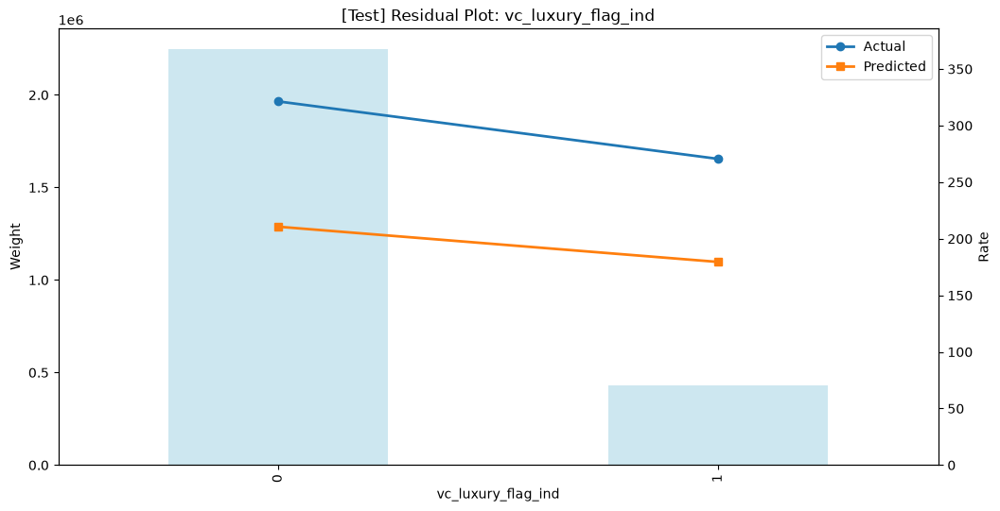

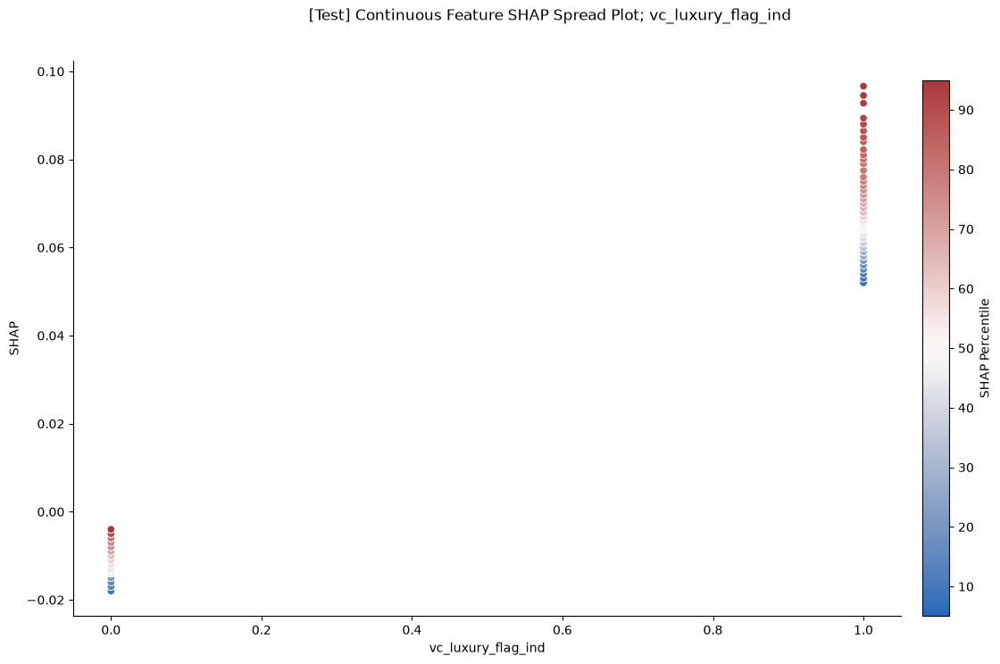


FEATURE: owt_leasepers_ind


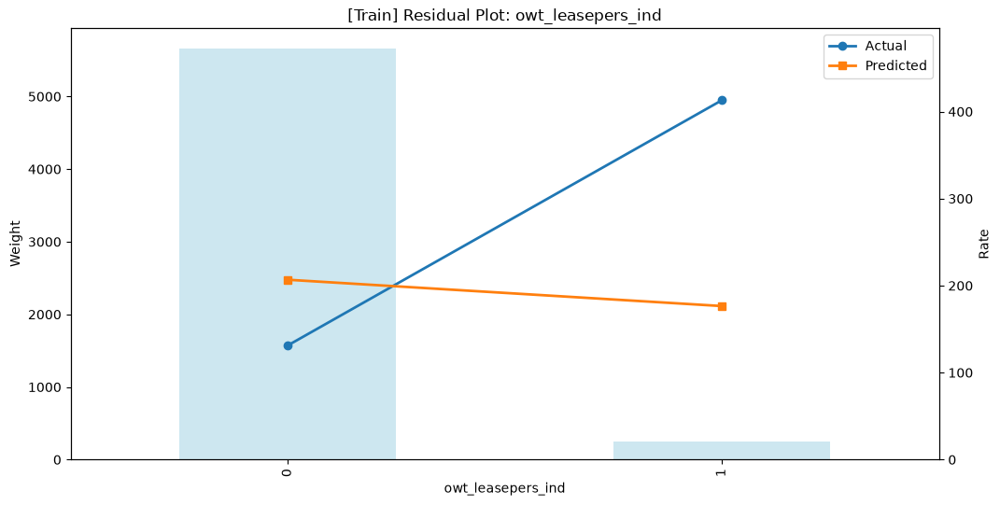

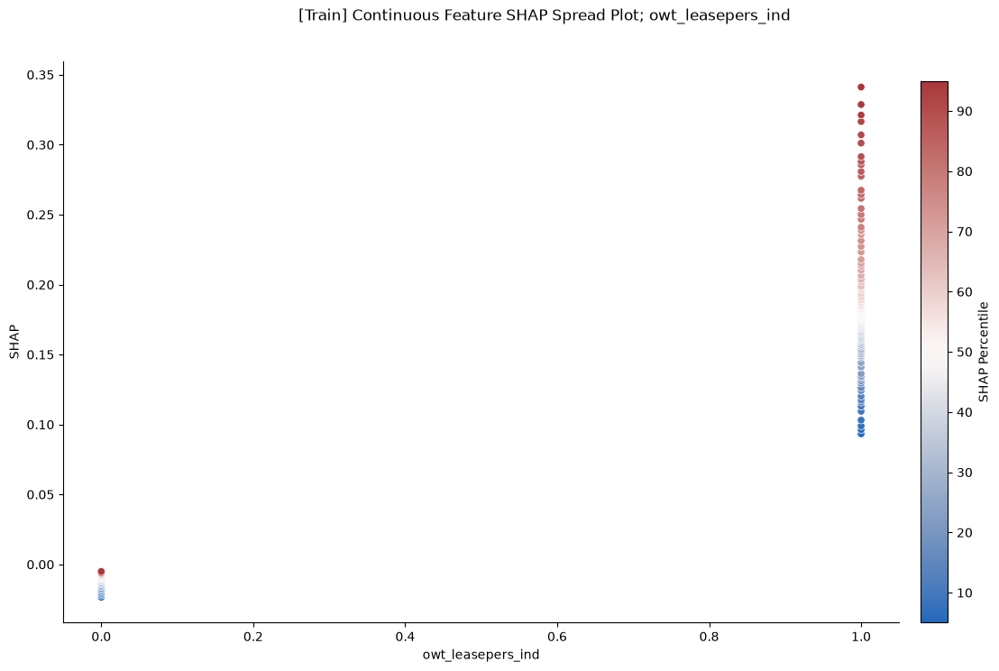

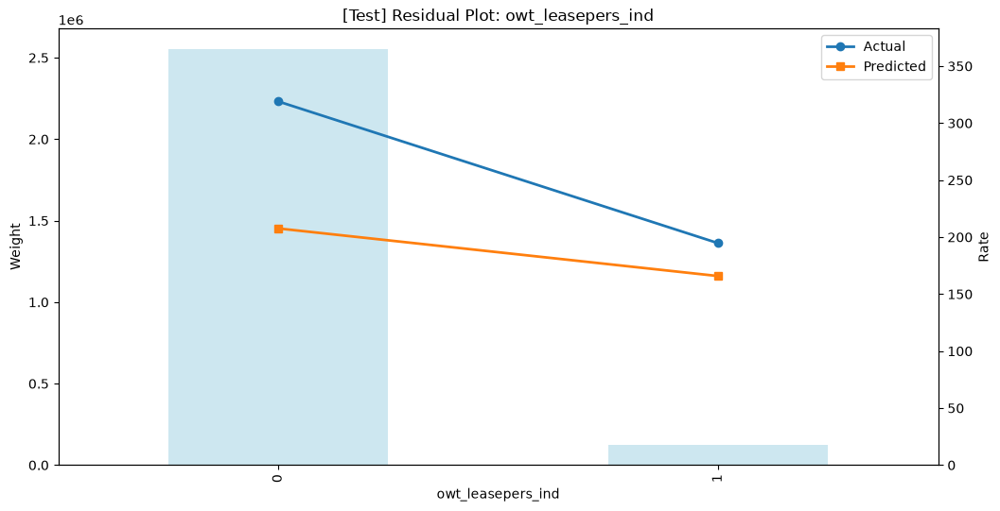

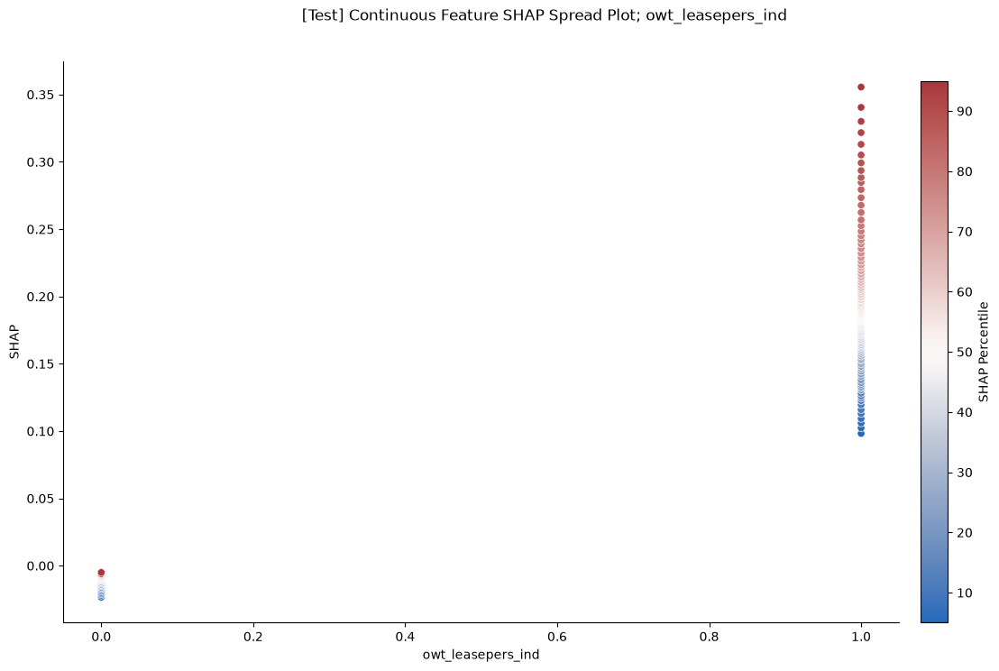


FEATURE: vc_passive_collision_avoidance_system_raw_0


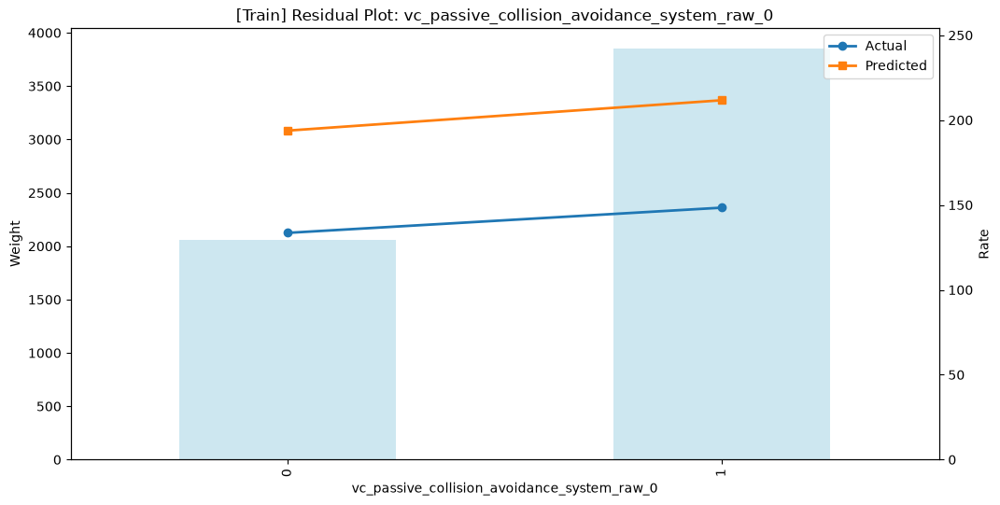

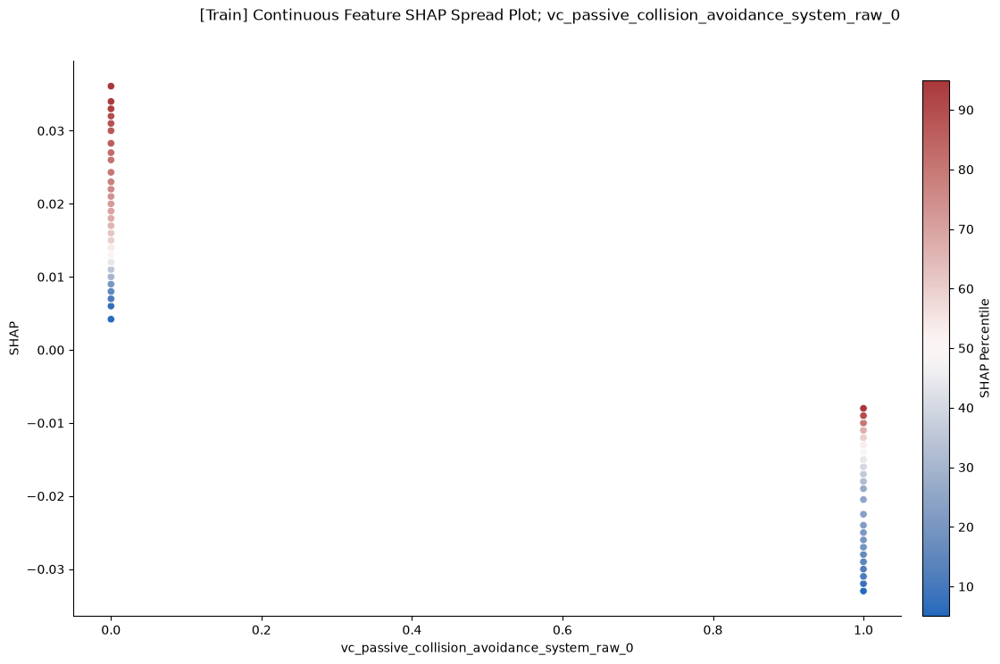

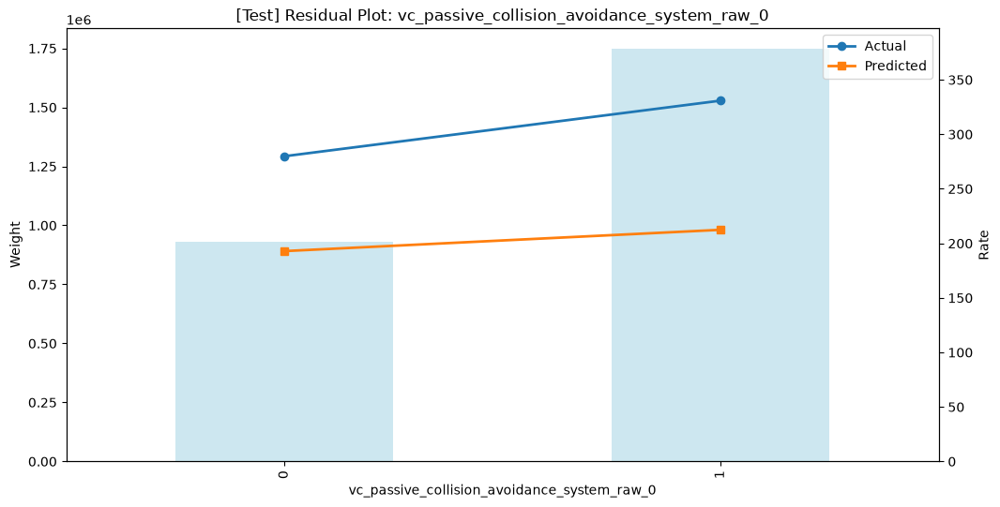

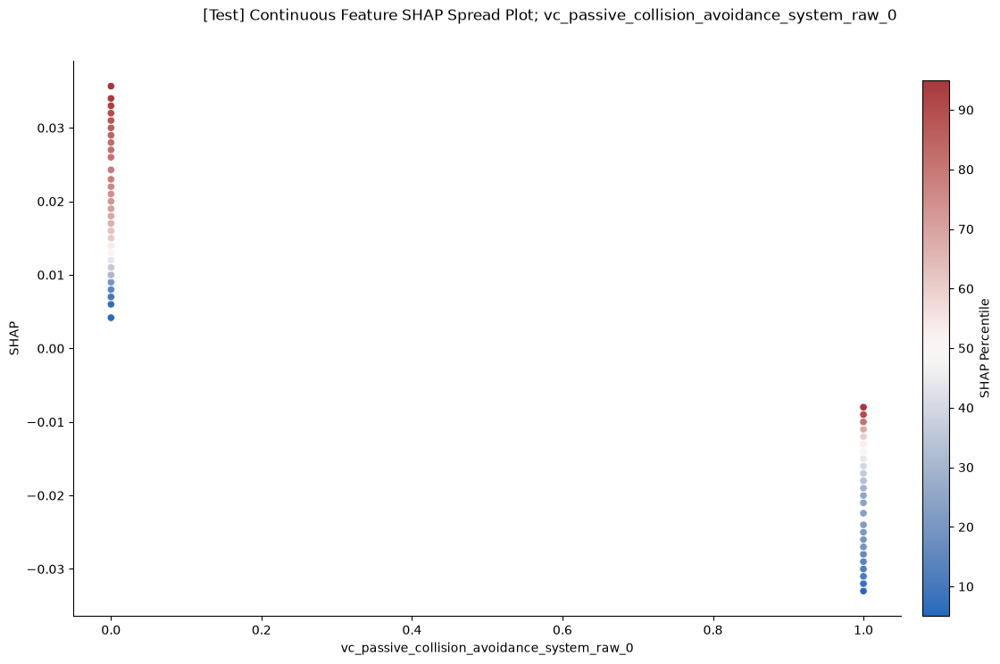


FEATURE: vc_touch_screen_raw_5


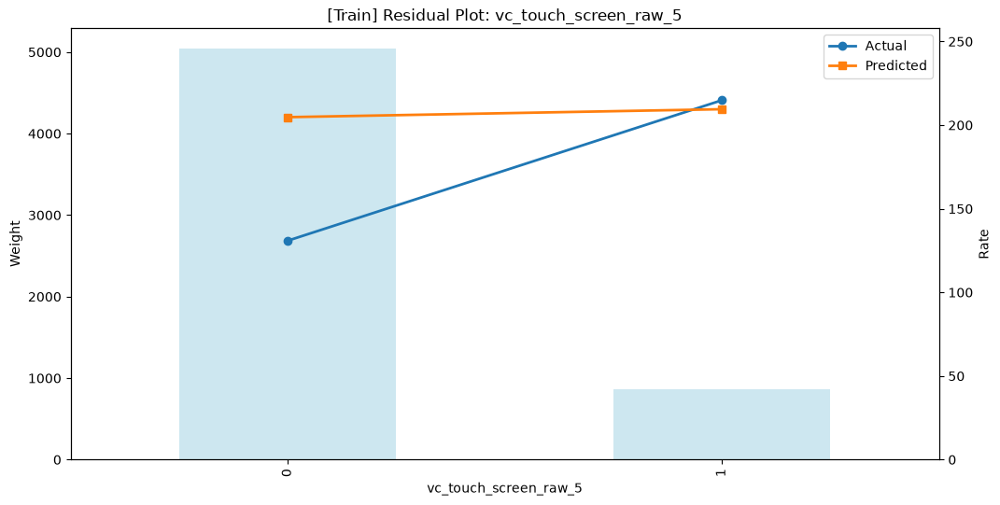

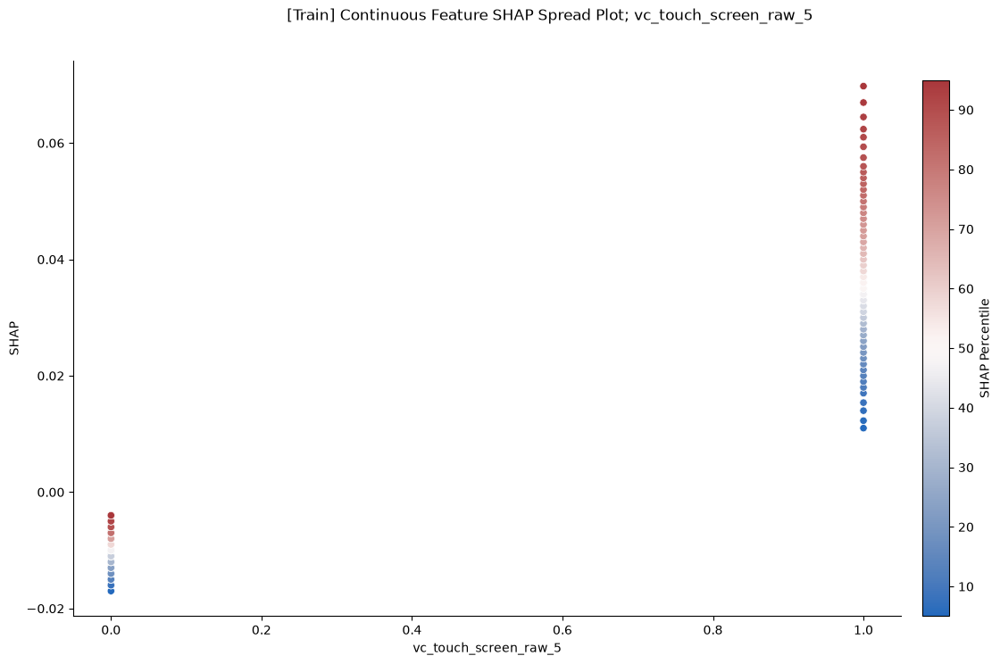

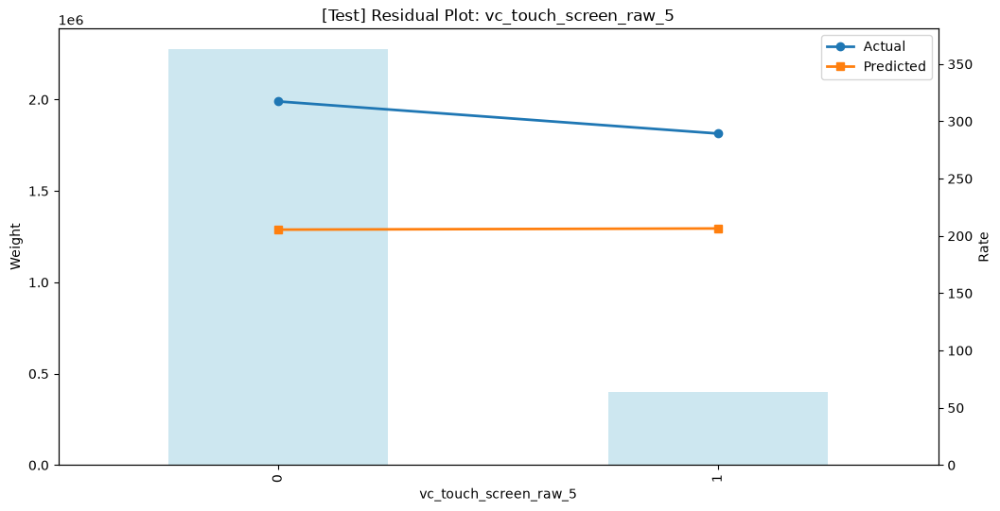

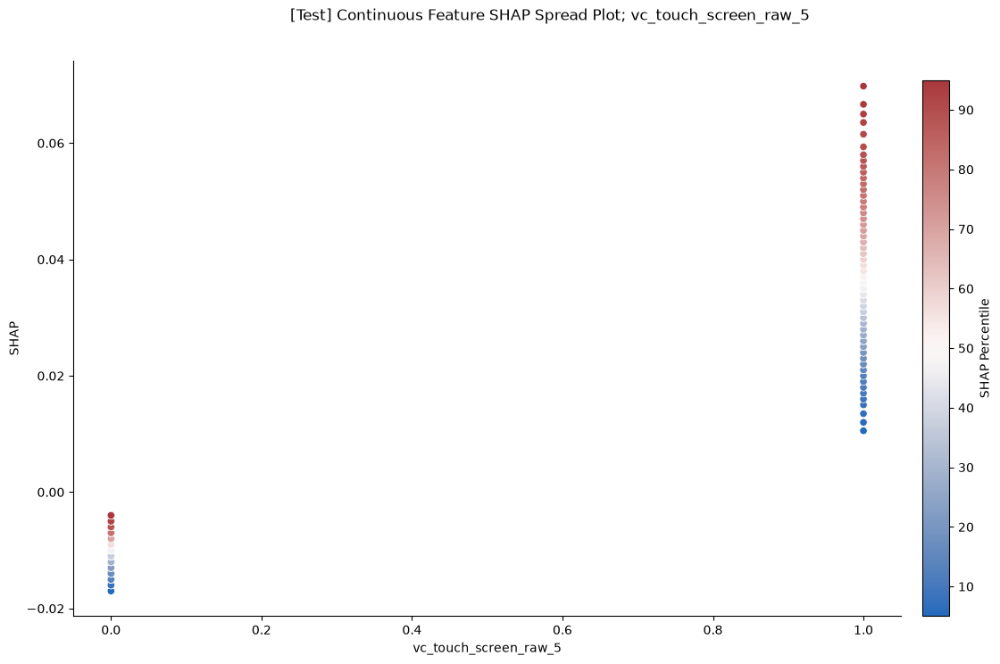


FEATURE: vc_auto_dimming_side_mirrors_raw


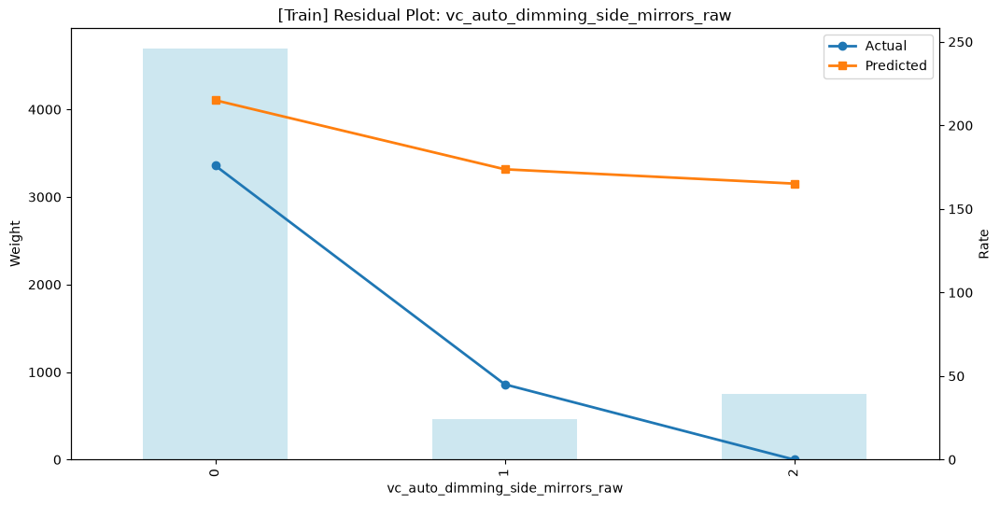

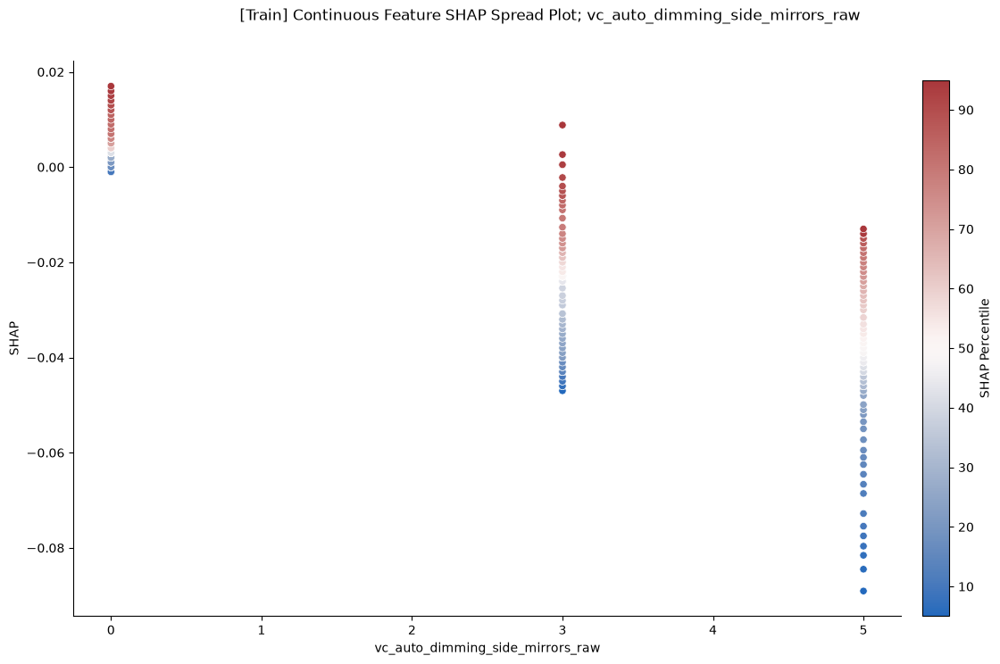

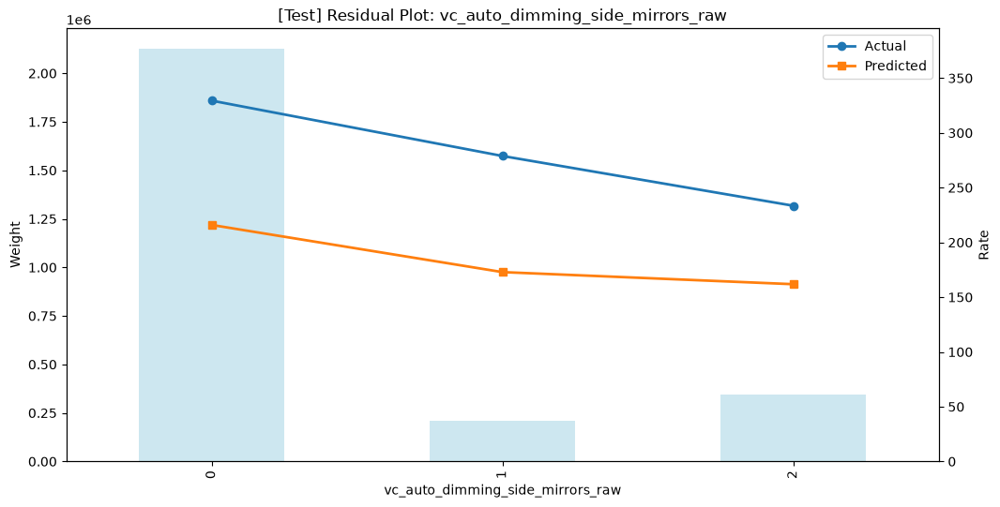

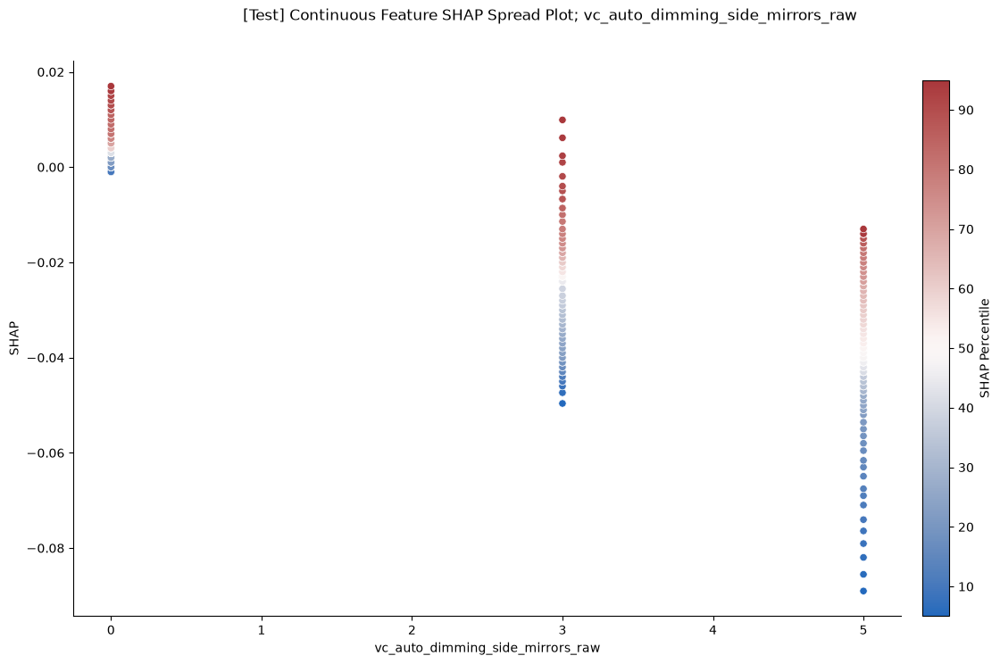


FEATURE: vc_premium_audio_raw


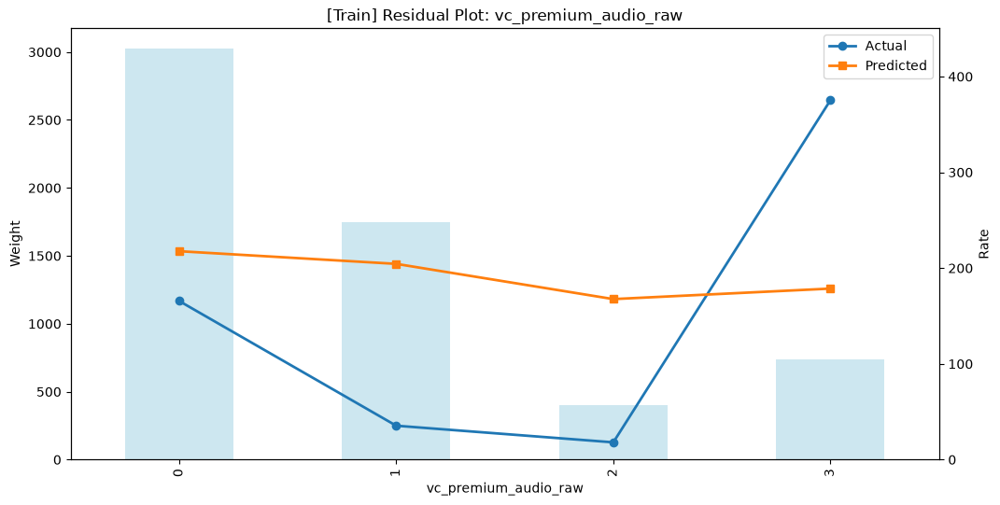

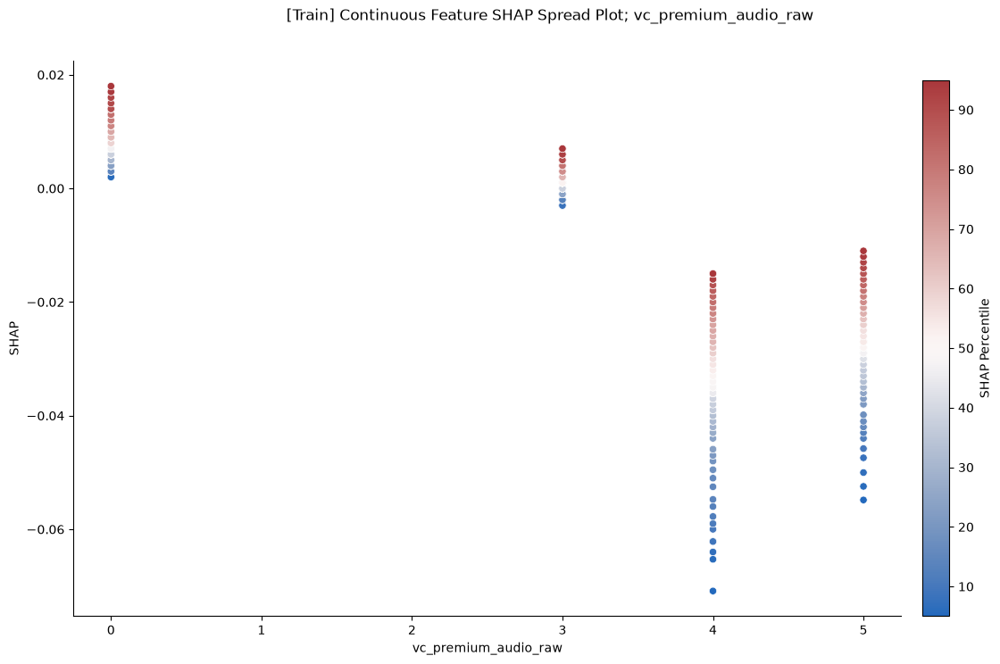

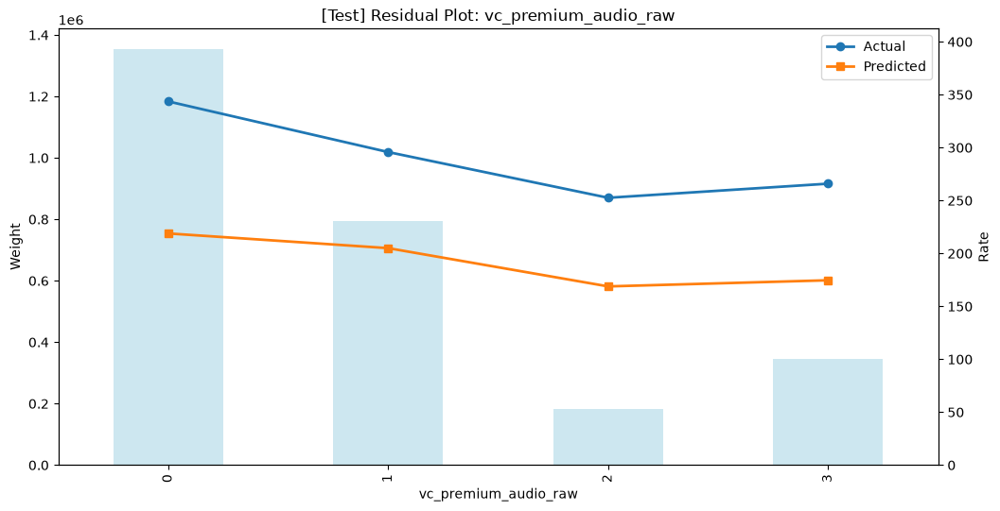

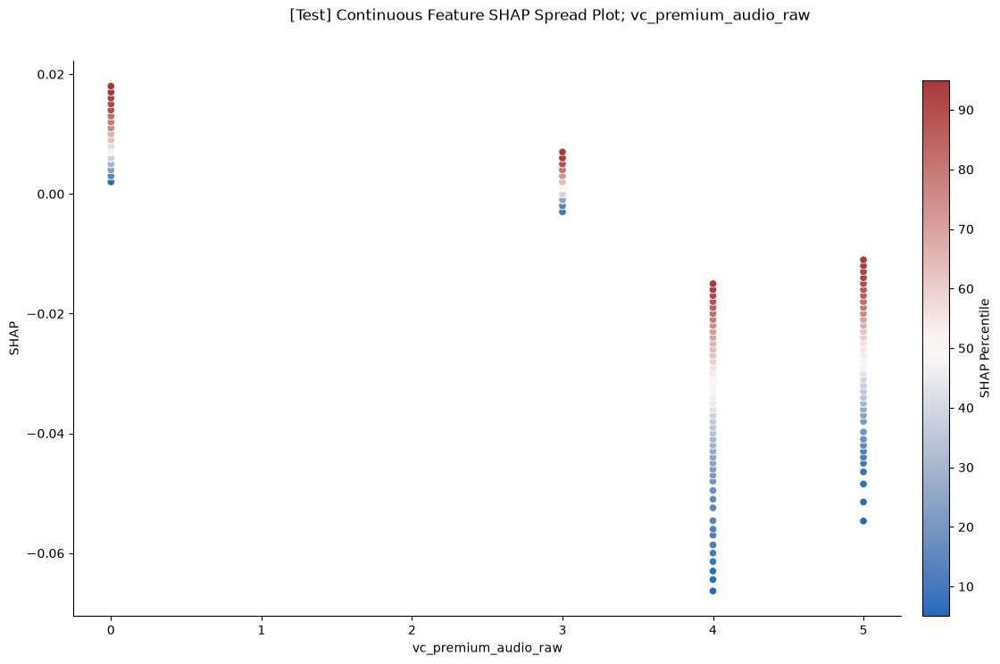


FEATURE: vc_surround_sound_raw_3


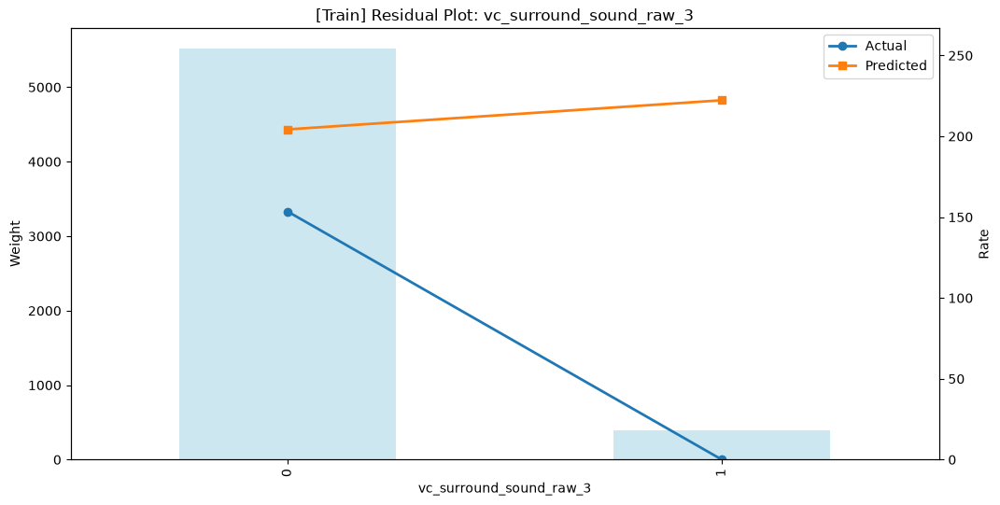

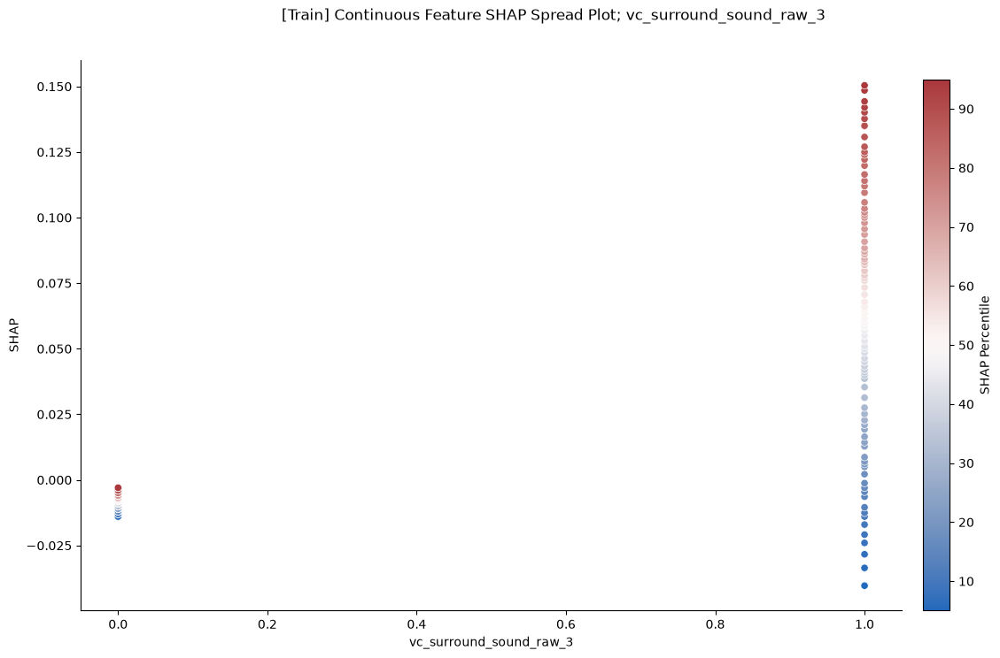

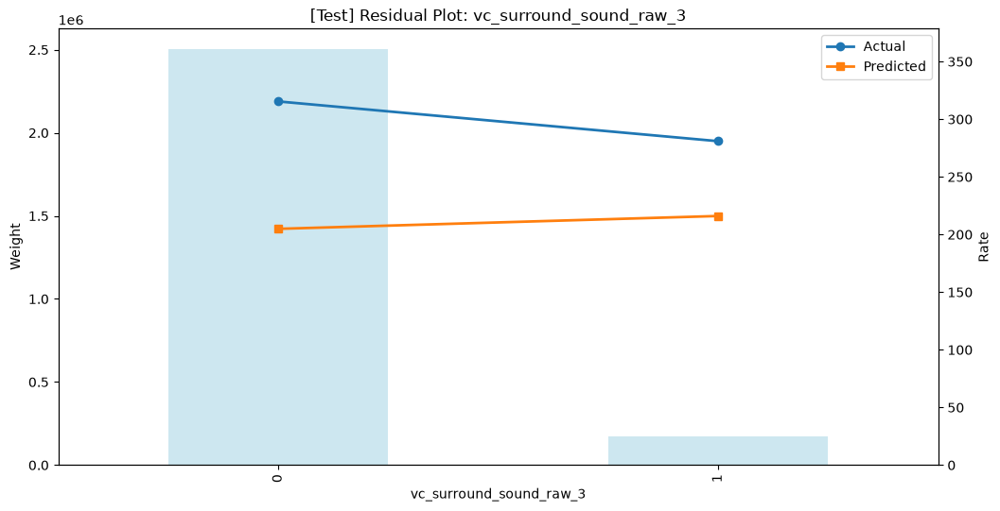

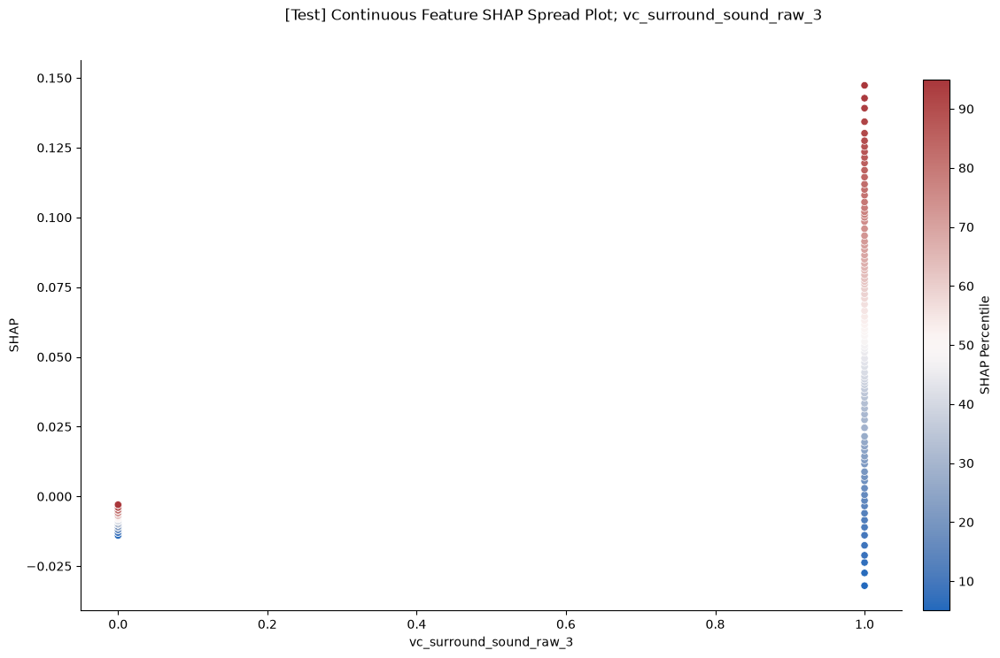


FEATURE: vc_satellite_radio_raw


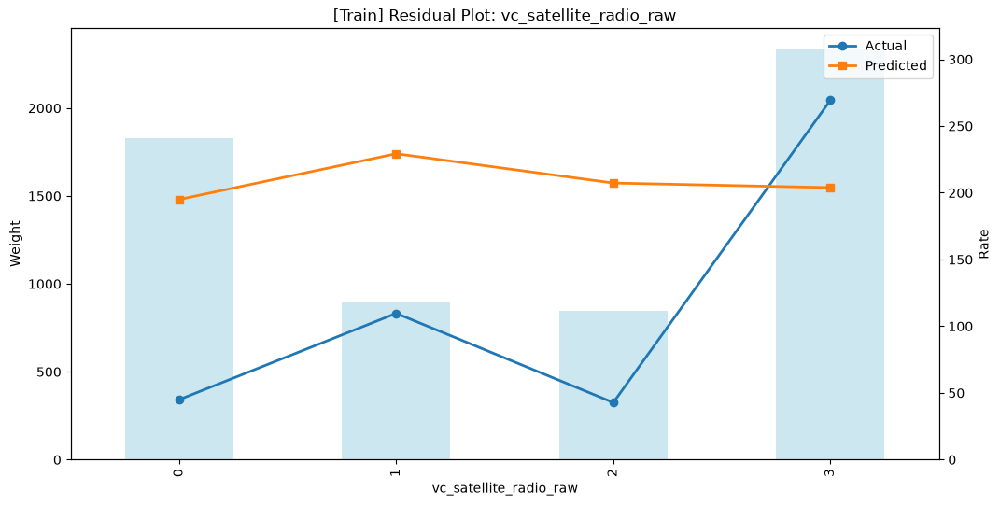

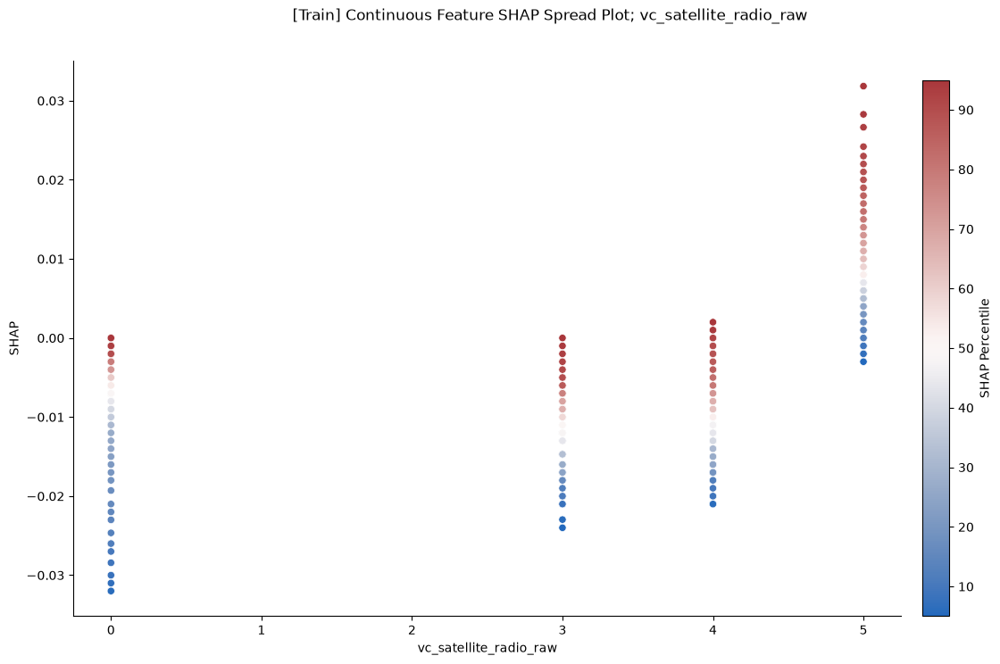

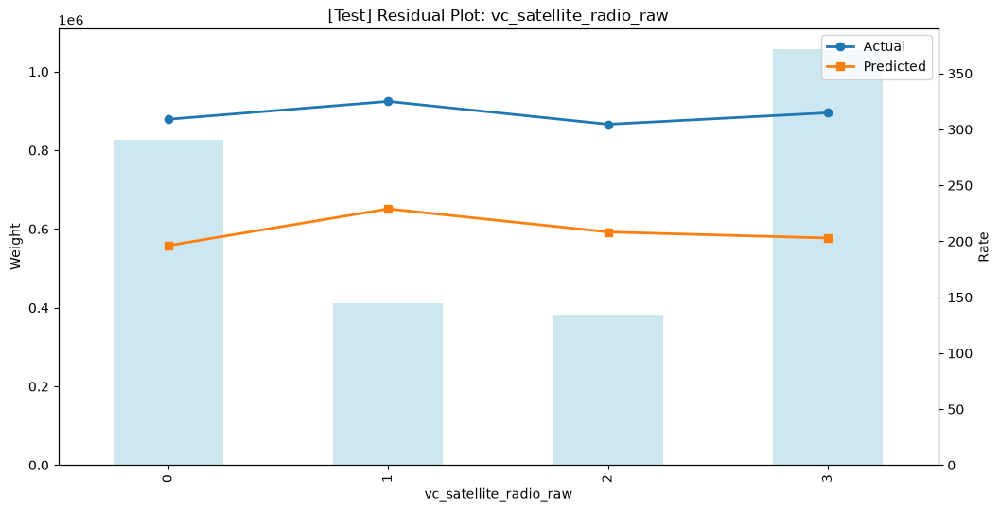

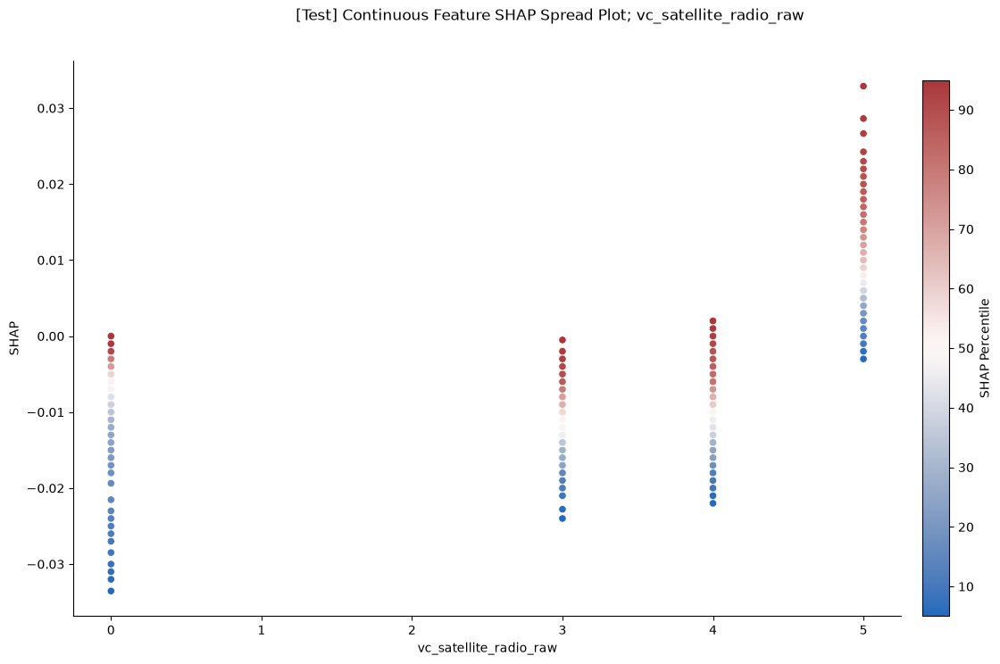


FEATURE: vc_auto_start_stop_raw_5


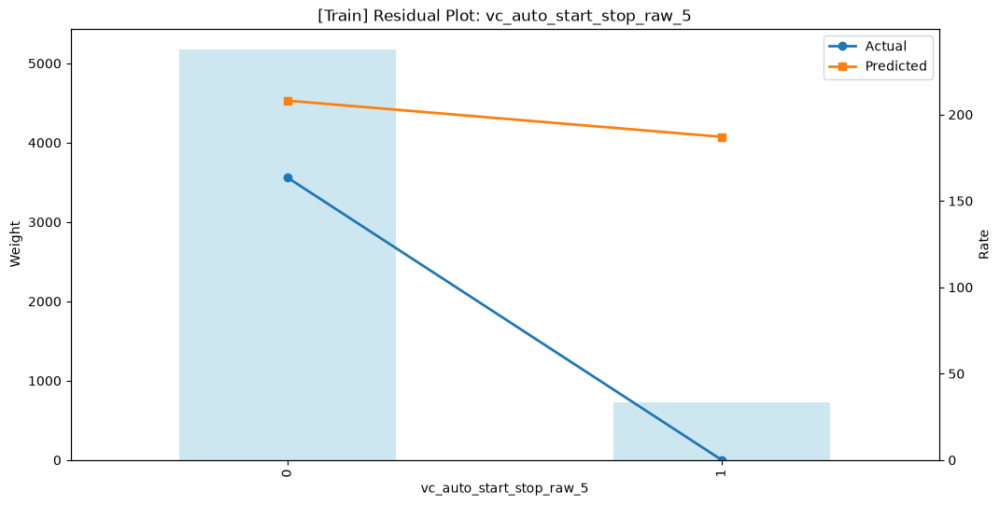

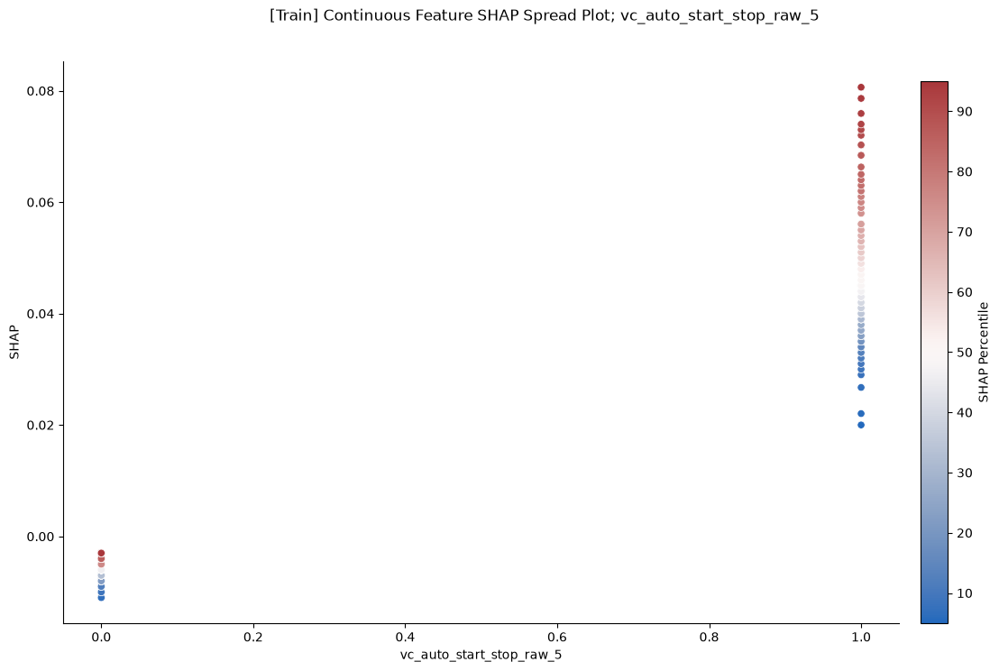

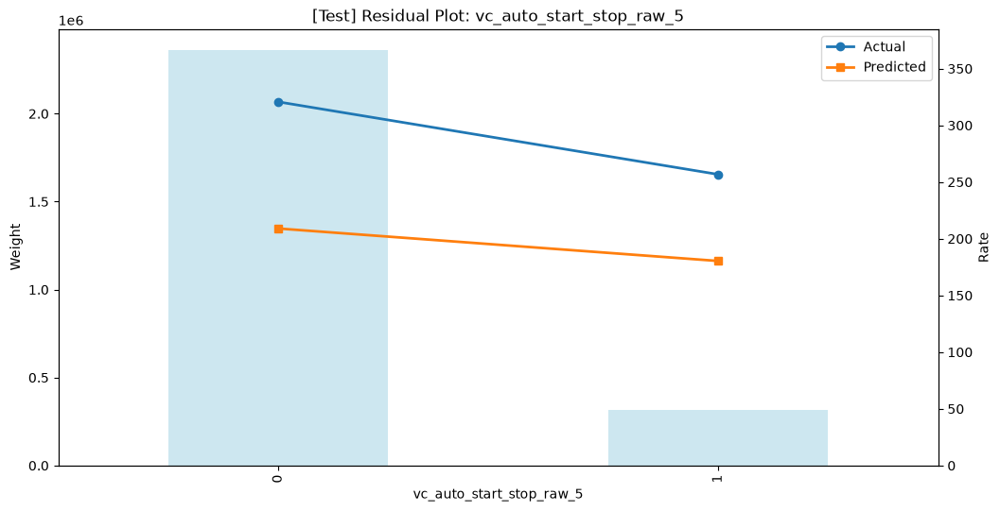

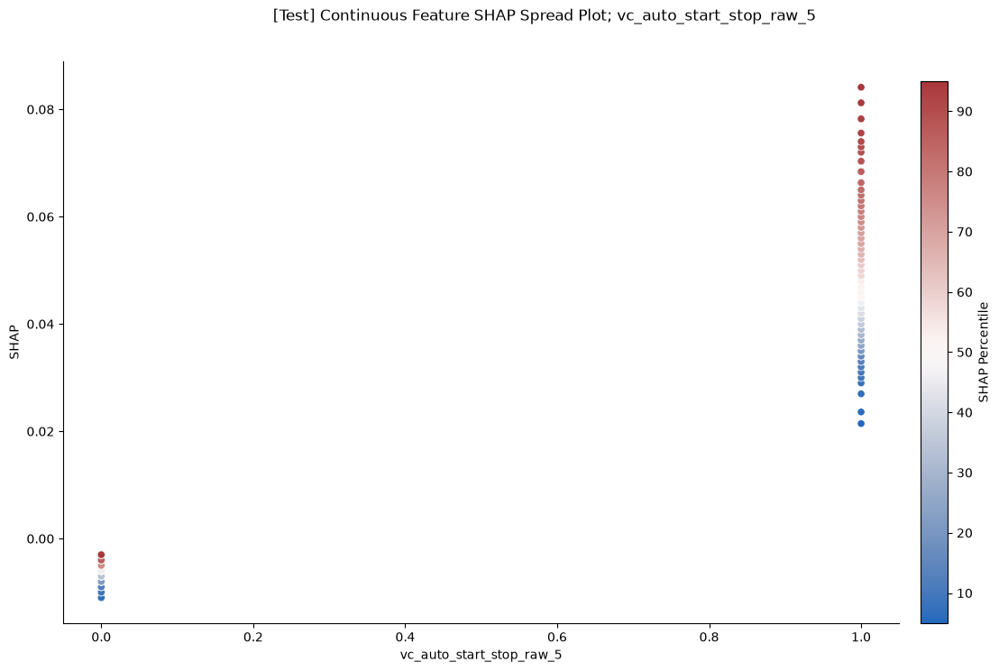


FEATURE: vc_lane_departure_warning_raw


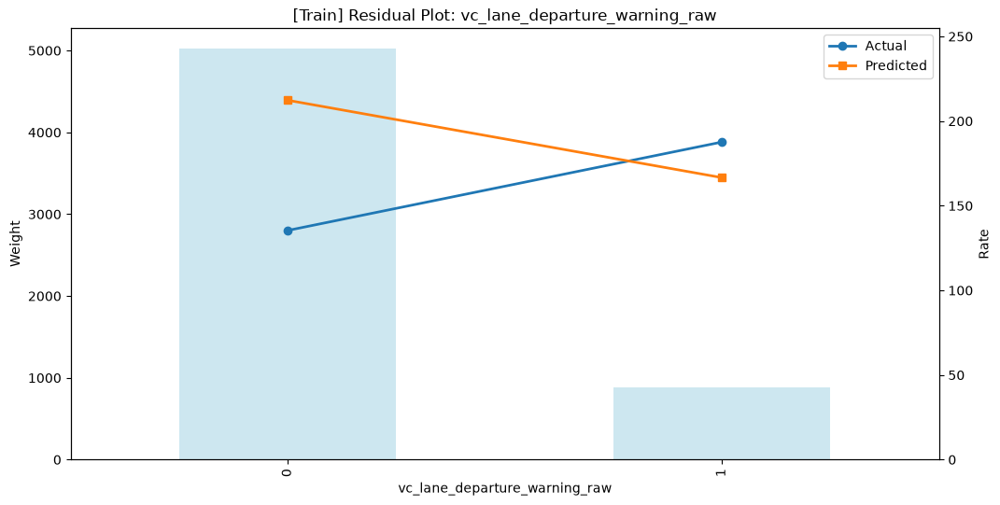

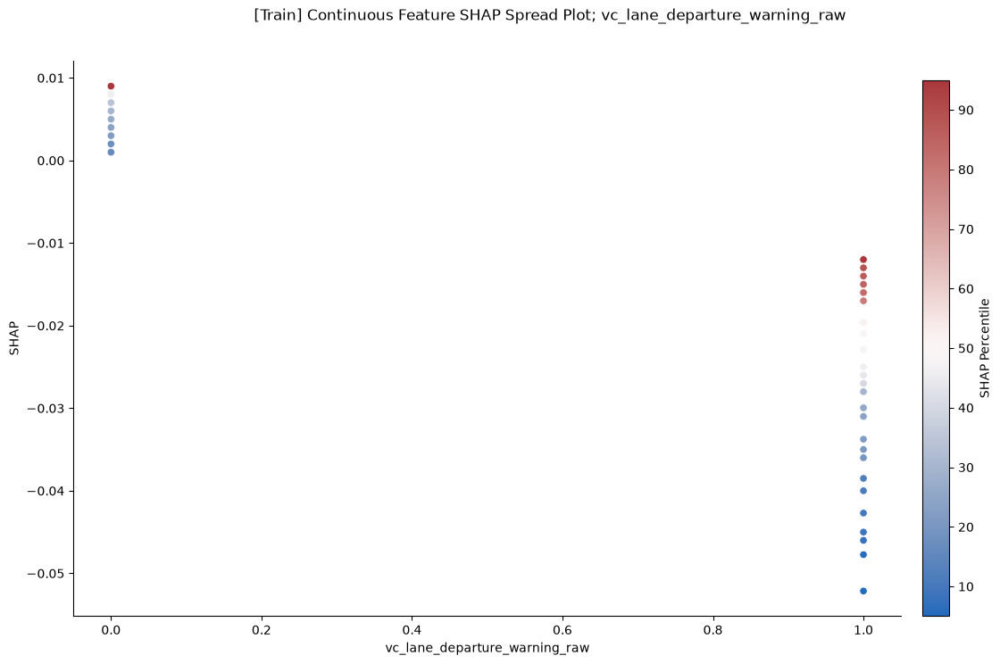

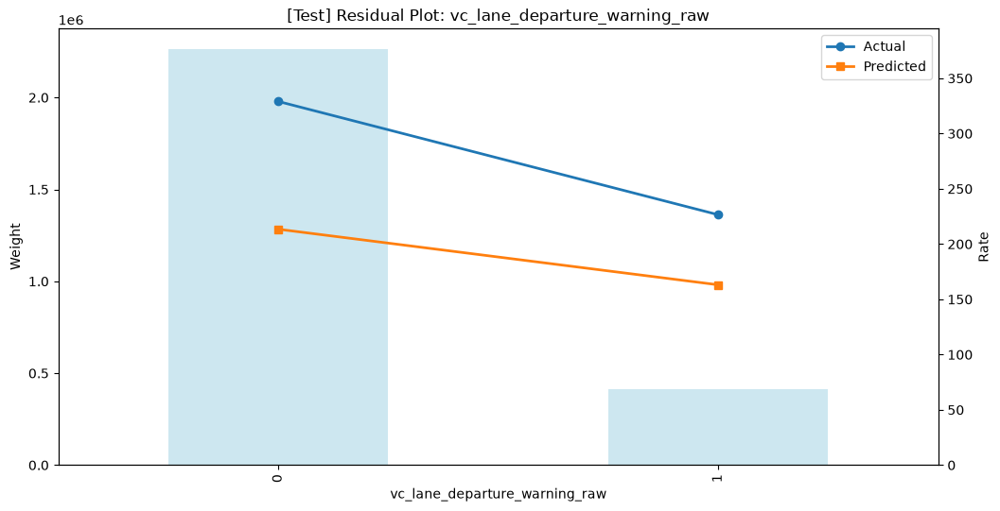

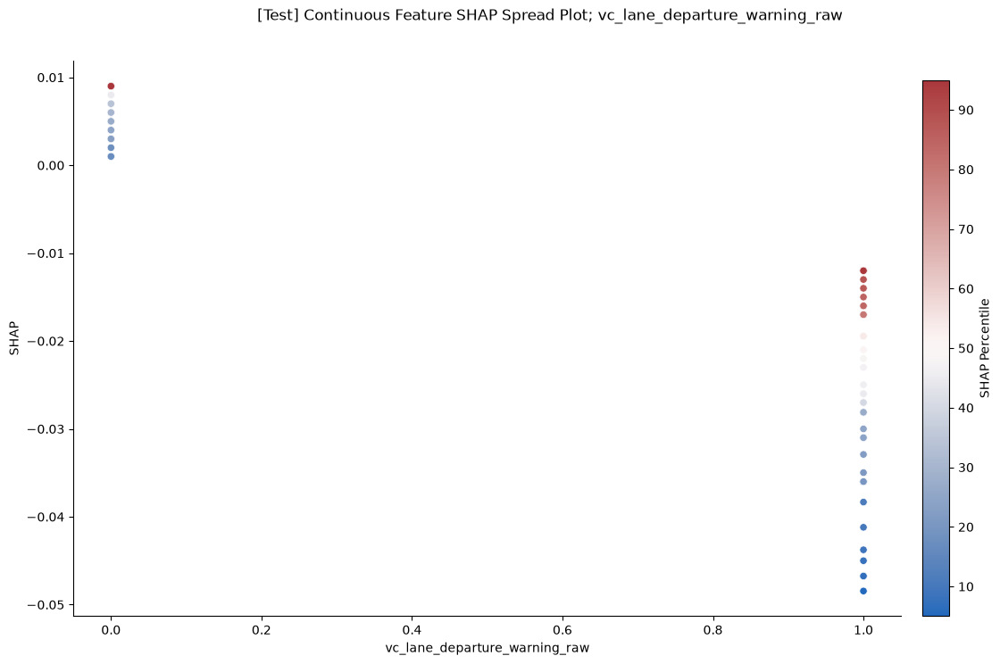


FEATURE: vc_adaptive_cruise_control_raw_0


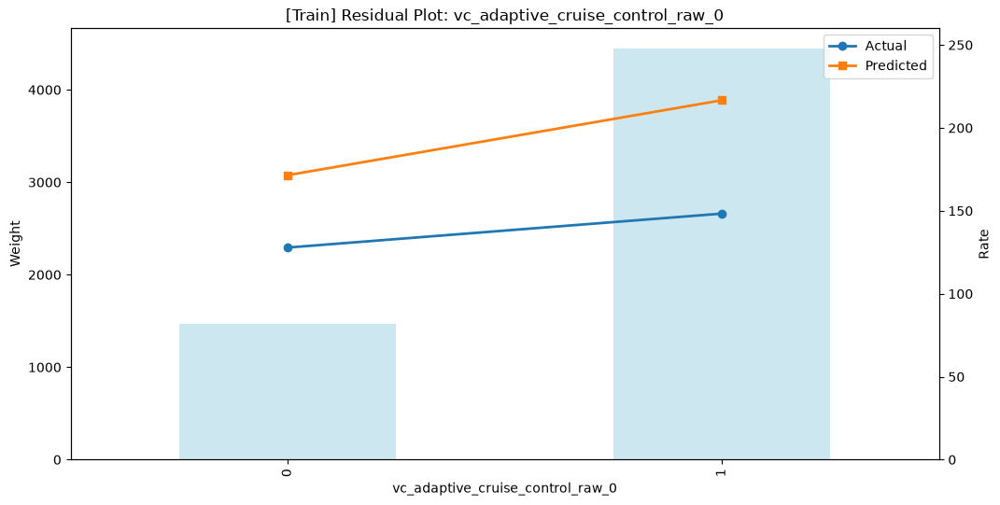

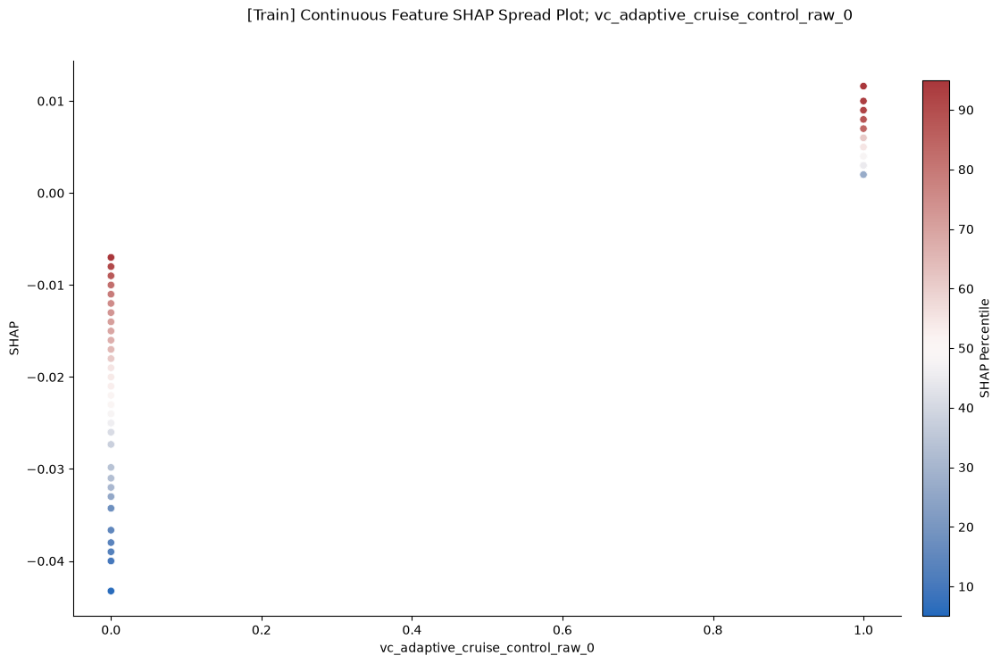

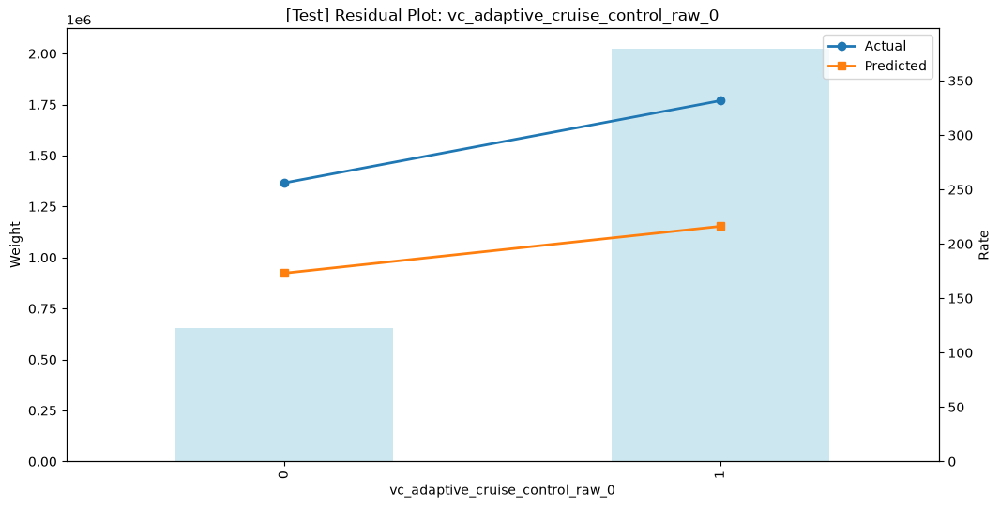

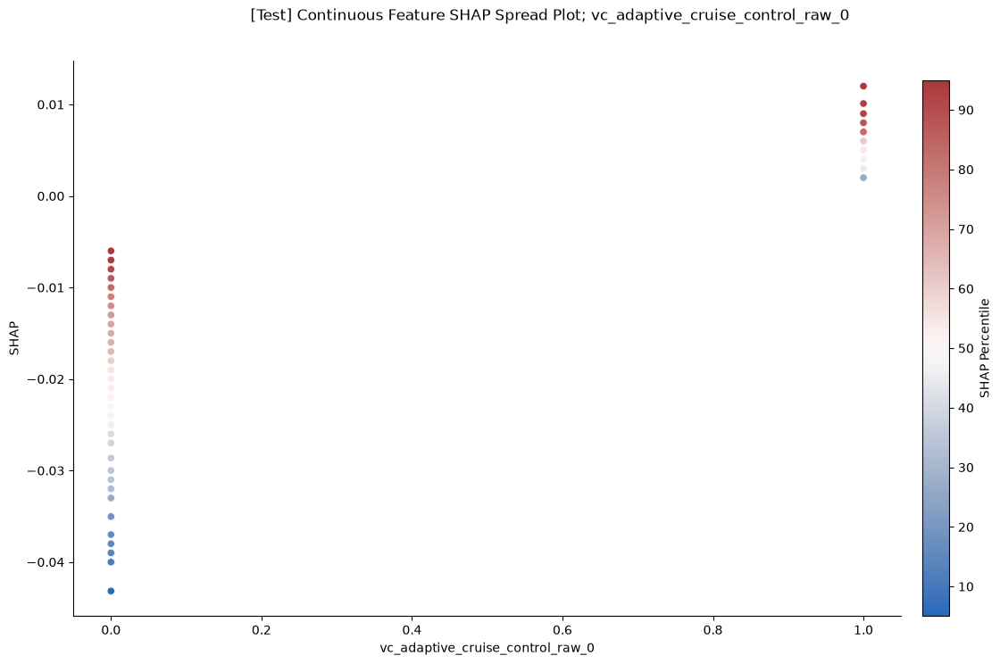


FEATURE: vc_surround_sound_raw_1


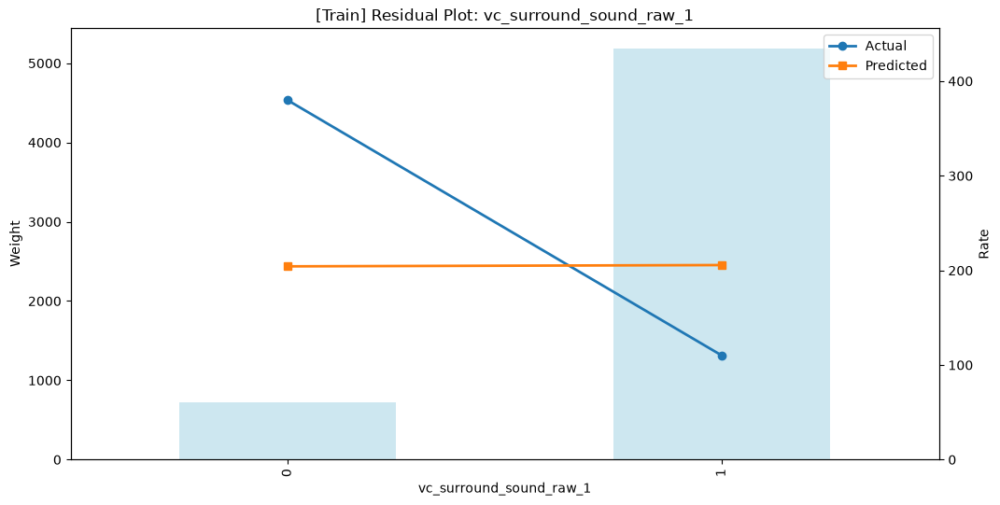

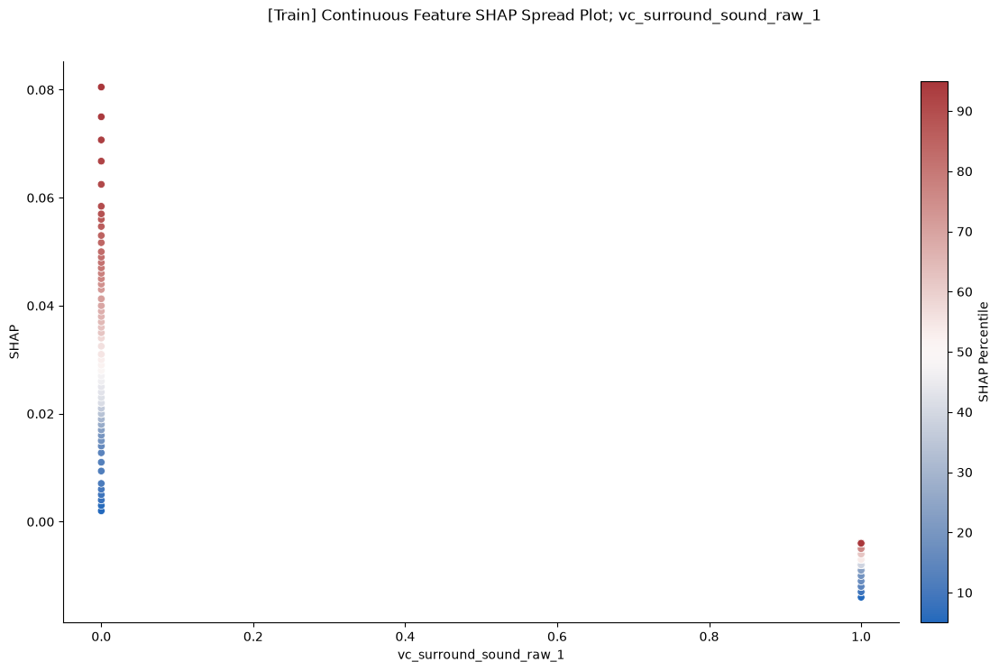

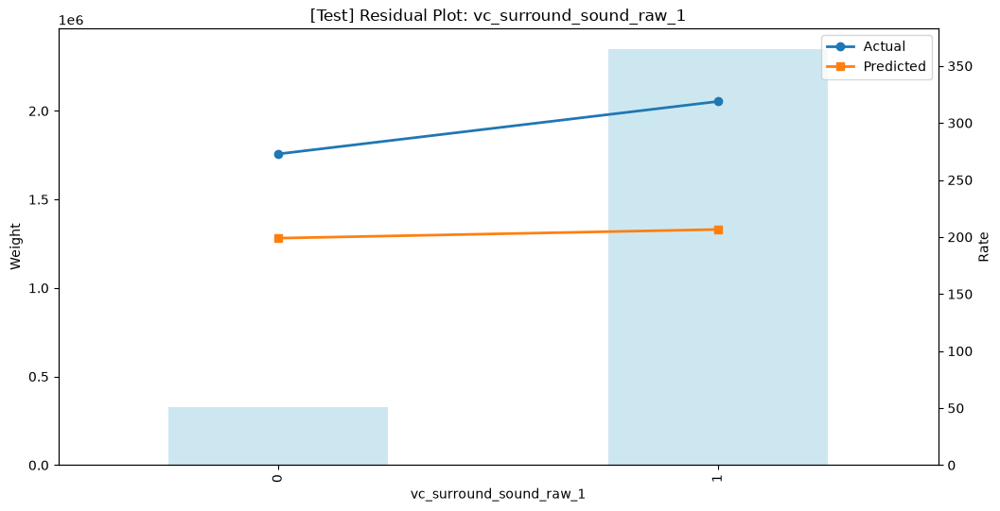

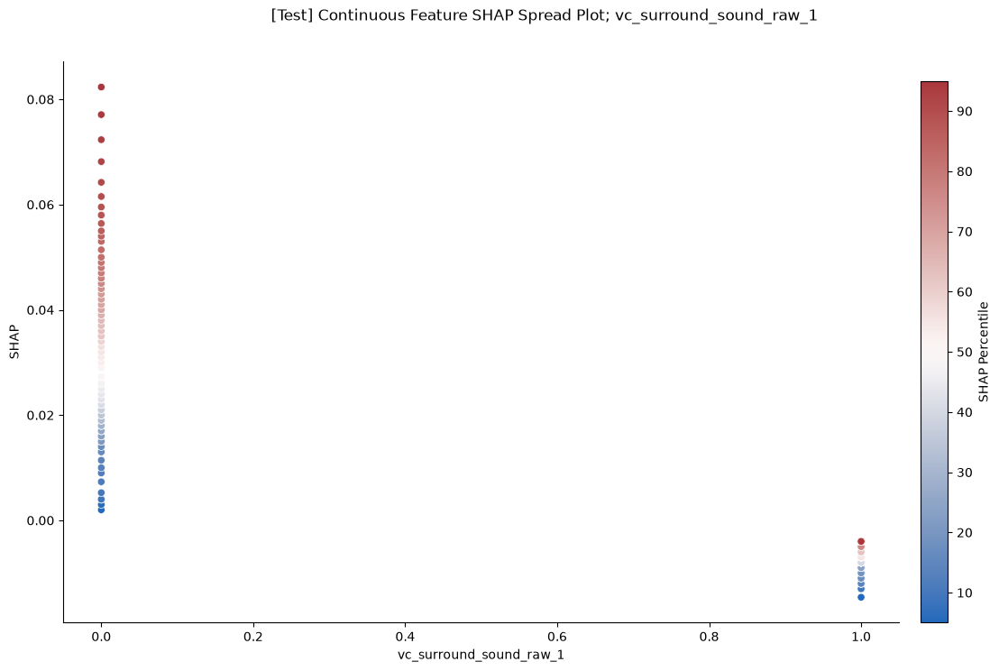


FEATURE: vc_touch_screen_raw_4


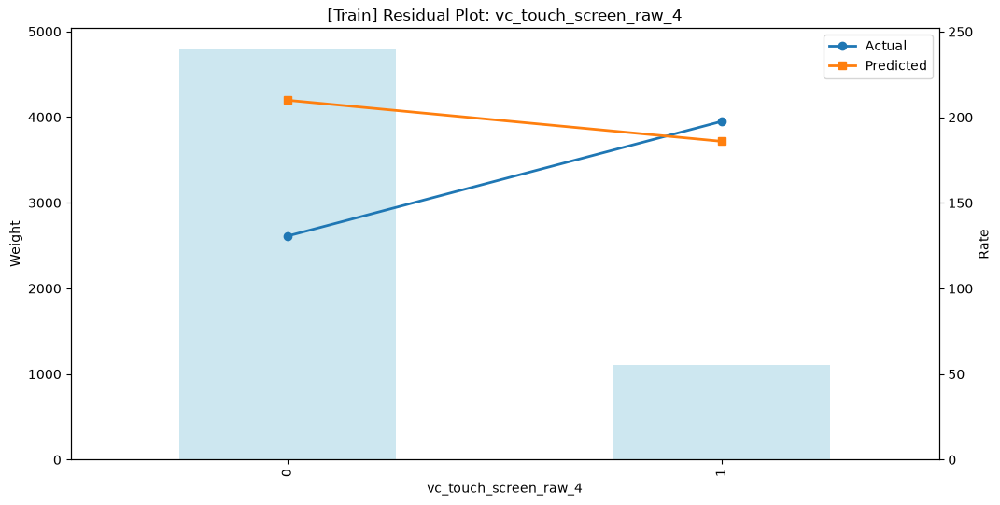

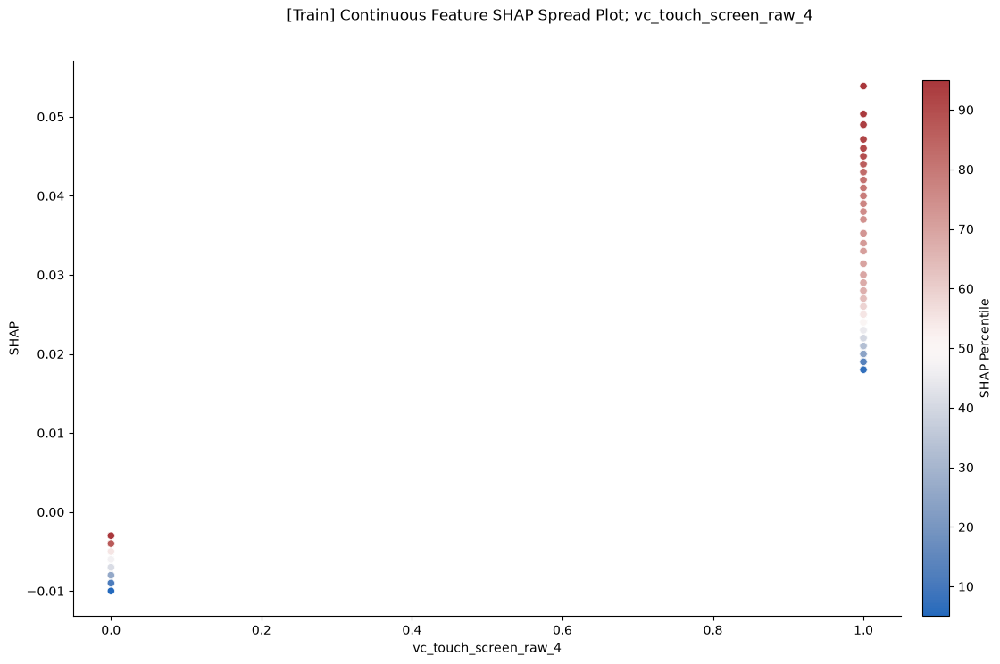

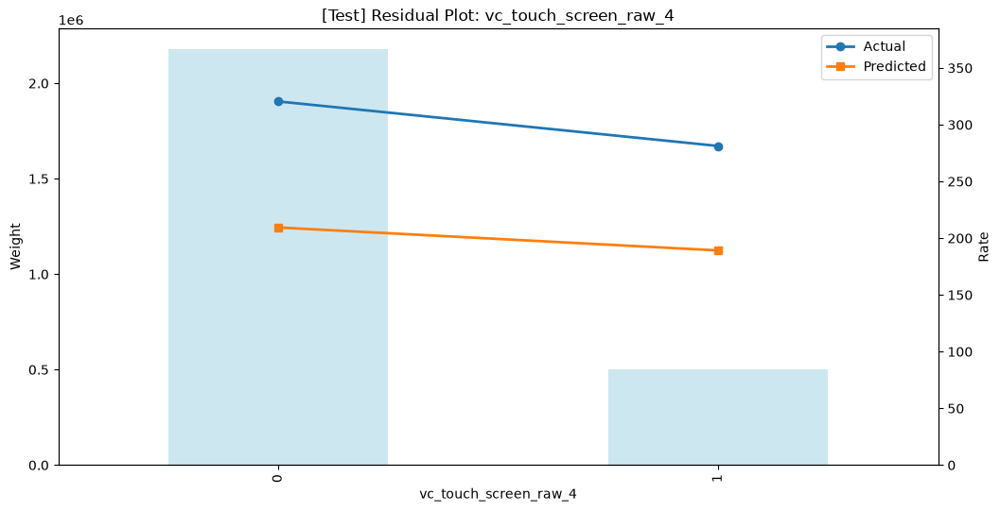

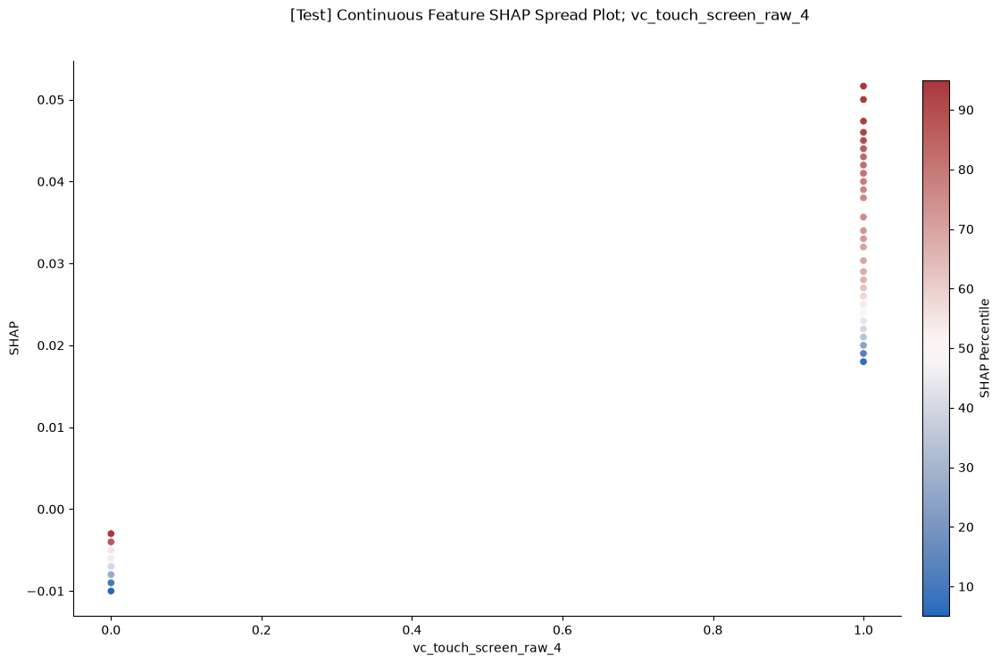


FEATURE: vc_speed_sensitive_volume_raw


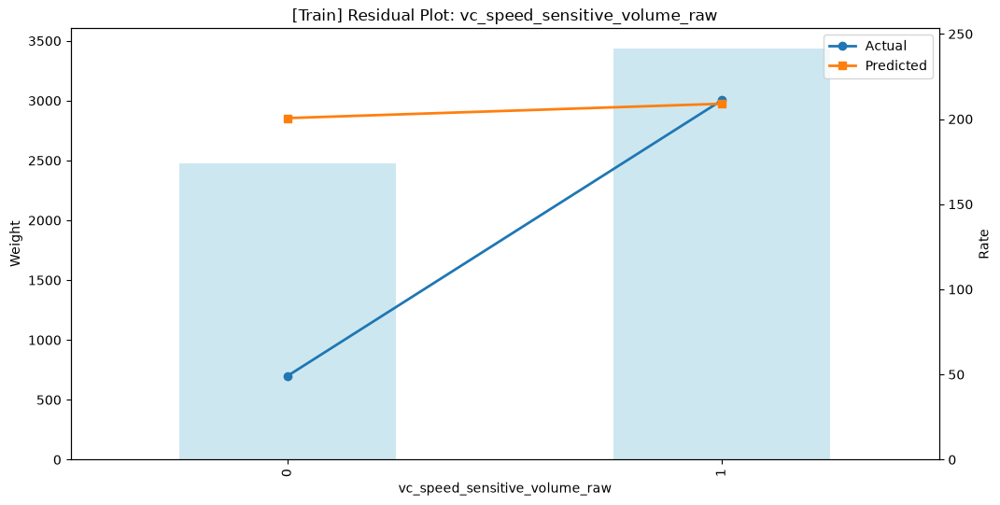

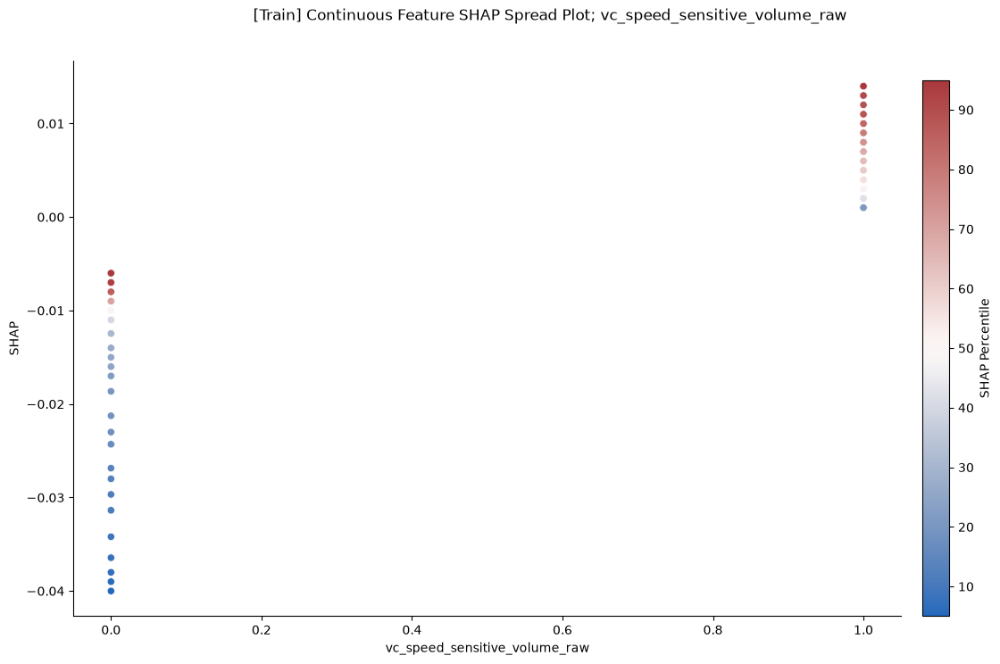

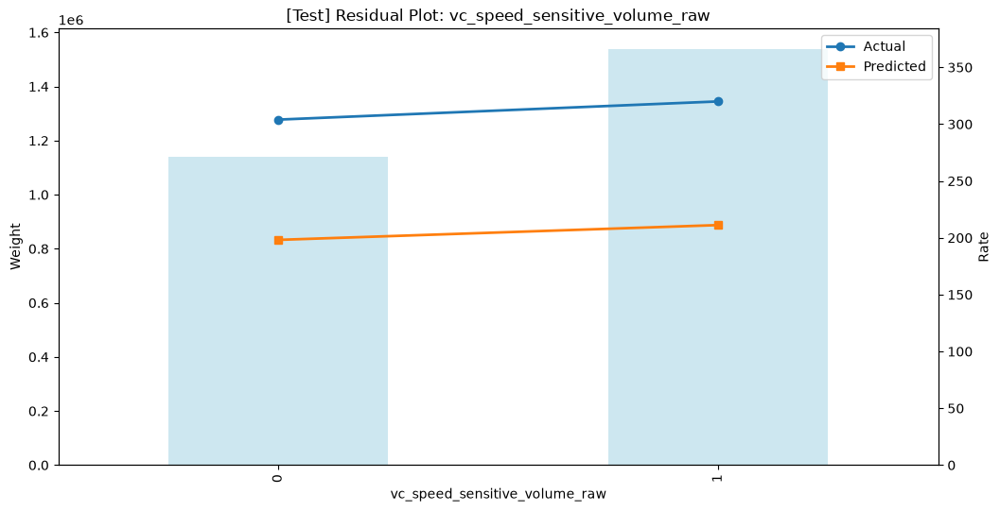

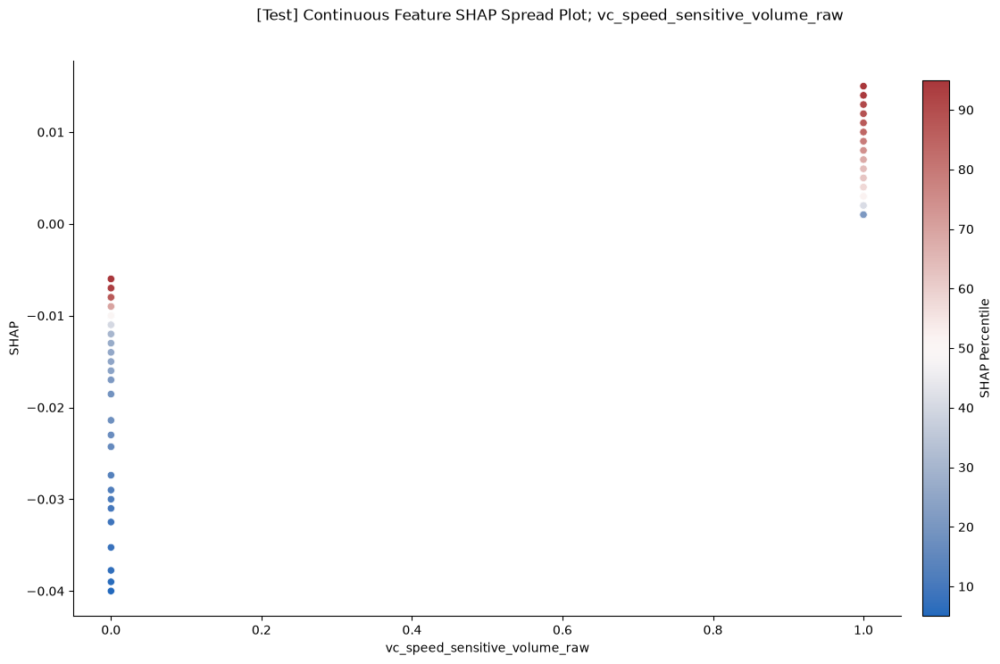


FEATURE: vc_transmission_type_automatic_ind


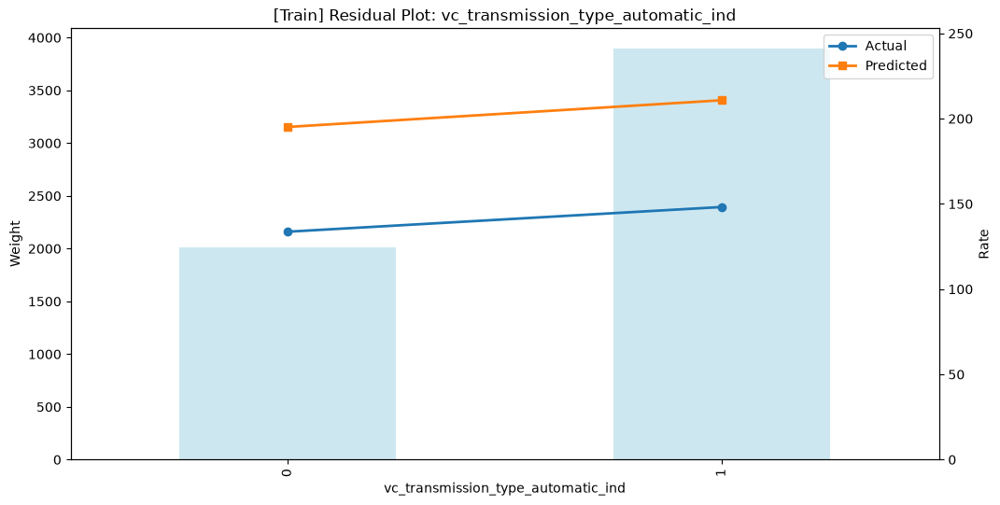

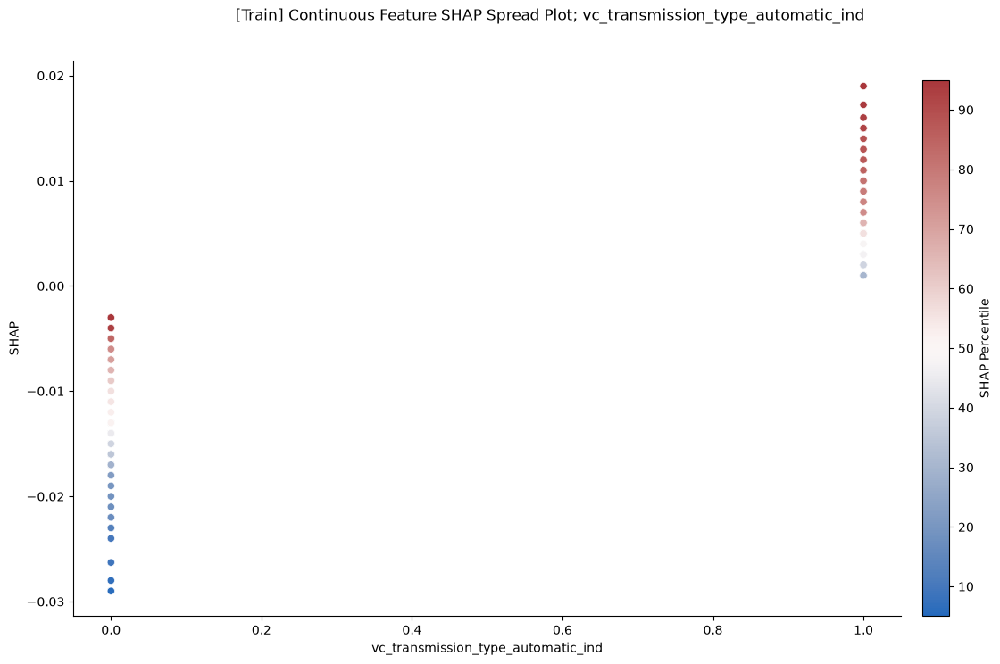

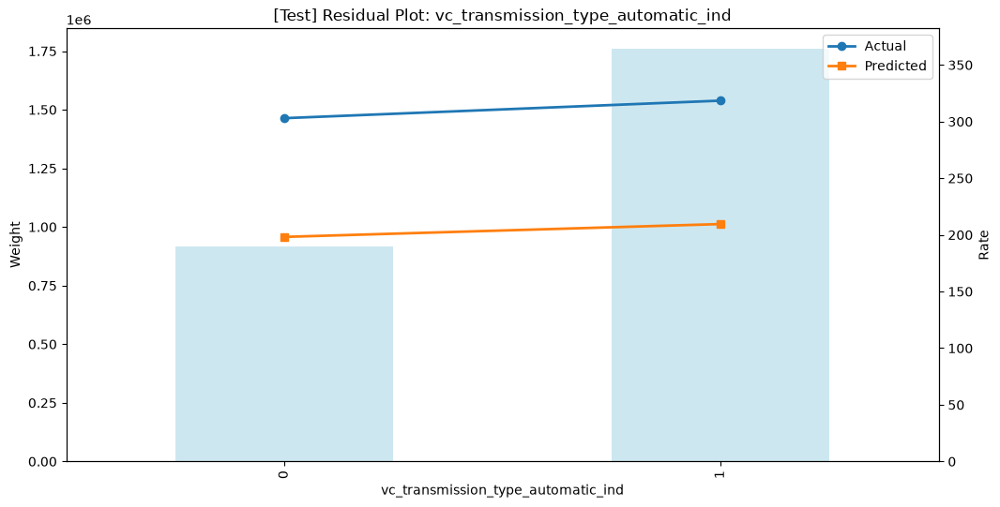

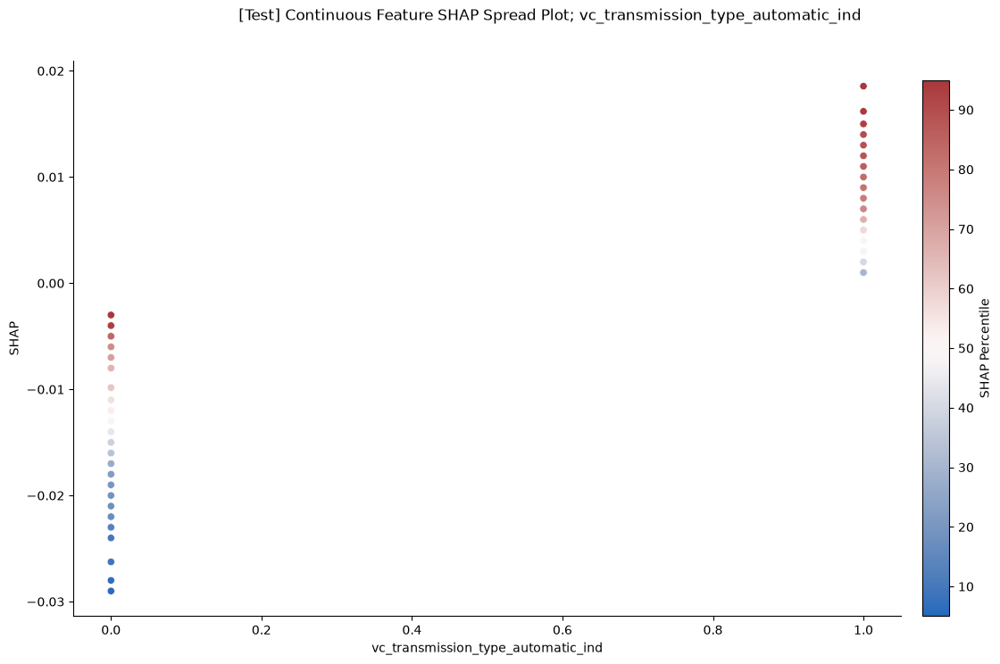


FEATURE: vc_side_mirror_turn_signals_raw


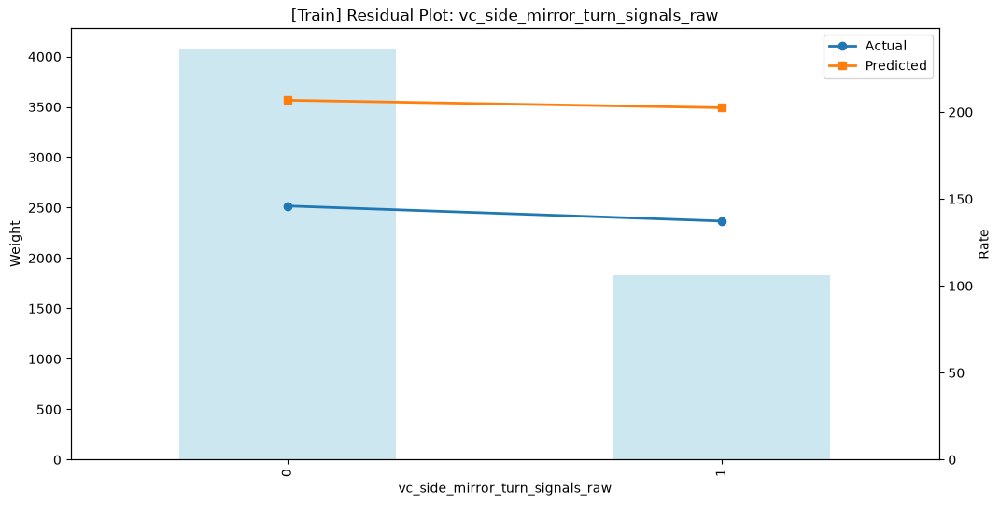

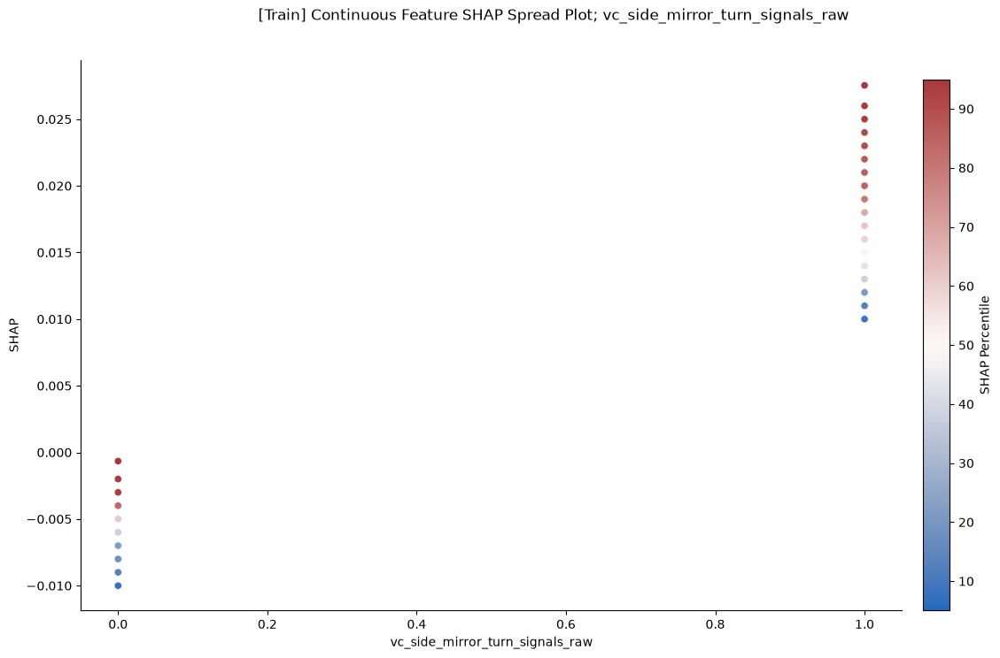

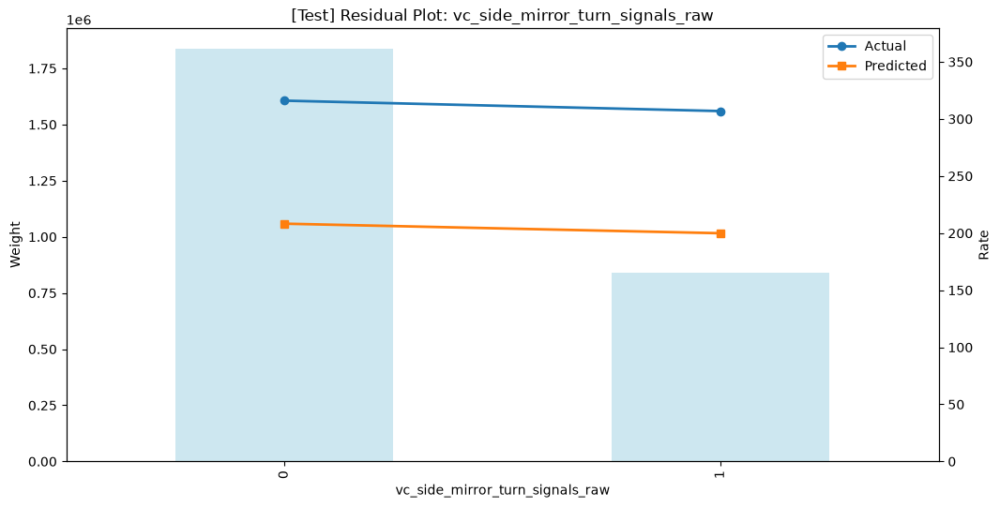

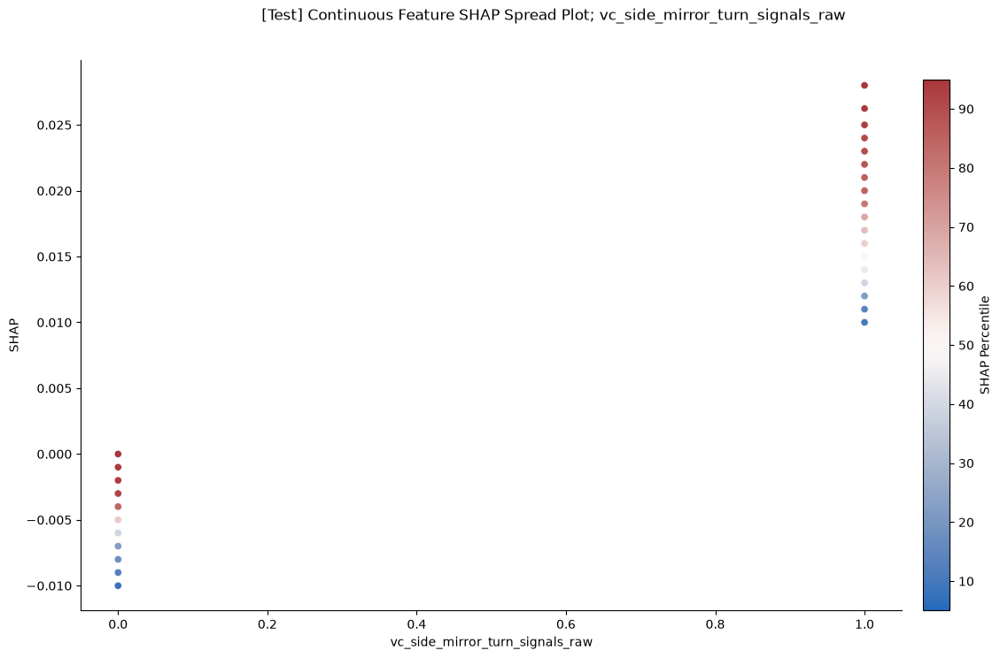


FEATURE: vc_hill_ascent_assist_raw_5


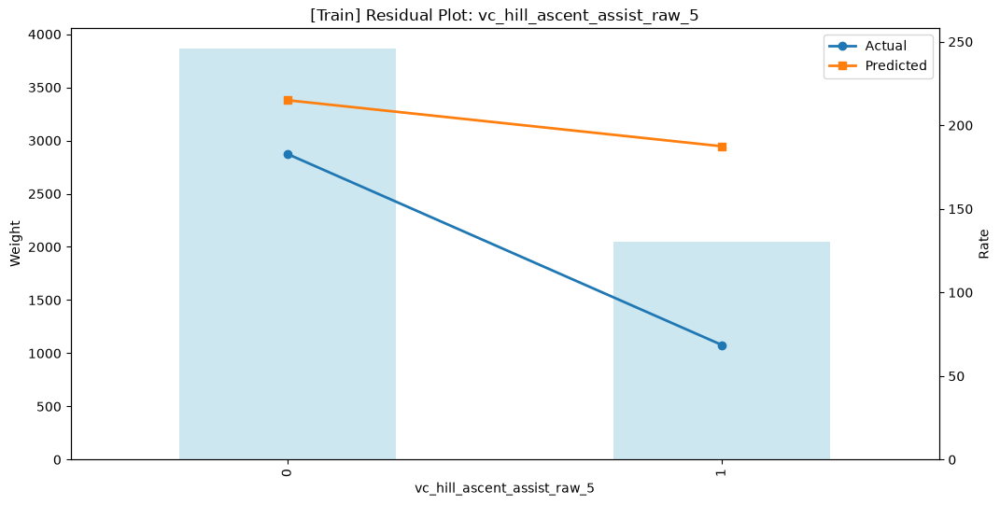

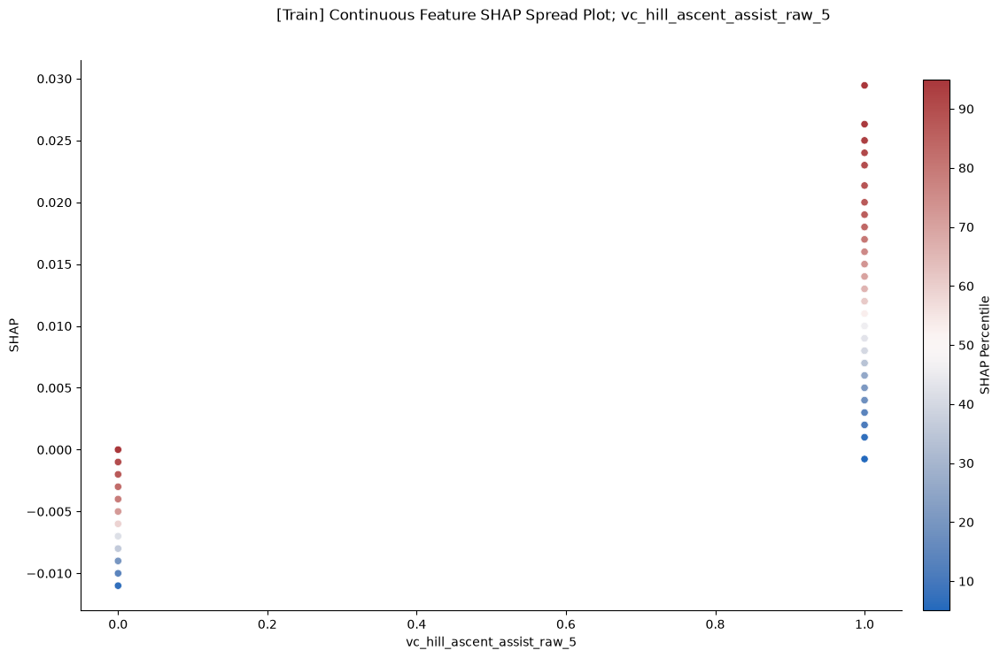

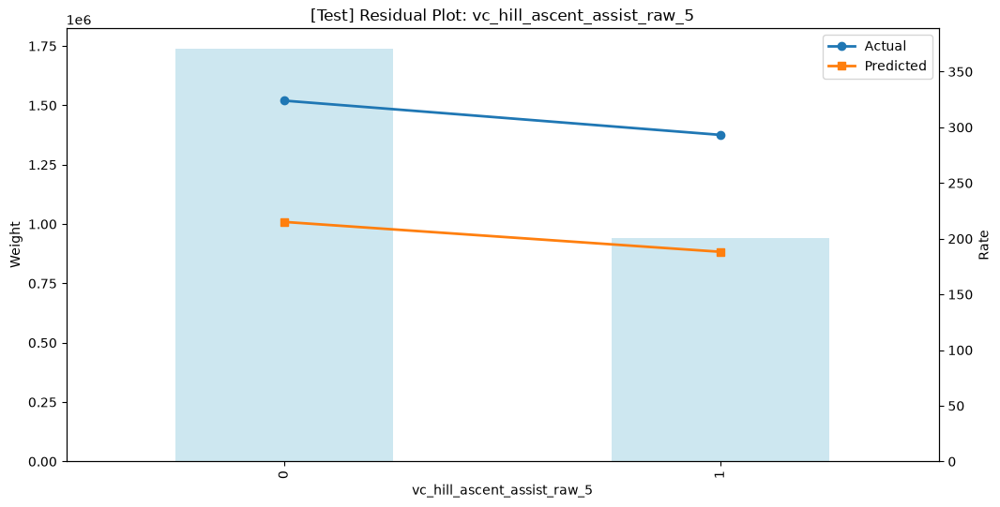

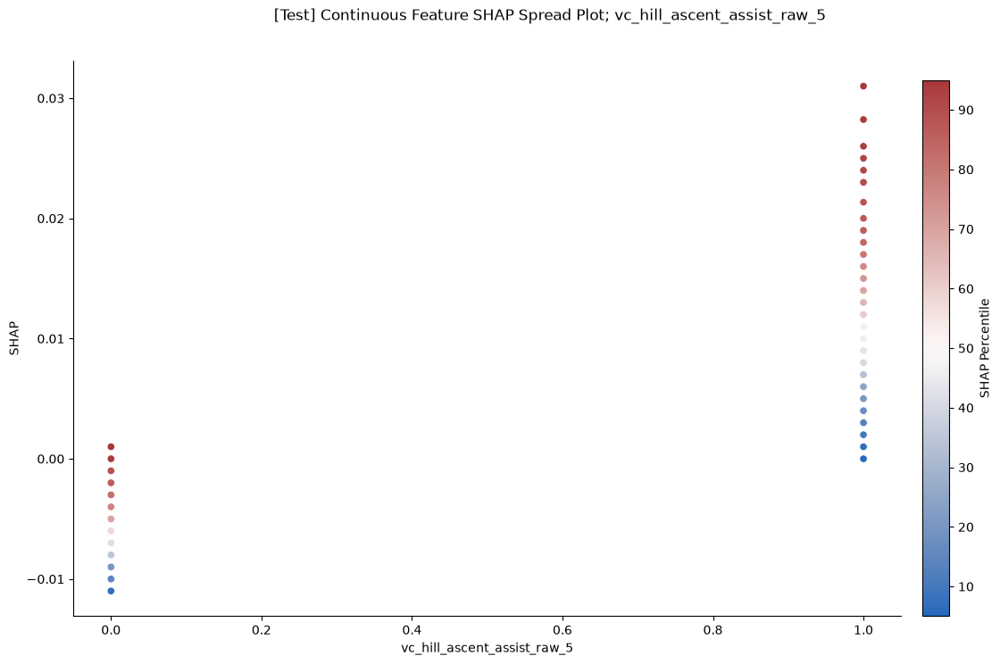


FEATURE: vc_adaptive_cruise_control_raw_5


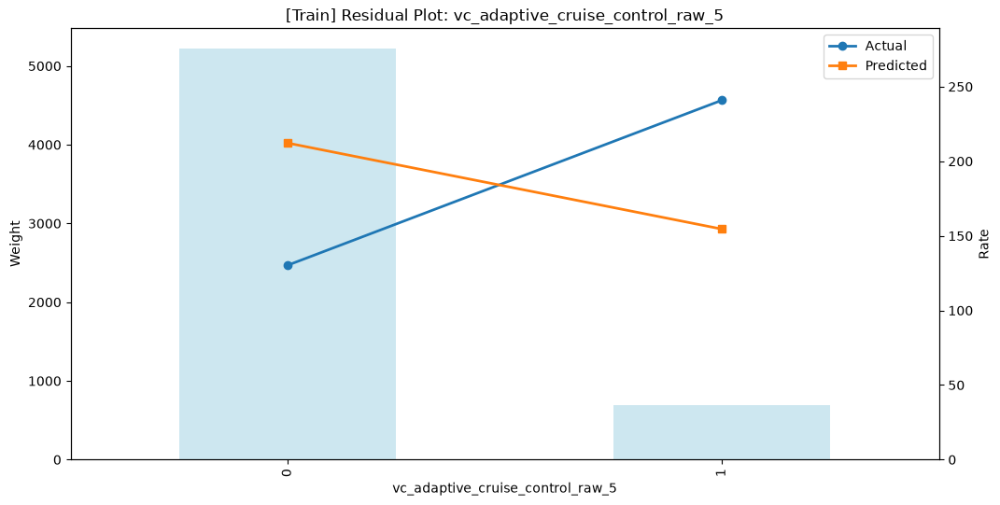

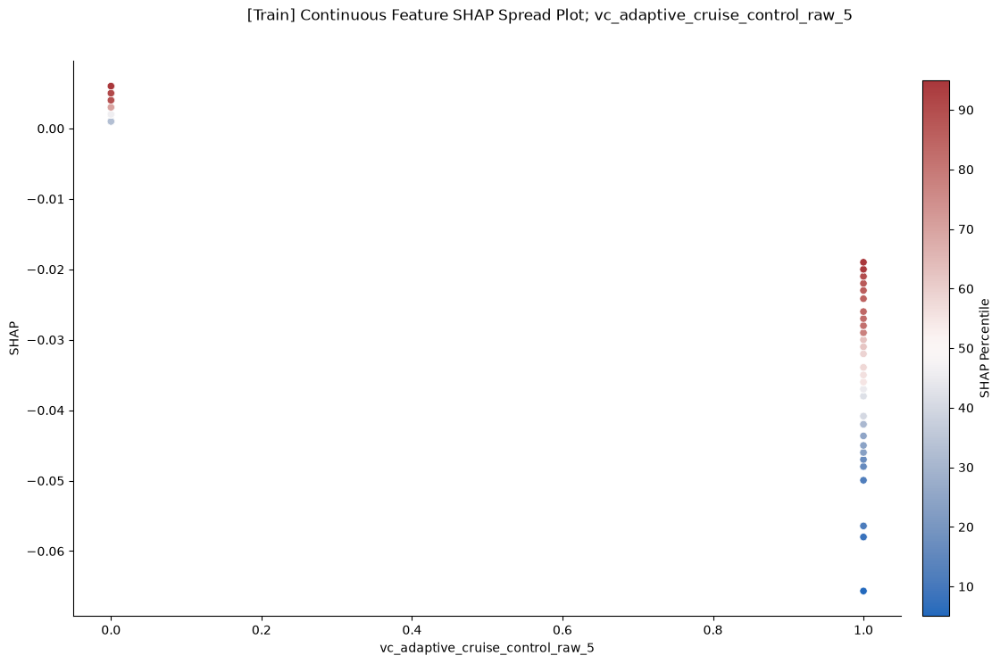

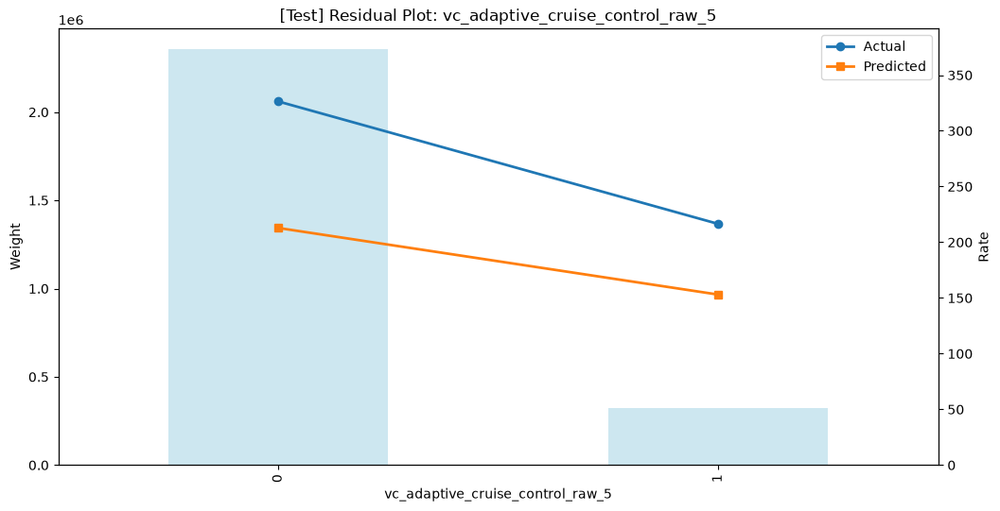

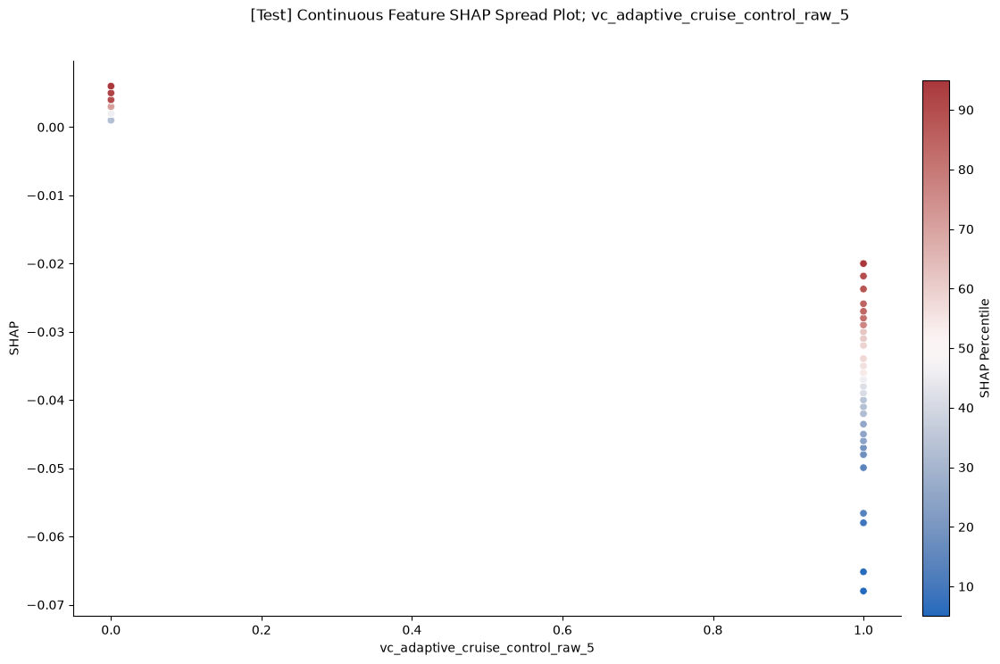


FEATURE: vc_heated_steering_wheel_raw


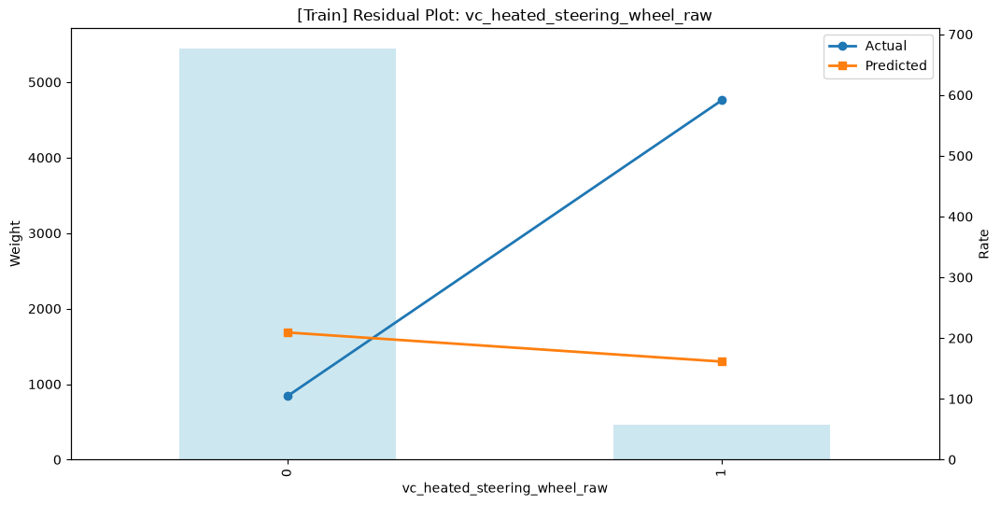

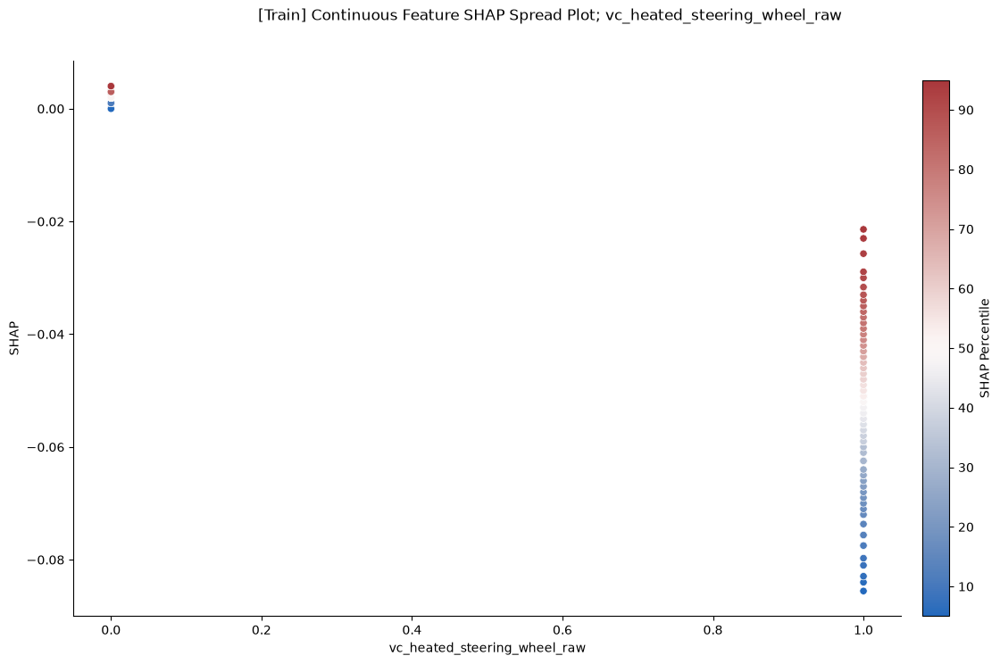

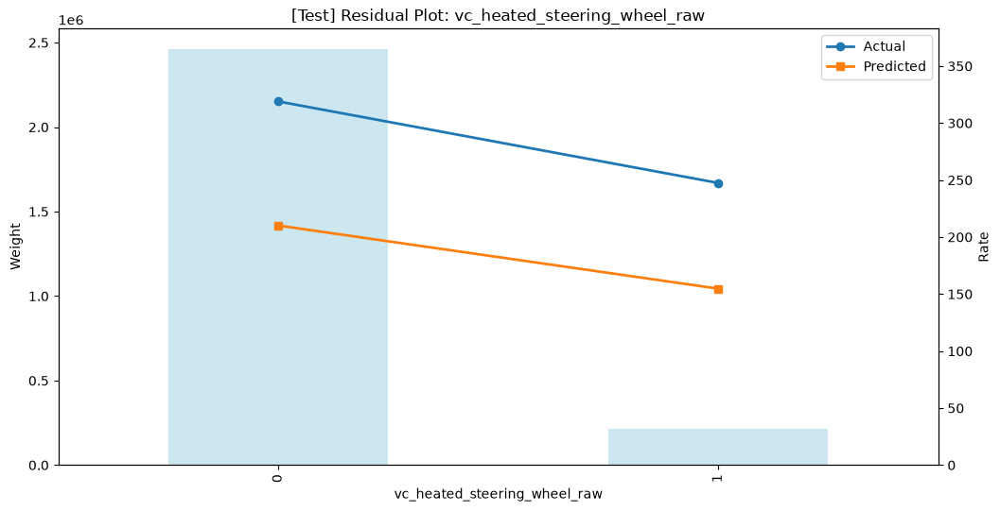

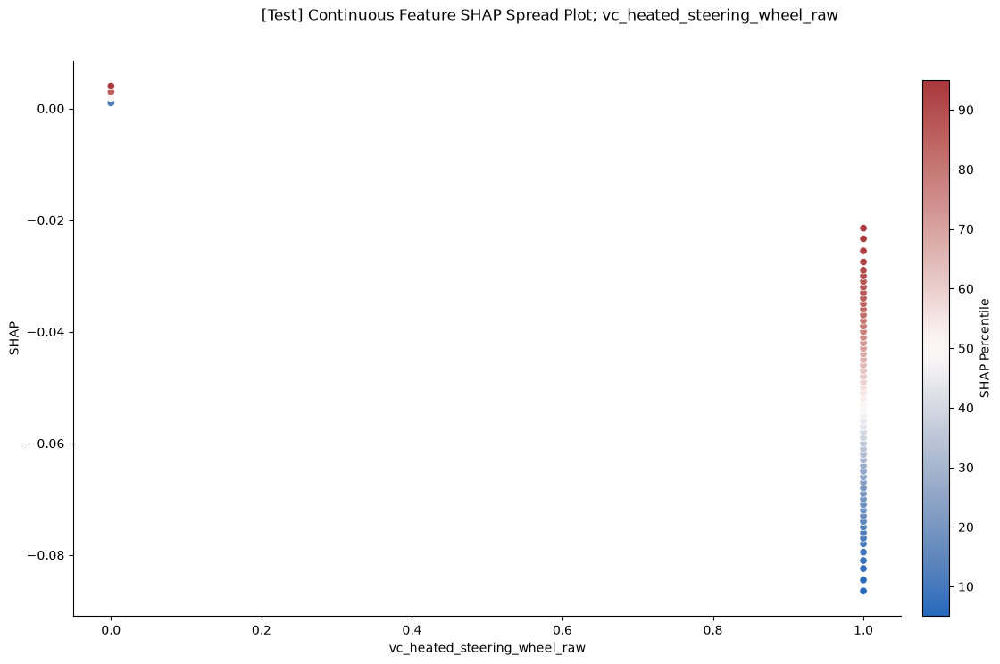


FEATURE: vc_seating_rows_raw


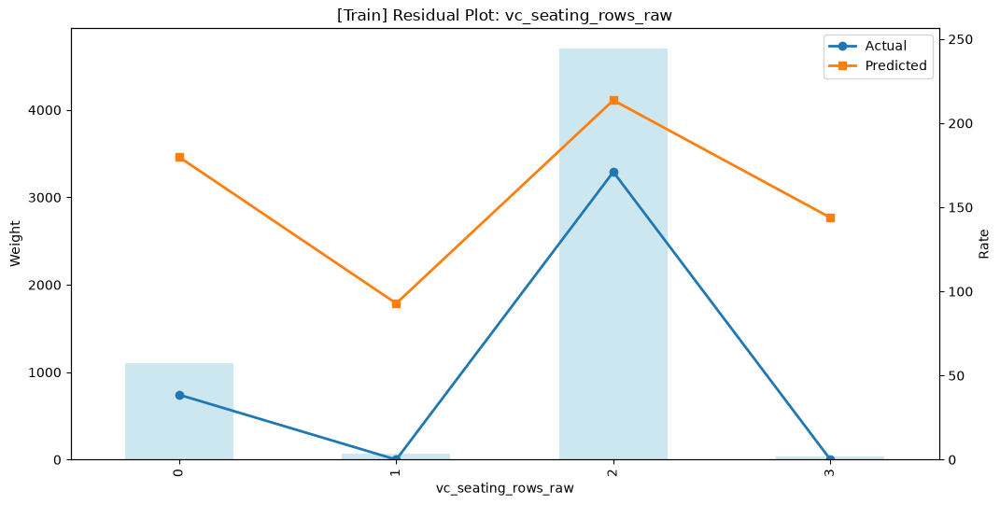

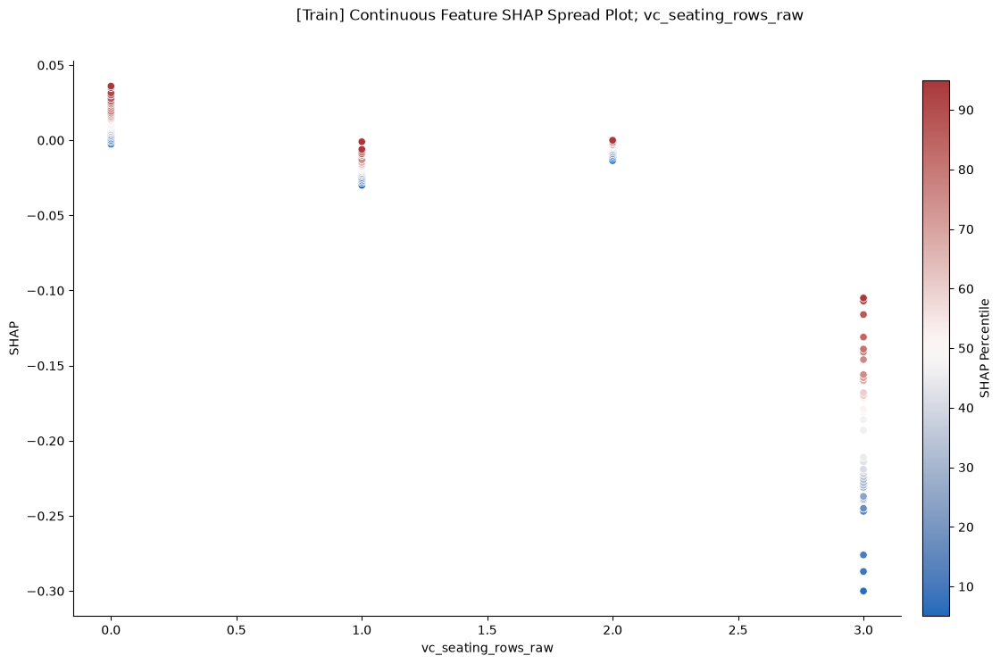

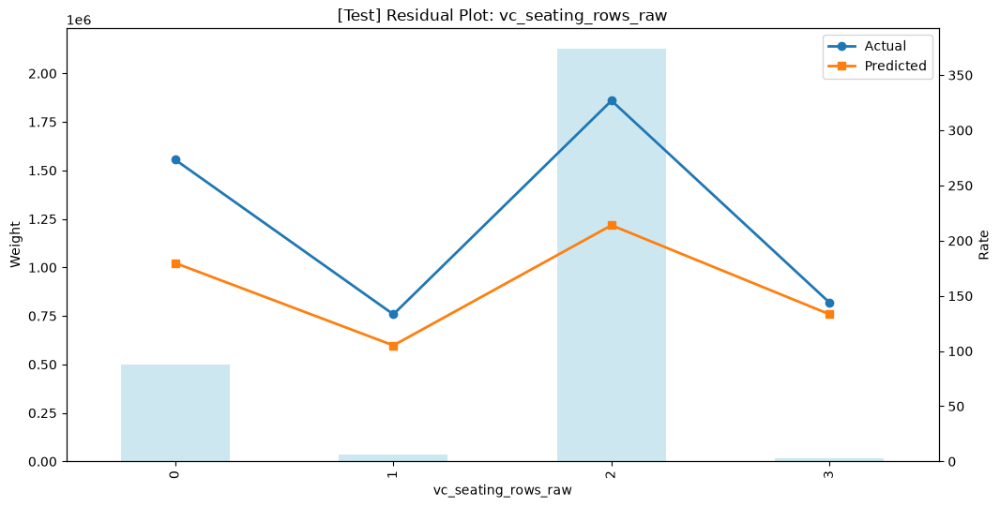

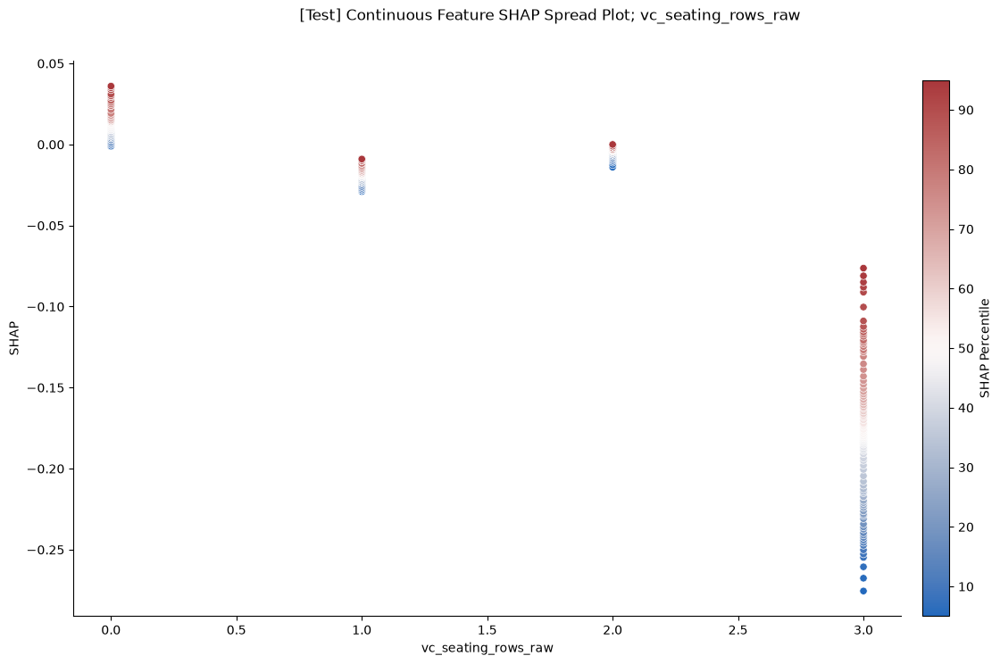


FEATURE: vc_taillights_led_raw


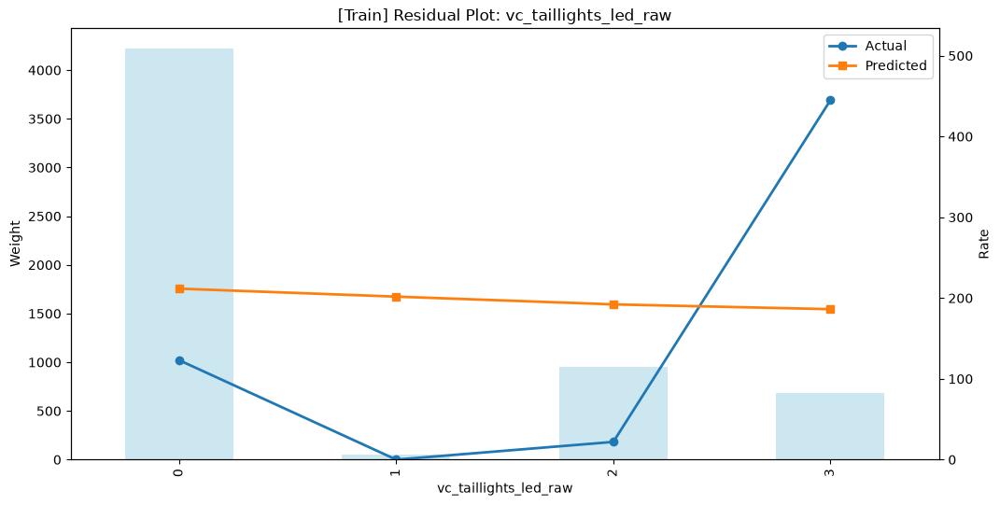

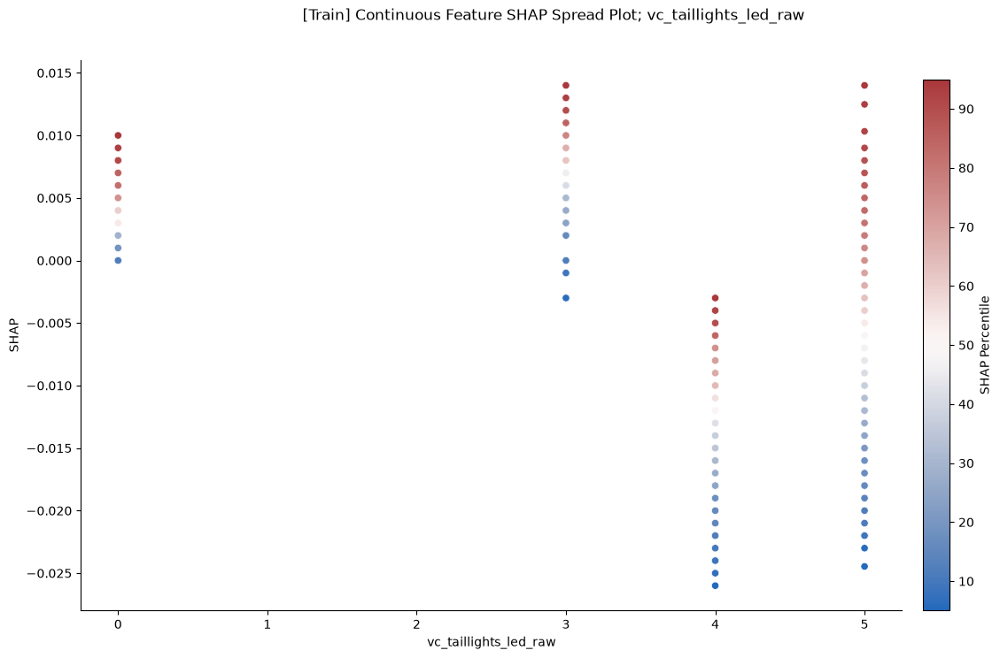

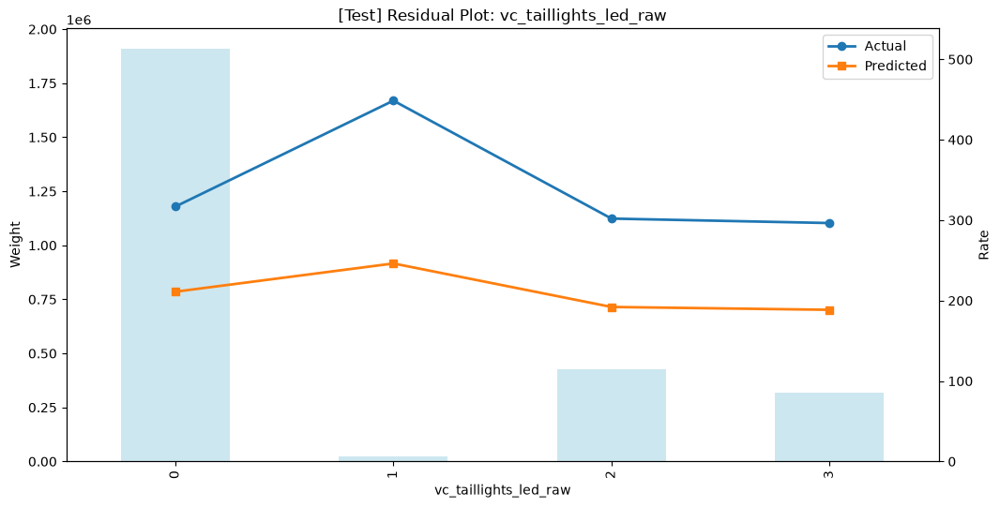

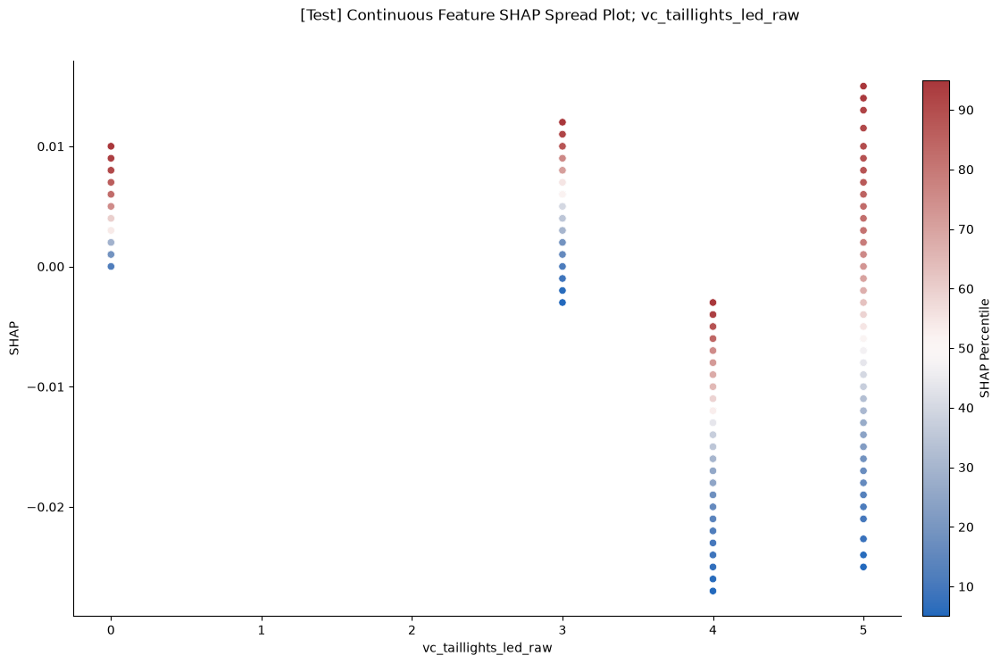


FEATURE: vc_drive_type_awd_ind


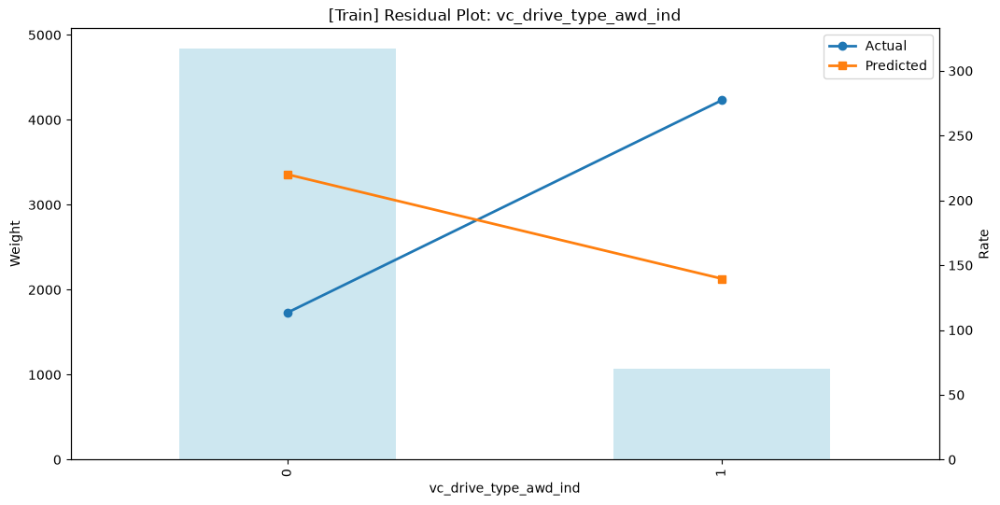

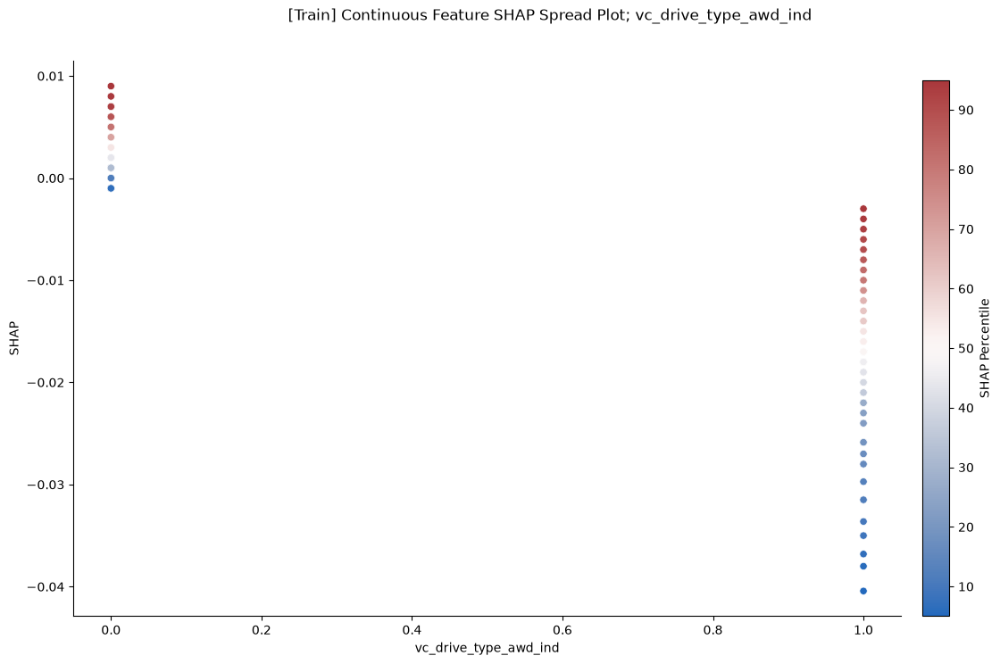

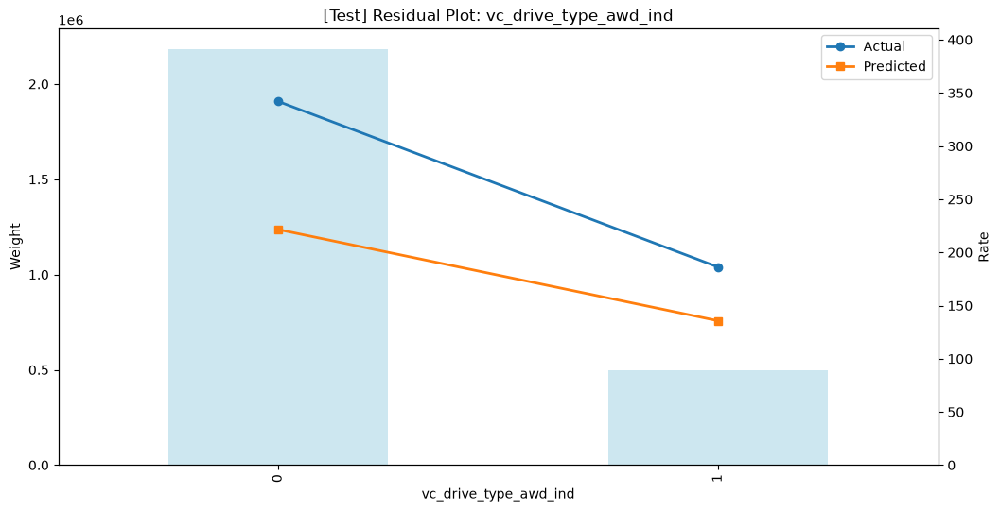

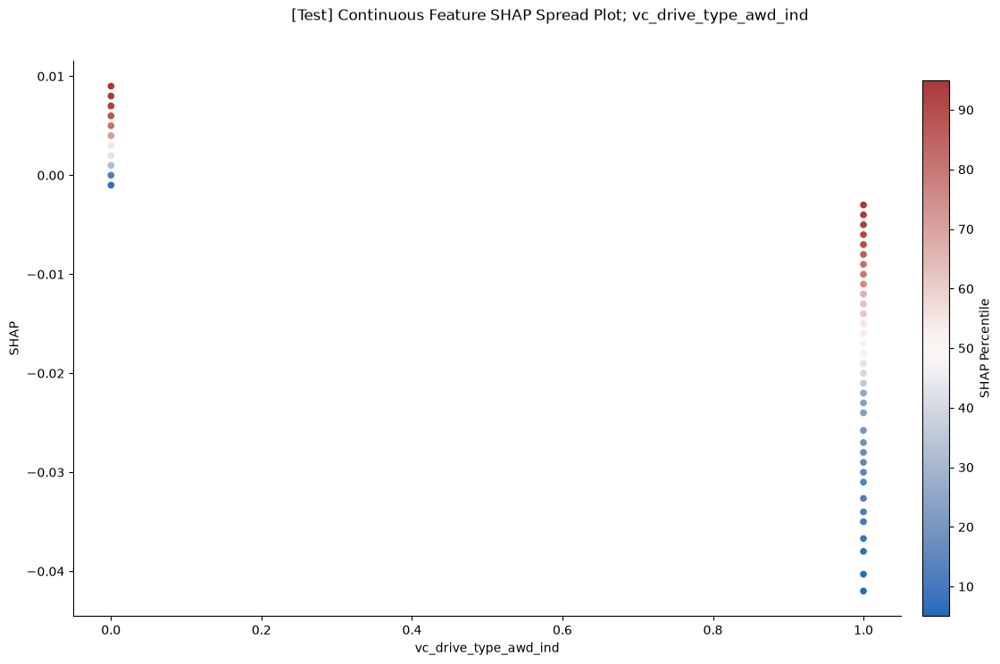


FEATURE: vc_tinted_windows_raw_5


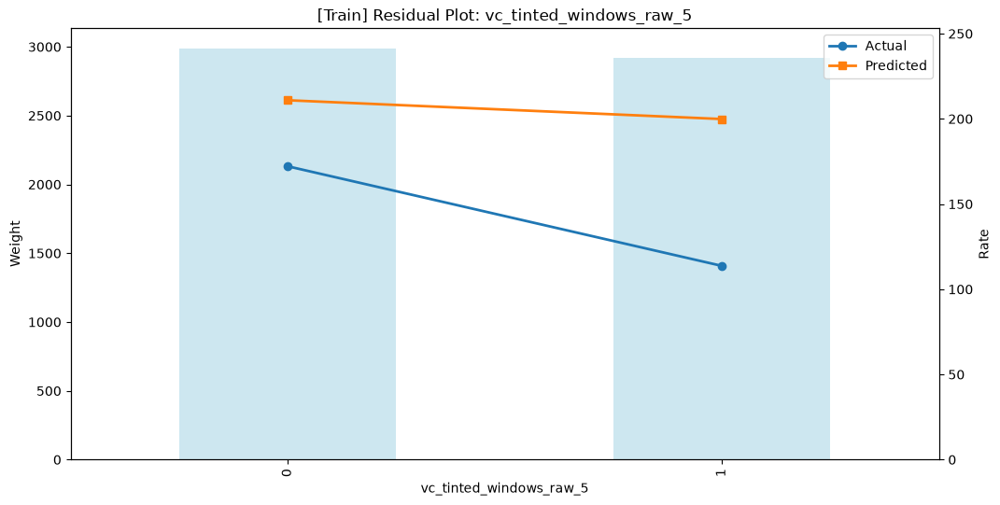

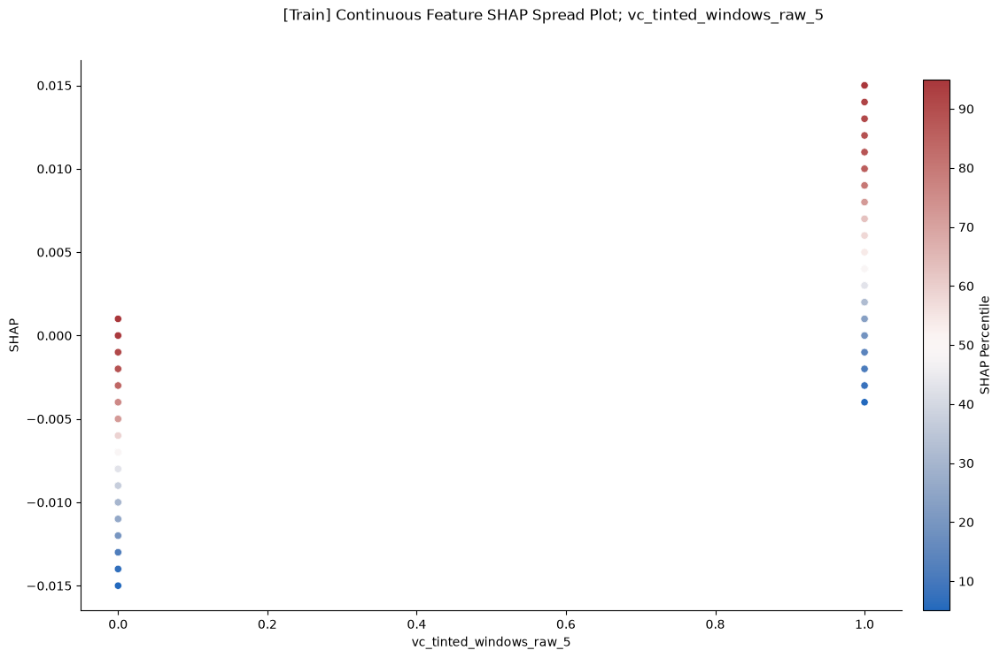

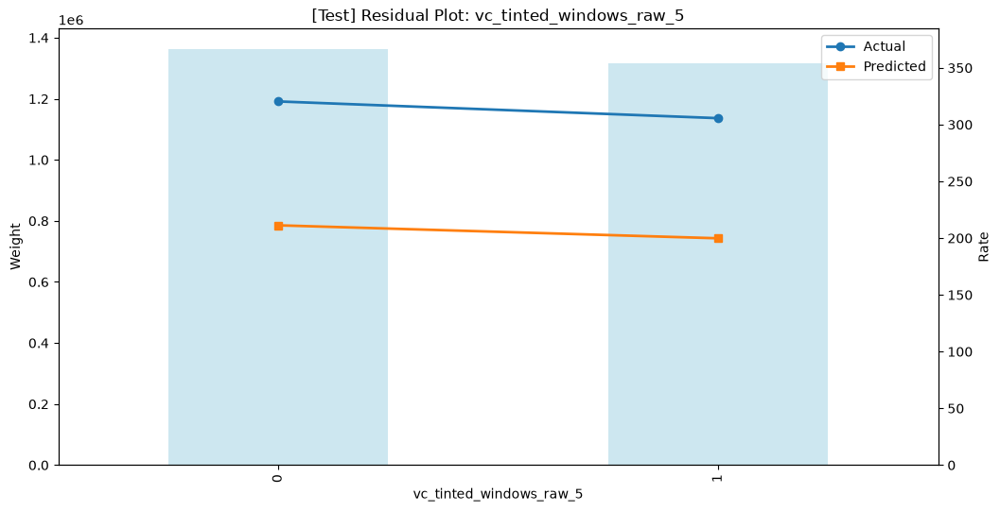

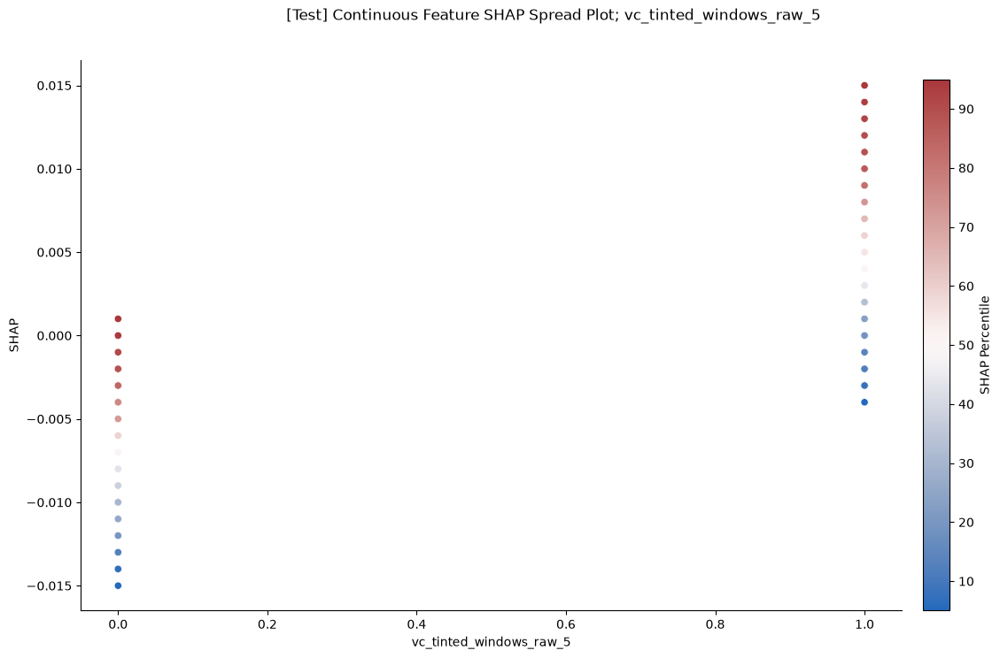


FEATURE: vc_remote_engine_start_raw_5


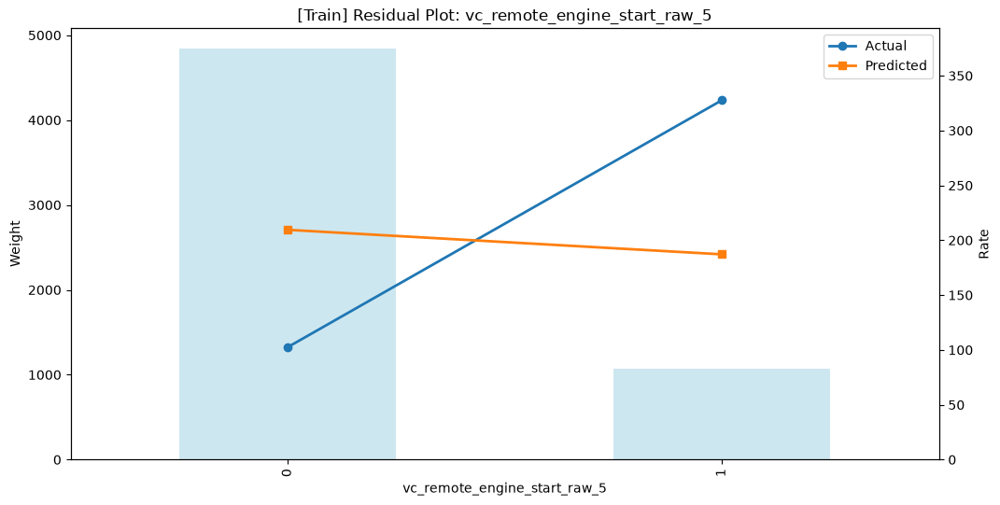

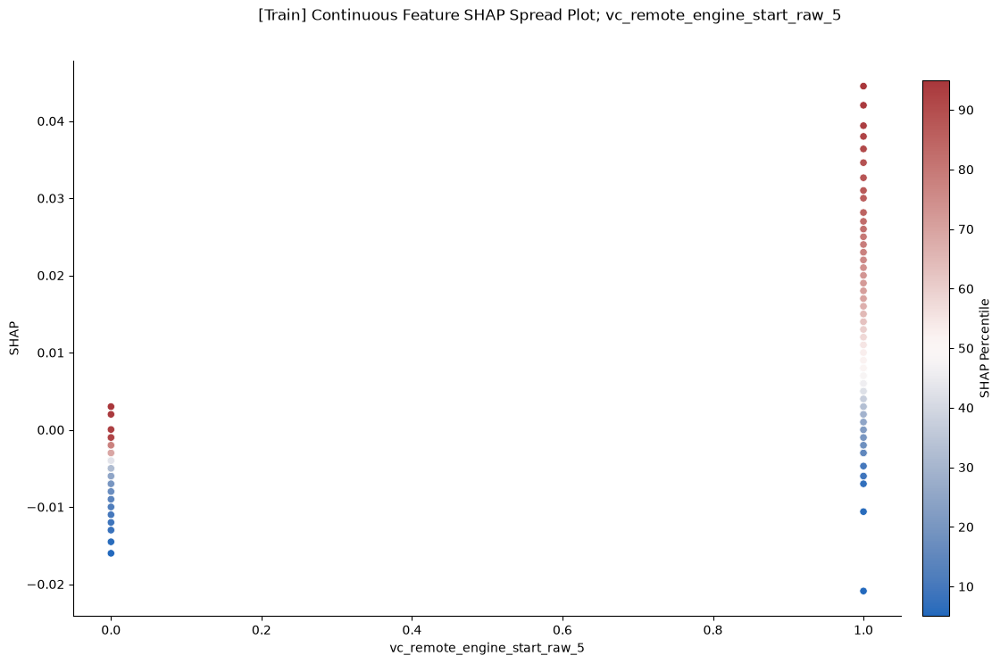

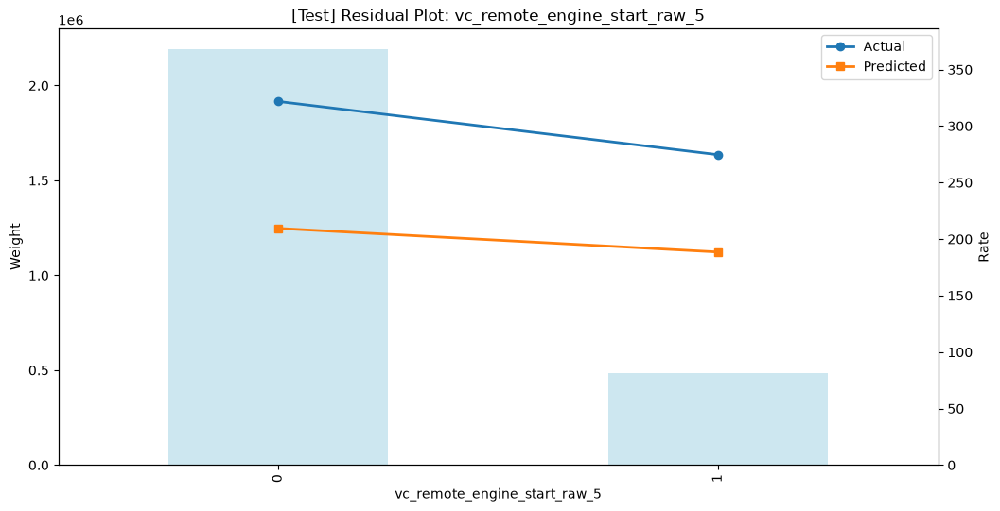

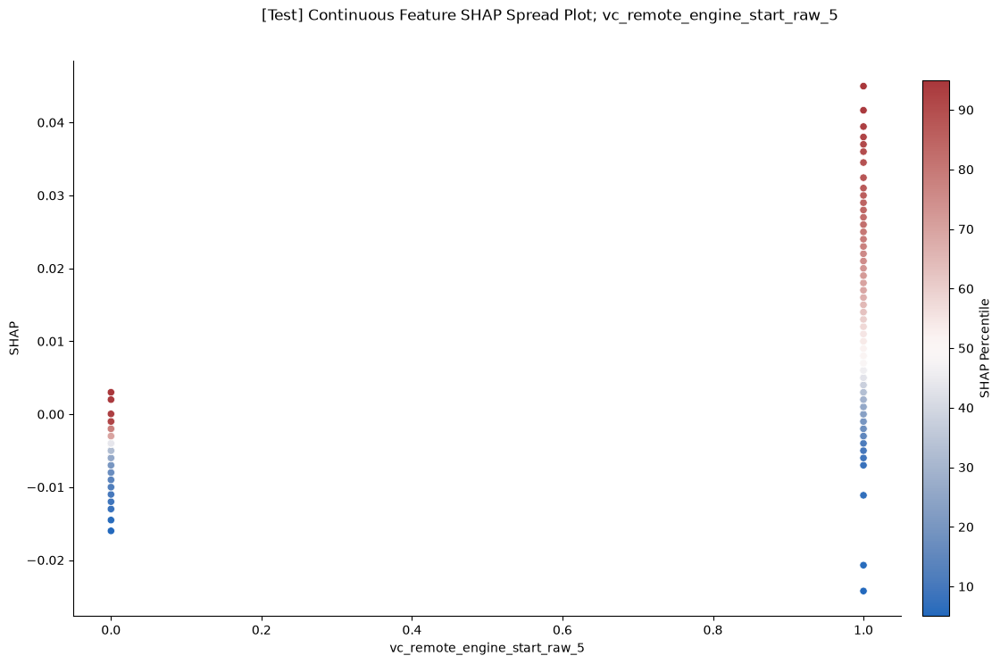


FEATURE: vc_drive_type_rwd_ind


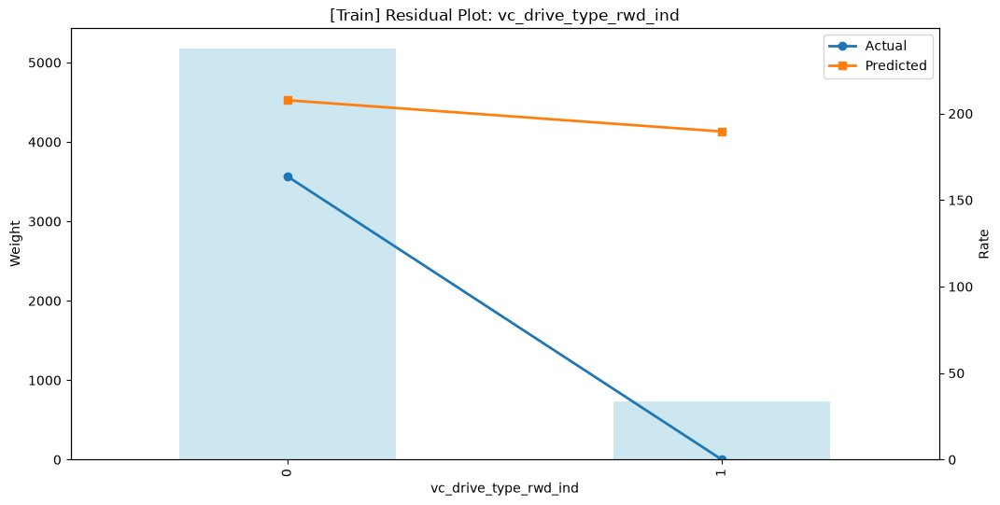

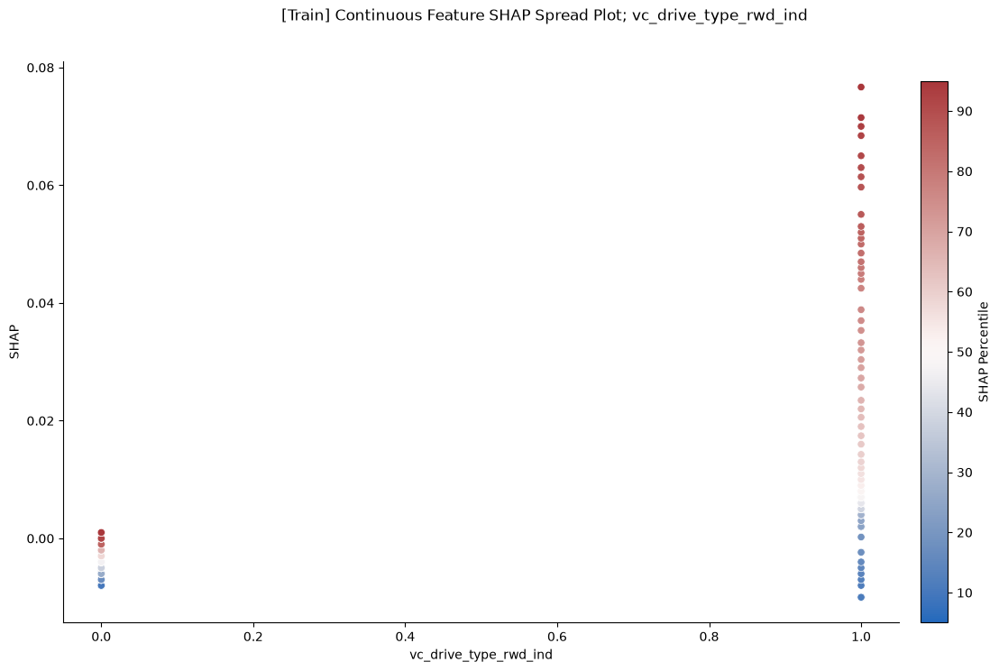

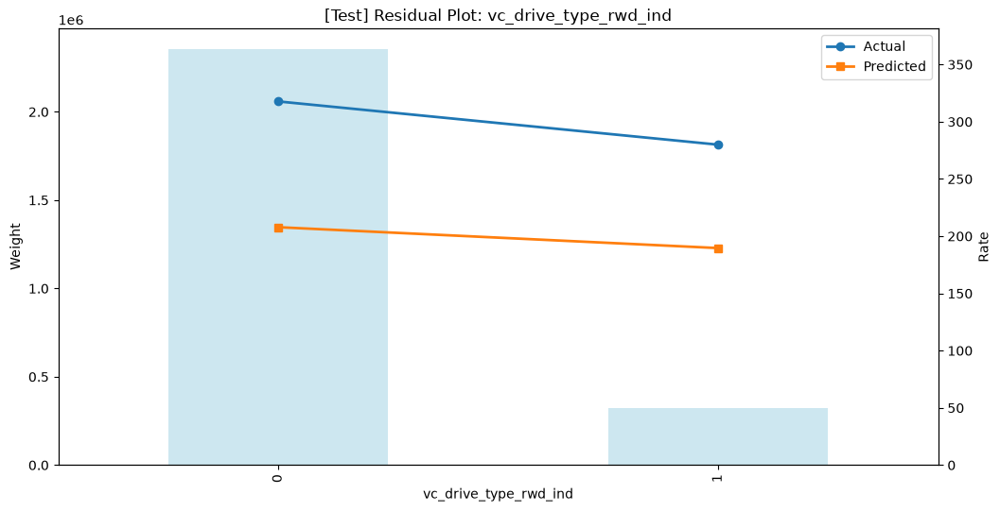

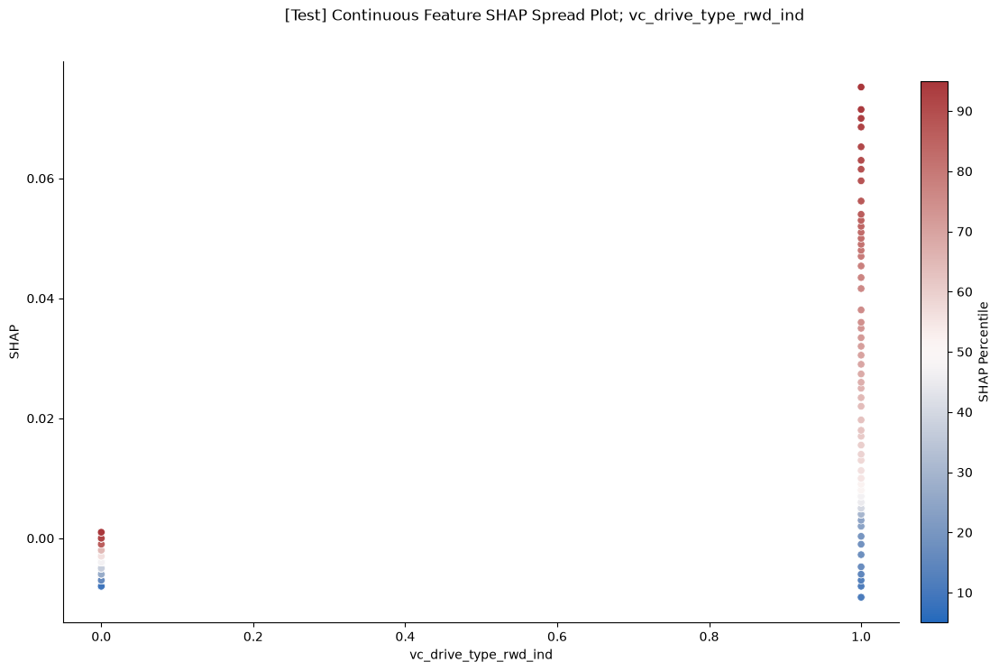


FEATURE: vc_lane_keeping_assistance_raw


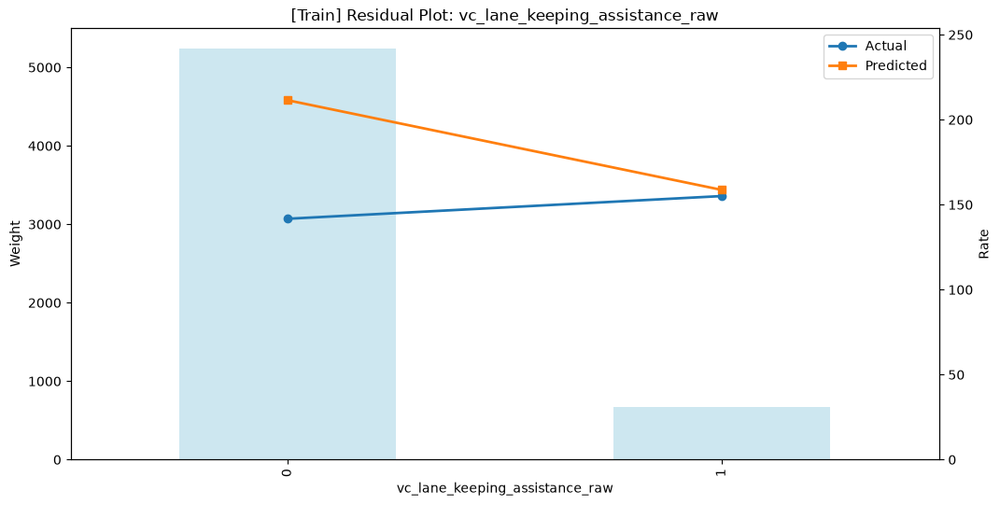

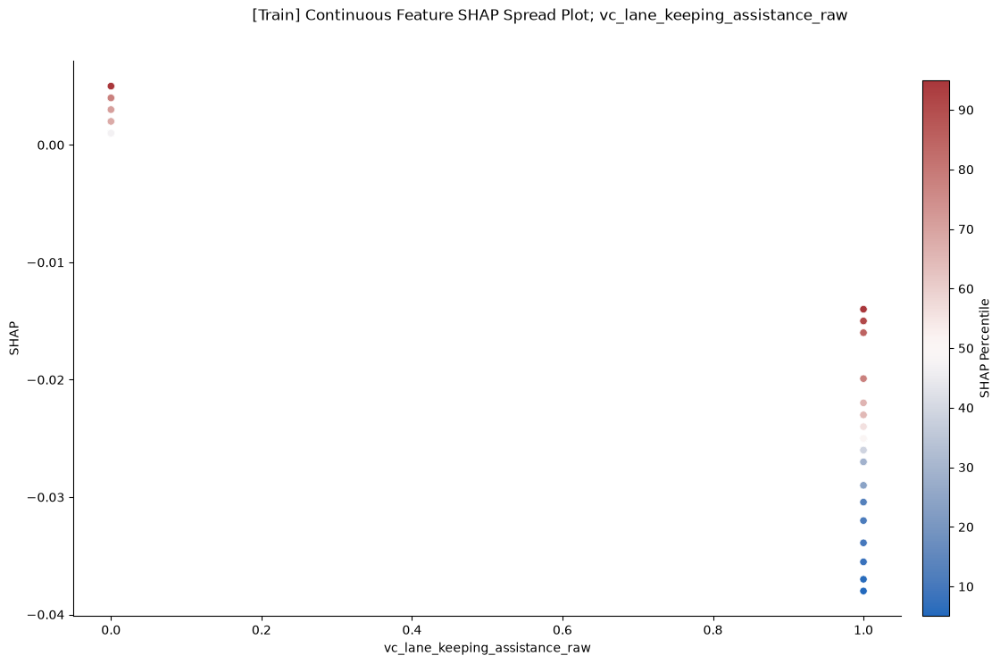

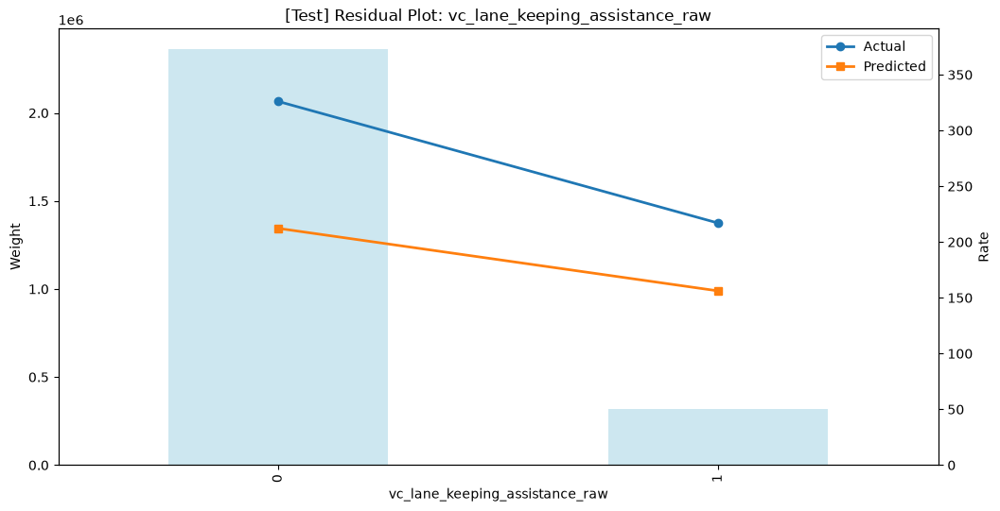

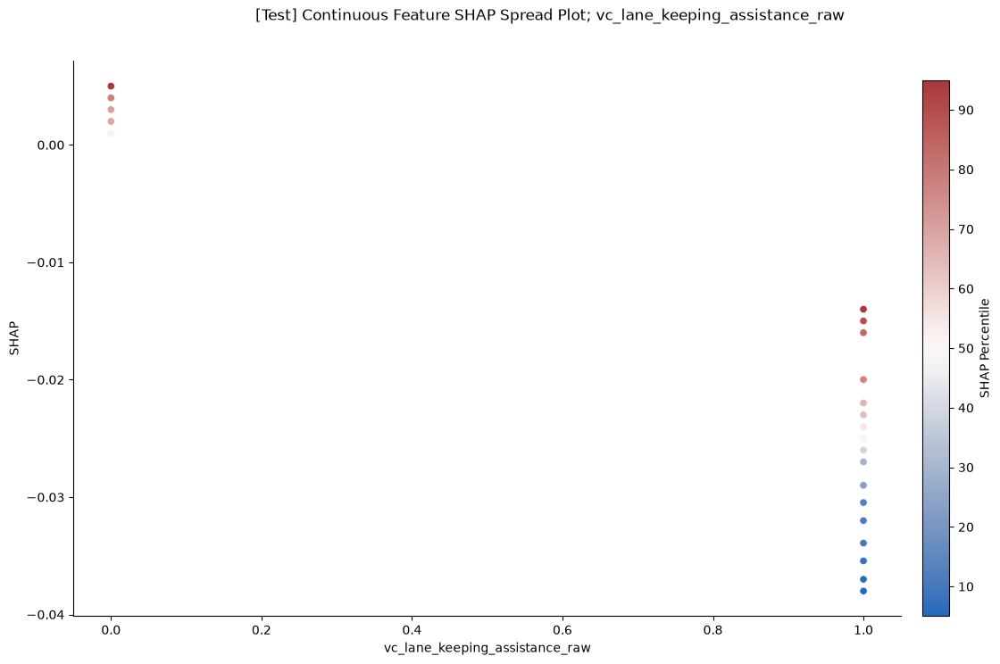


FEATURE: vc_power_sunroof_raw_0


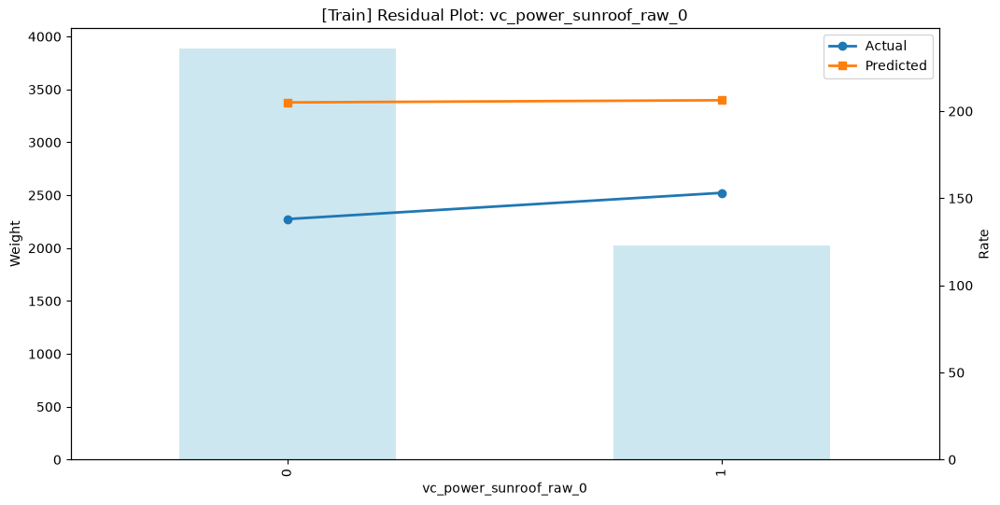

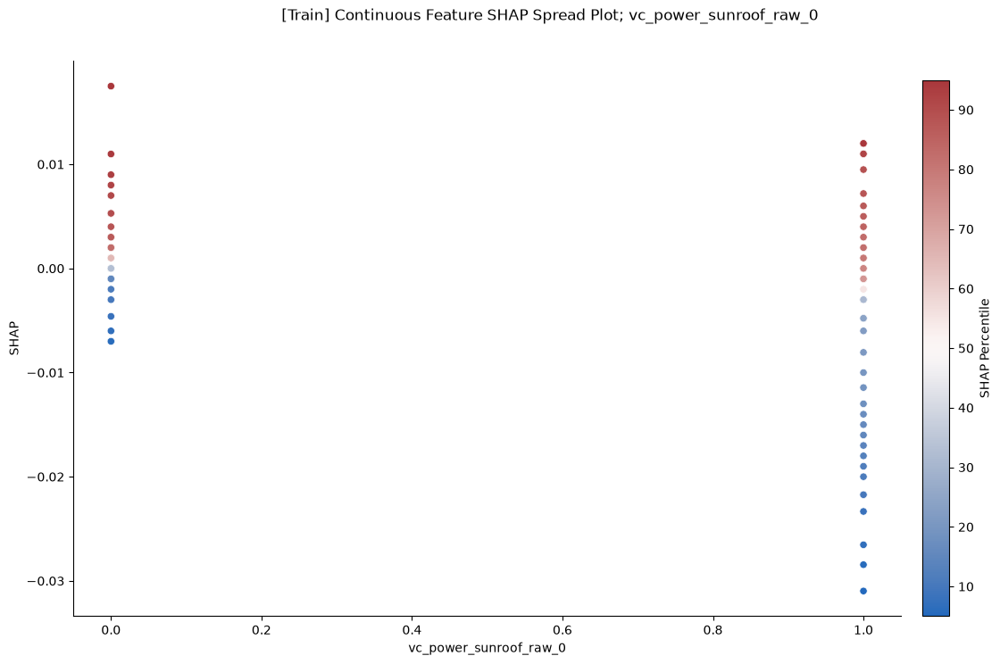

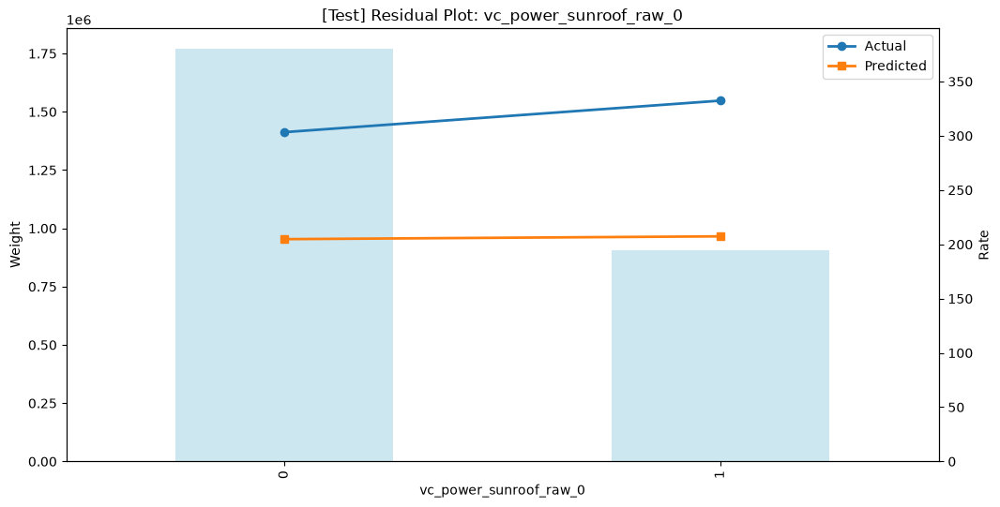

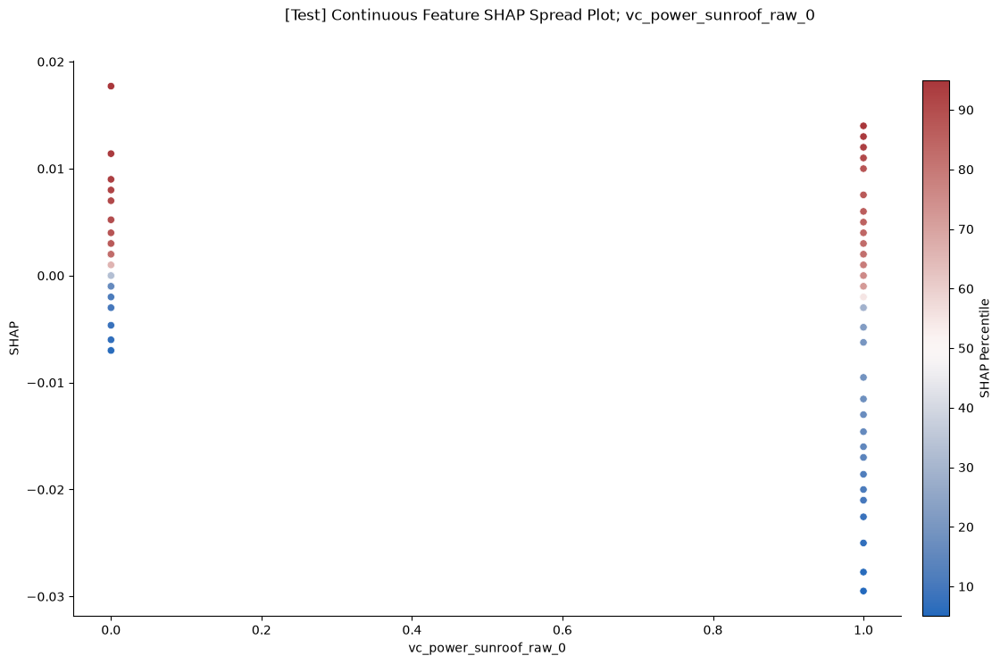


FEATURE: vc_heated_side_mirrors_raw


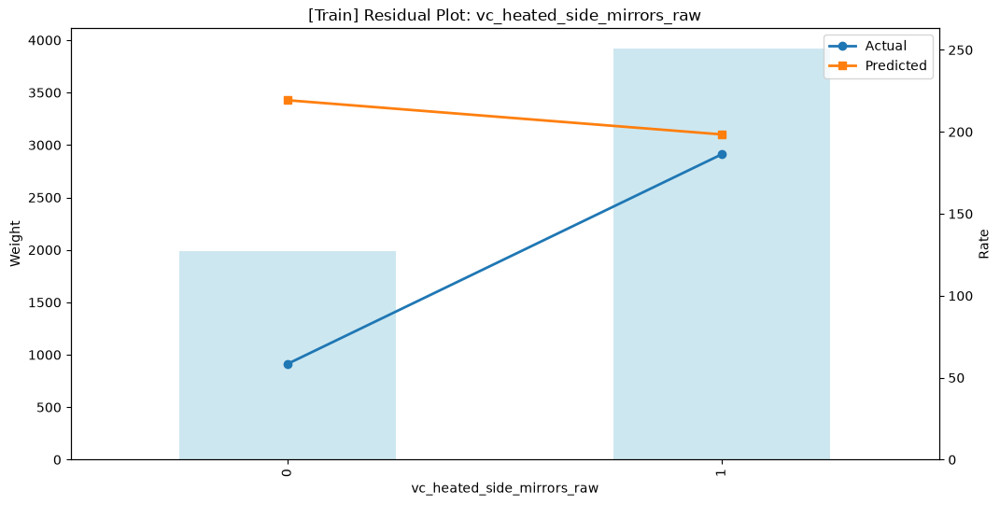

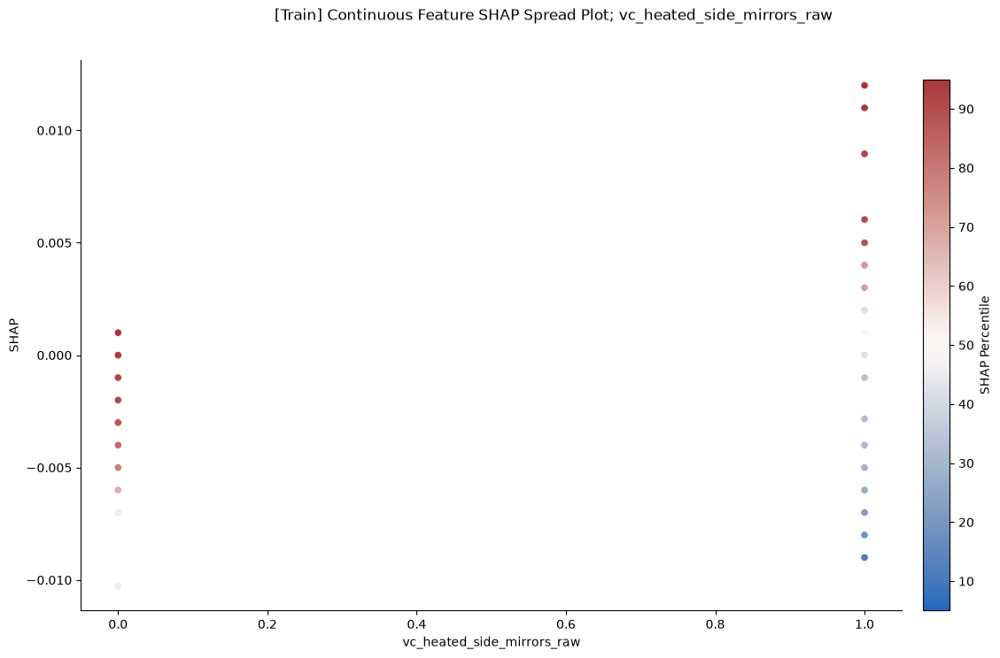

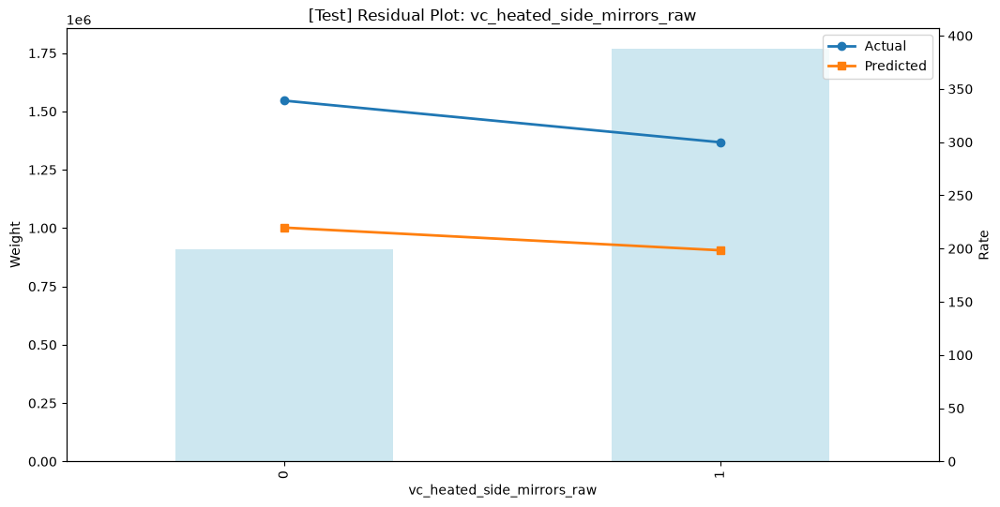

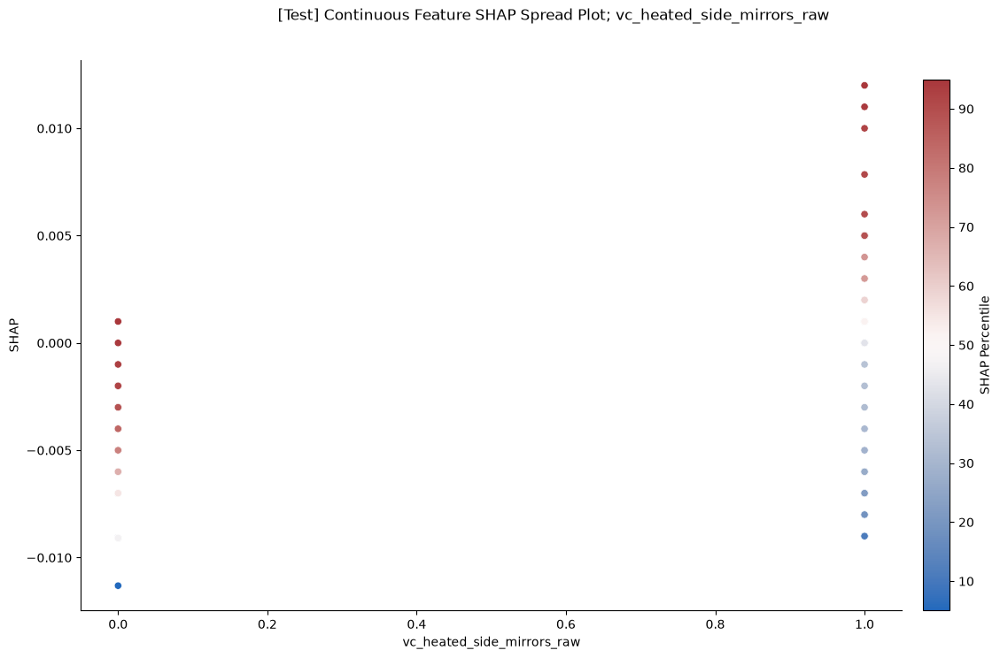


FEATURE: vc_electronic_braking_system_raw_0


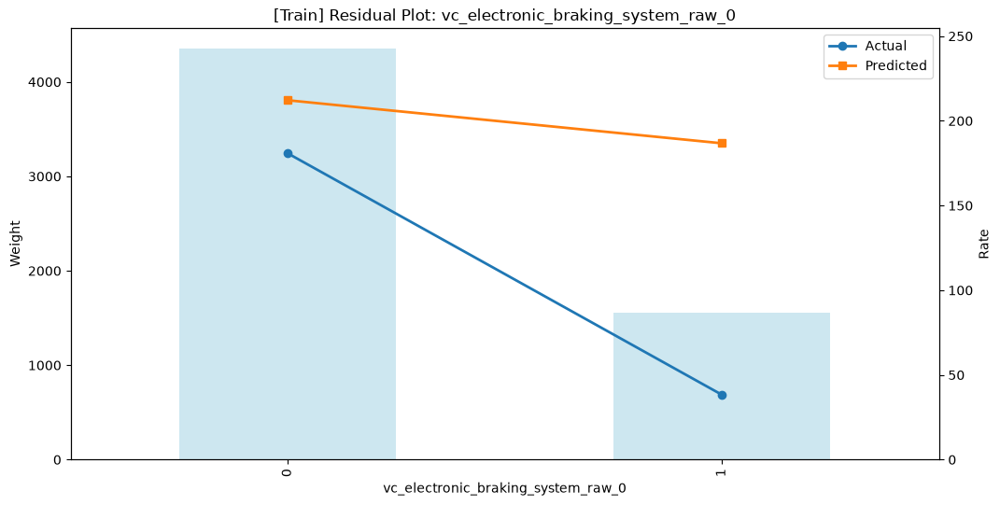

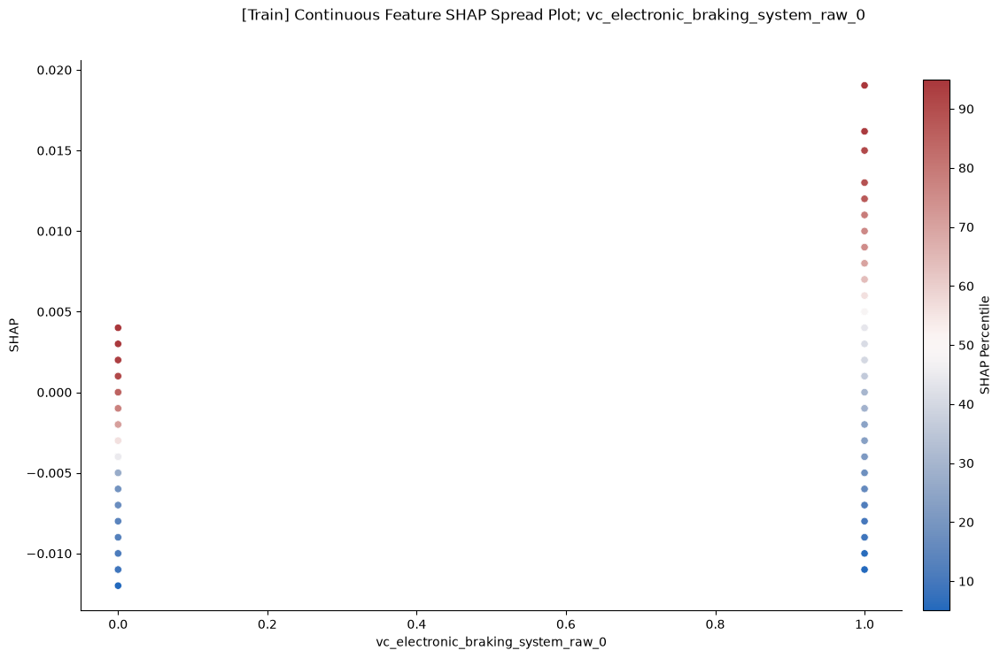

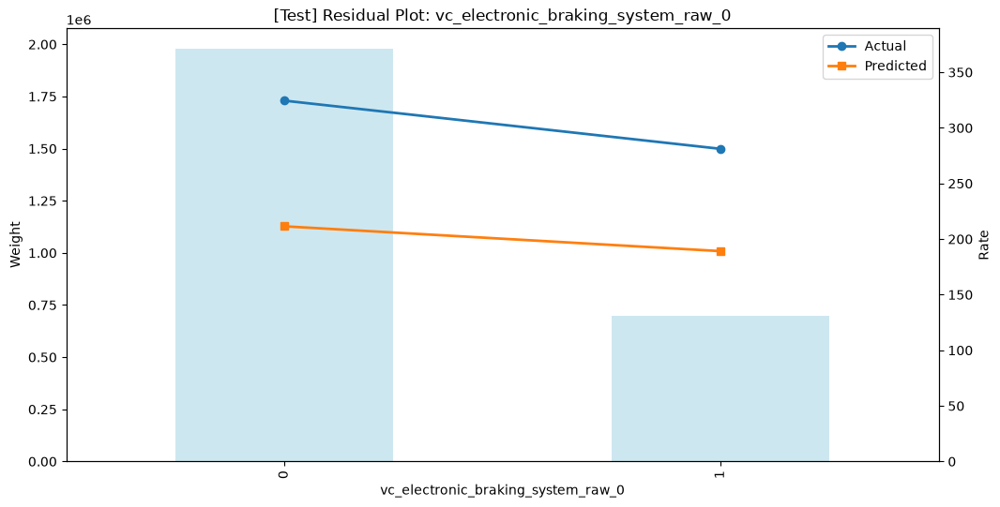

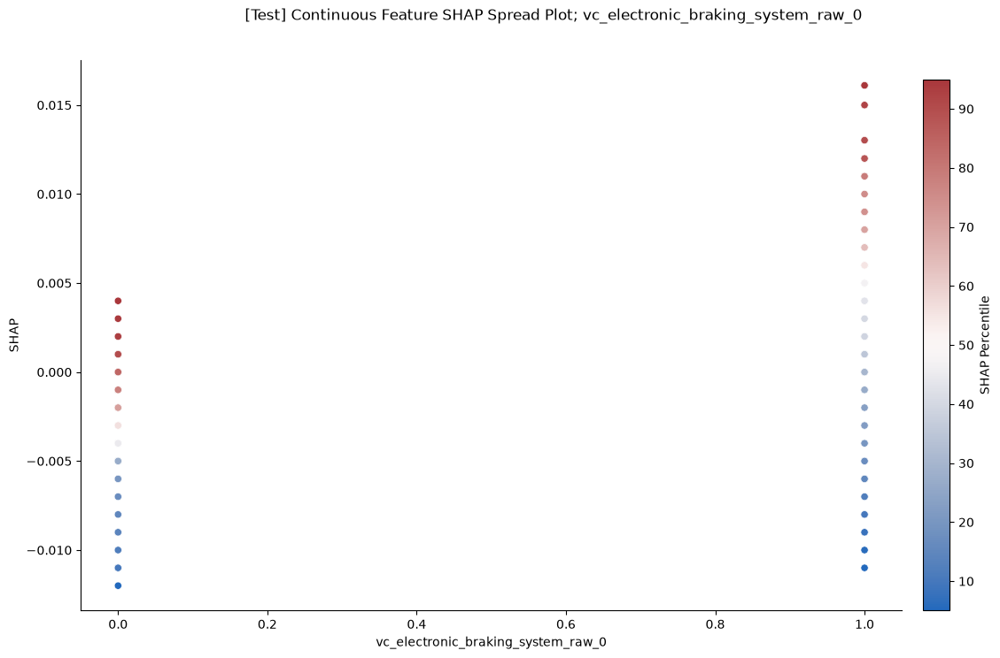


[OK] Displayed 155 plots


In [16]:
from IPython.display import Image, display
print("\n" + "="*60)
print("DISPLAYING ALL PLOTS")
print("="*60)
for f in features:
    if f not in plots_by_feature or not plots_by_feature[f]:
        continue
    print("\n" + "="*60)
    print(f"FEATURE: {f}")
    print("="*60)
    for plot_path in plots_by_feature[f]:
        if Path(plot_path).exists():
            display(Image(filename=plot_path))
        else:
            print(f"WARNING: {plot_path} not found")
print(f"\n[OK] Displayed {sum(len(v) for v in plots_by_feature.values())} plots")

In [17]:
summary["features"] = features
summary["top_n"] = top_n
summary_file = f"{output_base}/results/07_analysis_summary.yaml"
with open(summary_file, "w") as f:
    yaml.dump(summary, f)
print(f"\nSummary: {summary_file}")


Summary: output/car_liab/v1/results/07_analysis_summary.yaml


In [18]:
print("\n" + "#"*40)
print("# STAGE 07: COMPLETE")
print("#"*40)
print(f"Plots: {summary['plots']}")


########################################
# STAGE 07: COMPLETE
########################################
Plots: 155
